In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
import pandas as pd
from torch.utils.data import Dataset
import torch.nn.init as init
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import numpy as np
import os
import random
from PIL import Image
from torchvision import models, transforms, utils
from torchvision.transforms import v2
import re

In [2]:
def learning_curve(train_loss, val_loss):
    epochs = range(1, len(train_loss) + 1)

    plt.plot(epochs, np.array(train_loss), label='Training Loss')
    plt.plot(epochs, np.array(val_loss), label='Validation Loss')

    plt.title('Learning Curve')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.ylim(0, 1)
    plt.legend()
    plt.show()

In [3]:
# Verificar si CUDA está disponible
cuda_available = torch.cuda.is_available()

# Imprimir la versión de PyTorch y la disponibilidad de CUDA
print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {cuda_available}")

# Imprimir el nombre de la GPU si CUDA está disponible
if cuda_available:
    print(f"GPU name: {torch.cuda.get_device_name(0)}")
    # Obtener la versión de CUDA
    cuda_version = torch.version.cuda
    print(f"CUDA version: {cuda_version}")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

PyTorch version: 2.2.0
CUDA available: True
GPU name: NVIDIA GeForce RTX 3050 Laptop GPU
CUDA version: 12.1
Using device: cuda


In [4]:
import os
import pandas as pd

# Directorio que contiene los archivos
directorio = './IMGS_MEDIA_AMPL'

# Obtener la ruta absoluta del directorio
directorio_absoluto = os.path.abspath(directorio)

# Obtener la lista de archivos en el directorio
archivos = os.listdir(directorio_absoluto)

# Crear una lista para almacenar las rutas de los archivos y las etiquetas
data = []

# Iterar sobre los archivos
for archivo in archivos:
    # Obtener la ruta completa del archivo
    ruta_completa = os.path.join(directorio_absoluto, archivo)
    # Obtener los elementos después de hacer split("_")
    elementos = archivo.split("_")
    # Obtener la etiqueta (cuarto elemento)
    etiqueta = elementos[3] if len(elementos) >= 4 else None
    # Agregar la ruta y la etiqueta a la lista de datos
    data.append((ruta_completa, int(etiqueta)))

# Crear el DataFrame de Pandas
df_mean_a = pd.DataFrame(data, columns=['Ruta', 'Etiqueta'])

# Mostrar el DataFrame
print(df_mean_a)

# Especifica la ruta donde deseas guardar el archivo CSV
ruta_csv = './df_mean_a.csv'

# Guarda el DataFrame como un archivo CSV
df_mean_a.to_csv(ruta_csv, index=False)

# # Seleccionamos las características y las etiquetas
# X = df_mean_a['Ruta']
# y = df_mean_a['Etiqueta']

# # Definimos el número de pliegues para la validación cruzada
# num_folds = 5

# from sklearn.model_selection import StratifiedKFold
# # Inicializamos StratifiedKFold
# stratified_kfold = StratifiedKFold(n_splits=num_folds, shuffle=True, random_state=42)

# # Creamos listas para almacenar las proporciones de etiquetas en train y validación
# train_label_proportions = []
# val_label_proportions = []

# # Iteramos sobre cada pliegue
# for train_index, val_index in stratified_kfold.split(X, y):
#     # Obtenemos las etiquetas de entrenamiento y validación
#     y_train, y_val = y.iloc[train_index], y.iloc[val_index]
    
#     # Calculamos las proporciones de etiquetas en entrenamiento y validación
#     train_label_proportion = y_train.value_counts()
#     val_label_proportion = y_val.value_counts()
    
#     # Agregamos las proporciones a las listas
#     train_label_proportions.append(train_label_proportion)
#     val_label_proportions.append(val_label_proportion)


# # Imprimimos las proporciones promedio de etiquetas en train y validación
# print("Proporciones promedio de etiquetas en train:")
# print(pd.DataFrame(train_label_proportions))
# print("\nProporciones promedio de etiquetas en validación:")
# print(pd.DataFrame(val_label_proportions))

                                                  Ruta  Etiqueta
0    c:\Users\da01m\Desktop\TFG\IMGS_MEDIA_AMPL\_P0...         2
1    c:\Users\da01m\Desktop\TFG\IMGS_MEDIA_AMPL\_P0...         4
2    c:\Users\da01m\Desktop\TFG\IMGS_MEDIA_AMPL\_P0...         6
3    c:\Users\da01m\Desktop\TFG\IMGS_MEDIA_AMPL\_P0...         8
4    c:\Users\da01m\Desktop\TFG\IMGS_MEDIA_AMPL\_P0...         2
..                                                 ...       ...
171  c:\Users\da01m\Desktop\TFG\IMGS_MEDIA_AMPL\_P7...         8
172  c:\Users\da01m\Desktop\TFG\IMGS_MEDIA_AMPL\_P7...         1
173  c:\Users\da01m\Desktop\TFG\IMGS_MEDIA_AMPL\_P7...         3
174  c:\Users\da01m\Desktop\TFG\IMGS_MEDIA_AMPL\_P7...         5
175  c:\Users\da01m\Desktop\TFG\IMGS_MEDIA_AMPL\_P7...         7

[176 rows x 2 columns]


[24 20 24 20 24 20 24 20]


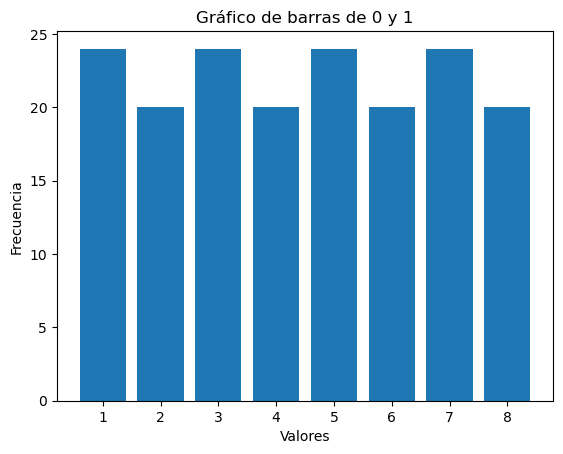

In [5]:
###Ahora debería separar test, tomando 12 imágenes x 4, 48 imágenes en total que realmente son 12 pacientes
etiquetas = df_mean_a["Etiqueta"].to_numpy()

# Contar la cantidad de ceros y unos
_ , contador = np.unique(etiquetas, return_counts=True)
print(contador)

# Etiquetas para las barras
etiquetas = ['1', '2','3','4','5', '6','7','8']

# Crear el gráfico de barras
plt.bar(etiquetas, contador)

# Agregar título y etiquetas a los ejes
plt.title('Gráfico de barras de 0 y 1')
plt.xlabel('Valores')
plt.ylabel('Frecuencia')

# Mostrar el gráfico
plt.show()

                                  Ruta  Etiqueta
0   ./IMGS_MEDIA_AMPL\_P15_HVN_1_1.jpg         1
1   ./IMGS_MEDIA_AMPL\_P15_HVN_3_2.jpg         3
2   ./IMGS_MEDIA_AMPL\_P15_HVN_5_3.jpg         5
3   ./IMGS_MEDIA_AMPL\_P15_HVN_7_4.jpg         7
4   ./IMGS_MEDIA_AMPL\_P60_HVN_2_1.jpg         2
5   ./IMGS_MEDIA_AMPL\_P60_HVN_4_2.jpg         4
6   ./IMGS_MEDIA_AMPL\_P60_HVN_6_3.jpg         6
7   ./IMGS_MEDIA_AMPL\_P60_HVN_8_4.jpg         8
8   ./IMGS_MEDIA_AMPL\_P47_HVN_1_1.jpg         1
9   ./IMGS_MEDIA_AMPL\_P47_HVN_3_2.jpg         3
10  ./IMGS_MEDIA_AMPL\_P47_HVN_5_3.jpg         5
11  ./IMGS_MEDIA_AMPL\_P47_HVN_7_4.jpg         7
12  ./IMGS_MEDIA_AMPL\_P17_HVN_1_1.jpg         1
13  ./IMGS_MEDIA_AMPL\_P17_HVN_3_2.jpg         3
14  ./IMGS_MEDIA_AMPL\_P17_HVN_5_3.jpg         5
15  ./IMGS_MEDIA_AMPL\_P17_HVN_7_4.jpg         7
16  ./IMGS_MEDIA_AMPL\_P26_HVN_1_1.jpg         1
17  ./IMGS_MEDIA_AMPL\_P26_HVN_3_2.jpg         3
18  ./IMGS_MEDIA_AMPL\_P26_HVN_5_3.jpg         5
19  ./IMGS_MEDIA_AMP

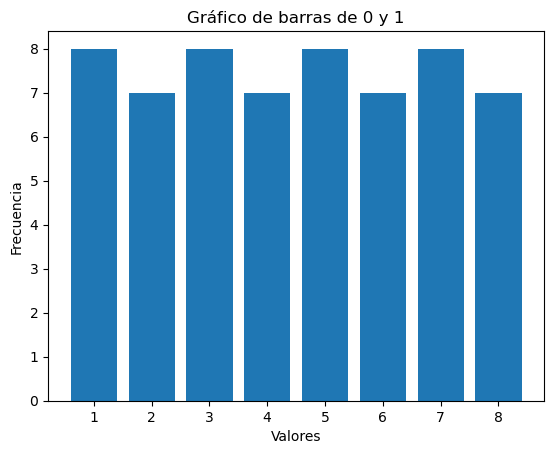

In [6]:
##A partir de aqui, se separa el conjunto de test de forma aleatoria, dada lo balanceadas que están las clases, se espera que test también lo este
from sklearn.model_selection import train_test_split

import random

# Vector de pacientes y de 2 strings
pacientes = [f'{i:02}' for i in range(2, 76)]
strings = ['HVN', 'H9O']
# Número de combinaciones que deseas crear
num_combinaciones = 15
combinaciones_totales = 0
# Lista para almacenar las combinaciones
combinaciones = []

random.seed(20)
 # Obtener la lista de nombres de archivos que coinciden con la expresión regular
nombres_de_archivos = os.listdir('./IMGS_MEDIA_AMPL')  # Reemplaza '*' con el directorio o patrón adecuado si es necesario
# Crear 15 combinaciones aleatorias

while combinaciones_totales < 15:
    # Seleccionar un paciente aleatorio
    
    paciente_aleatorio = random.choice(pacientes)
    
    # Seleccionar un string aleatorio
    string_aleatorio = random.choice(strings)
    
    # Expresión regular para filtrar nombres de archivos
    expresion_regular = rf'_P{paciente_aleatorio}_{string_aleatorio}_'

    # Filtrar los nombres de archivos que coinciden con la expresión regular
    archivos_coincidentes = [nombre_archivo for nombre_archivo in nombres_de_archivos if re.search(expresion_regular, nombre_archivo)]
    if (len(archivos_coincidentes) == 4):
        combinaciones.extend(archivos_coincidentes)
        combinaciones_totales += 1
        pacientes.remove(paciente_aleatorio)

data = []
# Iterar sobre los archivos
for archivo in combinaciones:
    # Obtener la ruta completa del archivo
    ruta_completa = os.path.join(directorio, archivo)
    # Obtener los elementos después de hacer split("_")
    elementos = archivo.split("_")
    # Obtener la etiqueta (cuarto elemento)
    etiqueta = elementos[3] if len(elementos) >= 4 else None
    # Agregar la ruta y la etiqueta a la lista de datos
    data.append((ruta_completa, int(etiqueta)))
        
    nombres_de_archivos.remove(archivo)
    
    
# Crear el DataFrame de Pandas
df_test = pd.DataFrame(data, columns=['Ruta', 'Etiqueta'])

# Mostrar el DataFrame
print(df_test)

###Ahora debería separar test, tomando 12 imágenes x 4, 48 imágenes en total que realmente son 12 pacientes
etiquetas = df_test["Etiqueta"].to_numpy()

# Contar la cantidad de ceros y unos
_ , contador = np.unique(etiquetas, return_counts=True)
print(contador)
print(F"ETIQUETAS 0: {contador[0]/4}*4")
print(F"ETIQUETAS 1: {contador[1]/4}*4")

# Etiquetas para las barras
etiquetas = ['1', '2','3','4','5', '6','7','8']

# Crear el gráfico de barras
plt.bar(etiquetas, contador)

# Agregar título y etiquetas a los ejes
plt.title('Gráfico de barras de 0 y 1')
plt.xlabel('Valores')
plt.ylabel('Frecuencia')

# Mostrar el gráfico
plt.show()


                                   Ruta  Etiqueta
0    ./IMGS_MEDIA_AMPL\_P08_HVN_2_1.jpg         2
1    ./IMGS_MEDIA_AMPL\_P08_HVN_4_2.jpg         4
2    ./IMGS_MEDIA_AMPL\_P08_HVN_6_3.jpg         6
3    ./IMGS_MEDIA_AMPL\_P08_HVN_8_4.jpg         8
4    ./IMGS_MEDIA_AMPL\_P10_HVN_2_1.jpg         2
..                                  ...       ...
111  ./IMGS_MEDIA_AMPL\_P74_H9O_8_4.jpg         8
112  ./IMGS_MEDIA_AMPL\_P75_H9O_1_1.jpg         1
113  ./IMGS_MEDIA_AMPL\_P75_H9O_3_2.jpg         3
114  ./IMGS_MEDIA_AMPL\_P75_H9O_5_3.jpg         5
115  ./IMGS_MEDIA_AMPL\_P75_H9O_7_4.jpg         7

[116 rows x 2 columns]
116
[16 13 16 13 16 13 16 13]


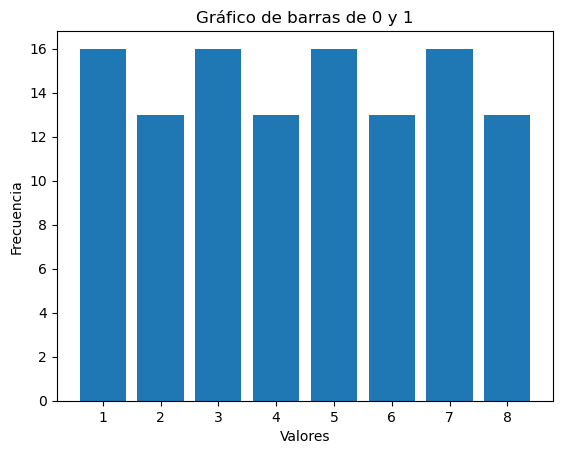

In [7]:
data = []
for archivo in nombres_de_archivos:
    # Obtener la ruta completa del archivo
    ruta_completa = os.path.join(directorio, archivo)
    # Obtener los elementos después de hacer split("_")
    elementos = archivo.split("_")
    # Obtener la etiqueta (cuarto elemento)
    etiqueta = elementos[3] if len(elementos) >= 4 else None
    # Agregar la ruta y la etiqueta a la lista de datos
    data.append((ruta_completa, int(etiqueta)))

# Crear el DataFrame de Pandas
df_train = pd.DataFrame(data, columns=['Ruta', 'Etiqueta'])

# Mostrar el DataFrame
print(df_train)

print(len(df_train))

###Ahora debería separar test, tomando 12 imágenes x 4, 48 imágenes en total que realmente son 12 pacientes
etiquetas = df_train["Etiqueta"].to_numpy()

# Contar la cantidad de ceros y unos
_ , contador = np.unique(etiquetas, return_counts=True)
print(contador)

# Etiquetas para las barras
etiquetas = ['1', '2','3','4','5', '6','7','8']

# Crear el gráfico de barras
plt.bar(etiquetas, contador)

# Agregar título y etiquetas a los ejes
plt.title('Gráfico de barras de 0 y 1')
plt.xlabel('Valores')
plt.ylabel('Frecuencia')

# Mostrar el gráfico
plt.show()


# PRUEBAS GIRD SEARCH

A continuación se presentan una serie de funciones donde se encapsula todo el entrenamiento de un modelo, para 4 formas diferentes de entrenar. Se comentará exhaustivamente esta primera función. Las demás para las distitnas formas de entrenar son similares, cambiando algunas cosas que se comentarán en el código. Lo recomendable, para entender la función, sería leer la primera y compararla con las demás. Además, en cuanto a los parámetros de la función, cuando se entrena con TL, hay un parámetro más ya que se indican dos número de épocas, una para el modelo congelado y otra para el modelo sin congelar.

## FUNCIÓN SIN TL NI OC

In [ ]:
# Función para calcular el accuracy
def accuracy(outputs, labels):
    preds = outputs > 0.5  # Si la salida es mayor que 0.5, se considera una predicción positiva (1), de lo contrario es negativa (0)
    correct = (preds == labels.byte())  # Compara las predicciones con las etiquetas reales para ver cuántas son correctas
    acc = correct.float().sum() / labels.size(0)  # Suma las predicciones correctas y divide por el número total de etiquetas para obtener la precisión
    return acc.item()  # Devuelve la precisión como un valor escalar

# Función para calcular el recall
def recall(outputs, labels):
    preds = outputs > 0.5  # Si la salida es mayor que 0.5, se considera una predicción positiva (1), de lo contrario es negativa (0)

    # Mueve los tensores a la CPU para asegurar la compatibilidad en operaciones subsecuentes
    preds = preds.cpu()
    labels = labels.cpu()

    TP = sum((preds == 1) & (labels == 1))  # Calcula los verdaderos positivos (TP): predicciones positivas que son correctas
    FN = sum((preds == 0) & (labels == 1))  # Calcula los falsos negativos (FN): etiquetas reales positivas que fueron predichas como negativas

    recall_score = TP / (TP + FN) if (TP + FN) > 0 else 0  # Calcula el recall: TP dividido por la suma de TP y FN. Si TP + FN es 0, el recall es 0
    return recall_score  # Devuelve el valor del recall

# Función para calcular la precisión (precision)
def precision(outputs, labels):
    preds = outputs > 0.5  # Si la salida es mayor que 0.5, se considera una predicción positiva (1), de lo contrario es negativa (0)

    # Mueve los tensores a la CPU para asegurar la compatibilidad en operaciones subsecuentes
    preds = preds.cpu()
    labels = labels.cpu()

    TP = sum((preds == 1) & (labels == 1))  # Calcula los verdaderos positivos (TP): predicciones positivas que son correctas
    FP = sum((preds == 1) & (labels == 0))  # Calcula los falsos positivos (FP): predicciones positivas que son incorrectas

    precision_score = TP / (TP + FP) if (TP + FP) > 0 else 0  # Calcula la precisión: TP dividido por la suma de TP y FP. Si TP + FP es 0, la precisión es 0
    return precision_score  # Devuelve el valor de la precisión


#####Parámetros
#####   dataset: el conjunto de datos, siendo una columna la ruta y otra la etiqueta de la imagen
#####   num_folds_outer: el número de folds de test que se ejecutarán
#####   num_epochs: el número total de épocas que se entrenará
#####   op: el optimziador usado
#####   batch_size: tamaño de batch para entrenamiento
#####   lr: learning rate para el optimizador
#####   data_aug: True o False, para si se hace aumento de datos o no
#####   ini: un char representnado uno de los optimizadores que se pueden usar

def prueba_k_fold_resnet_no_pre(dataset, num_folds, num_epochs, op, batch_size, lr, data_aug, ini):
    # Transformaciones para preprocesar las imágenes
    # Verifica si el aumento de datos está activado
    if data_aug:
        transform_t = v2.Compose([
            v2.Resize((224, 224)),  # Redimensiona la imagen a 224x224 píxeles
            v2.RandomHorizontalFlip(),  # Aplica un volteo horizontal aleatorio a la imagen
            v2.RandomVerticalFlip(),  # Aplica un volteo vertical aleatorio a la imagen
            v2.ToImage(),  # Convierte los datos en una imagen
            v2.ToDtype(torch.float32, scale=True),  # Convierte la imagen al tipo de datos float32, escalando los valores
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),  # Normaliza la imagen usando los valores de media y desviación estándar de ImageNet
        ])

        # Transformaciones para los datos de validación (sin aumento de datos)
        transform_v = v2.Compose([
            v2.Resize((224, 224)),  # Redimensiona la imagen a 224x224 píxeles
            v2.ToImage(),  # Convierte los datos en una imagen
            v2.ToDtype(torch.float32, scale=True),  # Convierte la imagen al tipo de datos float32, escalando los valores
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),  # Normaliza la imagen usando los valores de media y desviación estándar de ImageNet
        ])
    else:
        # Transformaciones para los datos de entrenamiento sin aumento de datos
        transform_t = v2.Compose([
            v2.Resize((224, 224)),  # Redimensiona la imagen a 224x224 píxeles
            v2.ToImage(),  # Convierte los datos en una imagen
            v2.ToDtype(torch.float32, scale=True),  # Convierte la imagen al tipo de datos float32, escalando los valores
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),  # Normaliza la imagen usando los valores de media y desviación estándar de ImageNet
        ])

        # Transformaciones para los datos de validación (sin aumento de datos)
        transform_v = v2.Compose([
            v2.Resize((224, 224)),  # Redimensiona la imagen a 224x224 píxeles
            v2.ToImage(),  # Convierte los datos en una imagen
            v2.ToDtype(torch.float32, scale=True),  # Convierte la imagen al tipo de datos float32, escalando los valores
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),  # Normaliza la imagen usando los valores de media y desviación estándar de ImageNet
        ])
    
    
    # Modelo personalizado basado en ResNet
    class CustomResNet(nn.Module):
        def __init__(self, num_classes_binary=1):
            super(CustomResNet, self).__init__()

            # Carga el modelo sin pesos de entrenamiento
            resnet = models.resnet18(weights=None)

            # Extrae todas las capas de la ResNet menos la última capa fully connected
            self.features = nn.Sequential(*list(resnet.children())[:-1])
    
            # Define una nueva capa fully connected para la clasificación binaria
            self.fc_binary = nn.Linear(512, num_classes_binary)
            
            # Inicializa los pesos de la red según el método especificado
            if (ini == "G"):
                self.apply(self.init_weights_glorot)  # Inicialización de Glorot (Xavier)
            elif(ini == "H"):
                self.apply(self.init_weights_he)  # Inicialización de He
            elif (ini == "N"):
                self.apply(self.init_weights_normal)  # Inicialización normal
            elif(ini == "U"):
                self.apply(self.init_weights_uniform)  # Inicialización uniforme
            elif (ini == "O"):
                self.apply(self.init_weights_orthogonal)  # Inicialización ortogonal
            elif(ini == "Z"):
                self.apply(self.init_weights_zeros)  # Inicialización a ceros
            elif(ini == "ON"):
                self.apply(self.init_weights_ones)  # Inicialización a unos

        # Inicialización de pesos con el método de Glorot (Xavier)
        def init_weights_glorot(self, m):
            if isinstance(m, nn.Linear):
                init.xavier_uniform_(m.weight)  # Inicializa los pesos de forma uniforme según Glorot
                if m.bias is not None:
                    init.constant_(m.bias, 0)  # Inicializa los sesgos a cero
    
        # Inicialización de pesos con el método de He
        def init_weights_he(self, m):
            if isinstance(m, nn.Linear):
                init.kaiming_uniform_(m.weight, mode='fan_in', nonlinearity='relu')  # Inicializa los pesos según He
                if m.bias is not None:
                    init.constant_(m.bias, 0)  # Inicializa los sesgos a cero
    
        # Inicialización de pesos con distribución normal
        def init_weights_normal(self, m):
            if isinstance(m, nn.Linear):
                init.normal_(m.weight, mean=0, std=0.01)  # Inicializa los pesos con una distribución normal con media 0 y desviación estándar 0.01
                if m.bias is not None:
                    init.constant_(m.bias, 0)  # Inicializa los sesgos a cero
    
        # Inicialización de pesos con distribución uniforme
        def init_weights_uniform(self, m):
            if isinstance(m, nn.Linear):
                init.uniform_(m.weight, a=-0.1, b=0.1)  # Inicializa los pesos de forma uniforme entre -0.1 y 0.1
                if m.bias is not None:
                    init.constant_(m.bias, 0)  # Inicializa los sesgos a cero
    
        # Inicialización de pesos ortogonal
        def init_weights_orthogonal(self, m):
            if isinstance(m, nn.Linear):
                init.orthogonal_(m.weight)  # Inicializa los pesos de forma ortogonal
                if m.bias is not None:
                    init.constant_(m.bias, 0)  # Inicializa los sesgos a cero
    
        # Inicialización de pesos a ceros
        def init_weights_zeros(self, m):
            if isinstance(m, nn.Linear):
                init.zeros_(m.weight)  # Inicializa todos los pesos a cero
                if m.bias is not None:
                    init.zeros_(m.bias)  # Inicializa los sesgos a cero
    
        # Inicialización de pesos a unos
        def init_weights_ones(self, m):
            if isinstance(m, nn.Linear):
                init.ones_(m.weight)  # Inicializa todos los pesos a uno
                if m.bias is not None:
                    init.ones_(m.bias)  # Inicializa los sesgos a uno
    
        # Método forward para el paso de la red
        def forward(self, x):
            x = self.features(x)  # Pasa la entrada a través de la parte de características de la red
            x = x.view(x.size(0), -1)  # Aplana las características a un vector de 1D para la capa fully connected
    
            # Pasa la salida a través de la capa fully connected personalizada para la clasificación binaria
            out_binary = self.fc_binary(x)
    
            return out_binary  # Devuelve la salida para la clasificación binaria
    
    # Define una clase personalizada para el conjunto de datos
    class CustomDataset(Dataset):
        def __init__(self, dataframe, transform=None):
            """
            Inicializa el conjunto de datos personalizado.

            Args:
                dataframe (pd.DataFrame): DataFrame que contiene rutas a las imágenes y etiquetas.
                transform (callable, optional): Transformaciones que se aplicarán a cada imagen.
            """
            self.data = dataframe  # Almacena el DataFrame con rutas y etiquetas
            self.transform = transform  # Almacena las transformaciones, si se proporcionan
    
        def __len__(self):
            """
            Devuelve la longitud del conjunto de datos.

            Returns:
                int: Número de ejemplos en el conjunto de datos.
            """
            return len(self.data)  # Retorna el número de filas en el DataFrame
    
        def __getitem__(self, idx):
            """
            Obtiene una imagen y su etiqueta correspondiente por índice.

            Args:
                idx (int): Índice del ejemplo a obtener.

            Returns:
                tuple: Una imagen transformada y su etiqueta binaria.
            """
            # Obtiene la ruta de la imagen de la primera columna del DataFrame
            img_path = self.data.iloc[idx, 0]

            # Abre la imagen usando PIL y la convierte a RGB
            image = Image.open(img_path).convert('RGB')

            # Obtiene la etiqueta binaria de la segunda columna del DataFrame y la convierte a tensor
            label_binary = torch.tensor(self.data.iloc[idx, 1], dtype=torch.float32)

            # Aplica las transformaciones a la imagen, si están definidas
            if self.transform:
                image = self.transform(image)

            # Retorna la imagen (posiblemente transformada) y la etiqueta binaria
            return image, label_binary
        
    #####5 fold CV
    from sklearn.model_selection import StratifiedKFold
    
    # Definir el número de folds
    criterion_binary = nn.BCEWithLogitsLoss()
    kf = StratifiedKFold(n_splits=num_folds, shuffle=True, random_state=33)
    
    # Listas para almacenar las pérdidas de entrenamiento y validación de cada fold
    train_losses_folds = []
    val_losses_folds = []
    
    train_accs_folds = []
    train_rec_folds =  []
    train_preci_folds = []

    val_accs_folds = []
    val_rec_folds =  []
    val_preci_folds = []
    
    # Itera sobre cada fold generado por StratifiedKFold
    for fold, (train_index, val_index) in enumerate(kf.split(np.zeros(len(dataset)),dataset['Etiqueta'])):
        print(f"Fold {fold + 1}")
    
        # Dividir el conjunto de datos en entrenamiento y validación para este fold
        train_data_fold = dataset.iloc[train_index]
        val_data_fold = dataset.iloc[val_index]
    
        # Crear instancias del conjunto de datos personalizado para este fold
        train_dataset_fold = CustomDataset(dataframe=train_data_fold, transform=transform_t)
        val_dataset_fold = CustomDataset(dataframe=val_data_fold, transform=transform_v)
    
        # Crear DataLoader para cargar los datos en lotes
        train_loader_fold = DataLoader(dataset=train_dataset_fold, batch_size=batch_size, shuffle=True)
        val_loader_fold = DataLoader(dataset=val_dataset_fold, batch_size=len(val_dataset_fold), shuffle=False) 
    
        # Re-inicializar el modelo para cada fold
        model = CustomResNet(num_classes_binary=1).to(device)

        ##En este forma de entrenar, solo un optimizador
        optimizer = op(model.parameters(), lr = lr)
        # Entrenamiento y validación para este fold
        train_losses_fold = []
        val_losses_fold = []
        train_accuracy_fold = []
        val_accuracy_fold = []
        train_recall_fold = []
        val_recall_fold = []
        train_preci_fold = []
        val_preci_fold = []

        for epoch in range(num_epochs):
            # Entrenamiento del modelo
            # Fase de entrenamiento
            model.train()
            loss_total_acumulada = 0.0
            lossT_bin_total = 0.0
            correct_train = 0
            recall_value_train = 0
            precision_value_train = 0
            for images, bin_label in train_loader_fold:

                ### Se adaptan todas las etiquetas para que sean 0 o 1, según si es impar o par respectivamente
                for i,lab in enumerate(bin_label):
                        if lab%2==0:
                            bin_label[i] = 1
                        else:
                            bin_label[i] = 0
                images, bin_label = images.to(device), bin_label.to(device)

                # Reiniciar gradientes
                optimizer.zero_grad()
        
                # Forward pass
                bin_out = model(images)                
        
        
                # Calcular pérdida para la variable binaria
                lossT_bin = criterion_binary(bin_out.squeeze(1), bin_label)
        
                # Pérdida total
                loss_total = lossT_bin
    
                loss_total_acumulada += loss_total
    
                # Backward pass y optimización
                loss_total.backward()
                optimizer.step()

                #Calculo de otras métricas
                bin_pred = torch.sigmoid(bin_out.squeeze())
                correct_train += accuracy(bin_pred, bin_label)
                recall_value_train += recall(bin_pred, bin_label)
                precision_value_train += precision(bin_pred, bin_label)

        
    
            # Validación del modelo
            model.eval()
            val_loss = 0.0
            correct_valid = 0
            recall_value_valid = 0
            precision_value_valid = 0
            lossV_bin_total = 0.0
            with torch.no_grad():
                for images, bin_label in val_loader_fold:
                    ##Se vuelven a adaptar las etiquetas
                    for i,lab in enumerate(bin_label):
                        if lab%2==0:
                            bin_label[i] = 1
                        else:
                            bin_label[i] = 0
                    images,  bin_label = images.to(device),  bin_label.to(device)
                    # Forward pass en el conjunto de validación
                    bin_out = model(images)
    
    
    
                    # Calcular pérdida para la variable binaria
                    lossV_bin = criterion_binary(bin_out.squeeze(1), bin_label)
    
                    # Sumar las pérdidas del conjunto de validación
                    val_loss += lossV_bin.item()

                    #Cálculo de otras métricas
                    bin_pred = torch.sigmoid(bin_out.squeeze())
                    correct_valid += accuracy(bin_pred, bin_label)
                    recall_value_valid += recall(bin_pred, bin_label)
                    precision_value_valid += precision(bin_pred, bin_label)
                    
            
            ### Se promedian los resultados teniendo en cuenta el número de lotes y se actualizan listas
            avg_loss_total_acumulada = loss_total_acumulada / len(train_loader_fold)
            train_losses_fold.append(avg_loss_total_acumulada)
            acc_train = correct_train / len(train_loader_fold)
            recall_train = recall_value_train / len(train_loader_fold)
            precision_train = precision_value_train / len(train_loader_fold)
            train_accuracy_fold.append(acc_train)
            train_recall_fold.append(recall_train)
            train_preci_fold.append(precision_train)
        
            avg_val_loss = val_loss / len(val_loader_fold)
            val_losses_fold.append(avg_val_loss)
            acc_valid = correct_valid / len(val_loader_fold)
            recall_valid = recall_value_valid / len(val_loader_fold)
            precision_valid = precision_value_valid / len(val_loader_fold)
            val_accuracy_fold.append(acc_valid)
            val_recall_fold.append(recall_valid)
            val_preci_fold.append(precision_valid)
            # print(f'Epoch [{epoch+1}/{num_epochs}], Training Loss: {avg_loss_total_acumulada.item()}, Validation Loss: {avg_val_loss}')
        
      
        
        train_accs_folds.append(np.mean(train_accuracy_fold))
        train_rec_folds.append(np.mean(train_recall_fold))
        train_preci_folds.append(np.mean(train_preci_fold))

        val_accs_folds.append(np.mean(val_accuracy_fold))
        val_rec_folds.append(np.mean(val_recall_fold))
        val_preci_folds.append(np.mean(val_preci_fold))

        train_losses_folds.append(train_losses_fold)
        val_losses_folds.append(val_losses_fold)
        train_losses_fold = [i.cpu().detach().numpy() for i in train_losses_fold]
    
    train_losses_folds_cpu = []
    val_losses_folds_cpu = []

    ##Movemos a cpu el contenido de las listas
    for losses in val_losses_folds:
        val_losses_fold_cpu = []
        for loss in losses:
            val_losses_fold_cpu.append(loss)
        val_losses_folds_cpu.append(np.array(val_losses_fold_cpu))
    for losses in train_losses_folds:
        train_losses_fold_cpu = []
        for loss in losses:
            train_losses_fold_cpu.append(float(loss.cpu().detach().numpy()))
        train_losses_folds_cpu.append(np.array(train_losses_fold_cpu))
    
    avg_train = []
    avg_val = []
    for losses in train_losses_folds_cpu:
        avg_train.append(np.mean(losses))
    for losses in val_losses_folds_cpu:
        avg_val.append(np.mean(losses))
        
    ##Se devuelve pérdida, accuracy, recall y precision, aunque esta última no se usará
    return np.mean(avg_val), np.mean(val_accs_folds), np.mean(val_rec_folds), np.mean(val_preci_folds)
    

## FUNCIÓN SIN TL CON OC

In [ ]:
def accuracy(outputs, labels):
    preds = outputs > 0.5  # Si la salida es mayor que 0.5, consideramos que es positiva
    correct = (preds == labels.byte())  # Compara las predicciones con las etiquetas reales
    acc = correct.float().sum() / labels.size(0)  # Calcula la precisión
    return acc.item()

def recall(outputs, labels):
    preds = outputs > 0.5

    preds = preds.cpu()
    labels = labels.cpu()
    TP = sum((preds == 1) & (labels == 1))
    FN = sum((preds == 0) & (labels == 1))
    
    recall_score = TP / (TP + FN) if (TP + FN) > 0 else 0
    return recall_score

def precision(outputs, labels):
    preds = outputs > 0.5

    preds = preds.cpu()
    labels = labels.cpu()

    TP = sum((preds == 1) & (labels == 1))
    FP = sum((preds == 1) & (labels == 0))
    
    precision_score = TP / (TP + FP) if (TP + FP) > 0 else 0
    return precision_score

def prueba_k_fold_resnet_no_pre_oc(dataset, num_folds, num_epochs, op, batch_size, lr, data_aug, ini):
    # Transformaciones para preprocesar las imágenes
    if data_aug:
        transform_t = v2.Compose([
            v2.Resize((224, 224)),
            v2.RandomHorizontalFlip(),
            v2.RandomVerticalFlip(),
            v2.ToImage(), 
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])

        transform_v = v2.Compose([
            v2.Resize((224, 224)),
            v2.ToImage(), 
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])
    else:
        transform_t = v2.Compose([
            v2.Resize((224, 224)),
            v2.ToImage(), 
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])

        transform_v = v2.Compose([
            v2.Resize((224, 224)),
            v2.ToImage(), 
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])
    
    # Modelo personalizado basado en ResNet
    class CustomResNet(nn.Module):
        def __init__(self, num_classes_binary=1):
            super(CustomResNet, self).__init__()
            resnet = models.resnet18(weights=None)# New weights with accuracy 80.858%
            # Extraer las capas de la red ResNet, excluyendo la capa de clasificación
            self.features = nn.Sequential(*list(resnet.children())[:-1])
    
            # Personalizar la capa de salida para tus necesidades
            self.fc_binary = nn.Linear(512, num_classes_binary)
            
            if (ini== "G"):
                # Inicialización de Glorot para las capas fully connected
                self.apply(self.init_weights_glorot)
            elif(ini == "H"):
                self.apply(self.init_weights_he)

        def init_weights_glorot(self, m):
            if isinstance(m, nn.Linear):
                init.xavier_uniform_(m.weight)
                if m.bias is not None:
                    init.constant_(m.bias, 0)

        def init_weights_he(self, m):
            if isinstance(m, nn.Linear):
                init.kaiming_uniform_(m.weight, mode='fan_in', nonlinearity='relu')
                if m.bias is not None:
                    init.constant_(m.bias, 0)
    
        def forward(self, x):
            x = self.features(x)
            x = x.view(x.size(0), -1)
    
    
            # Salida para la variable binaria
            out_binary = self.fc_binary(x)
    
            return out_binary
    
    # Definir una clase para el conjunto de datos personalizado
    class CustomDataset(Dataset):
        def __init__(self, dataframe, transform=None):
            self.data = dataframe
            self.transform = transform
    
        def __len__(self):
            return len(self.data)
    
        def __getitem__(self, idx):
            img_path = self.data.iloc[idx, 0]  # Ruta de la imagen en la primera columna
            image = Image.open(img_path).convert('RGB')
            # Etiquetas: una variable binaria
            label_binary = torch.tensor(self.data.iloc[idx, 1], dtype=torch.float32)
    
            if self.transform:
                image = self.transform(image)
    
            return image, label_binary
        
    #####5 fold CV
    from sklearn.model_selection import StratifiedKFold
    
    # Definir el número de folds
    criterion_binary = nn.BCEWithLogitsLoss()
    kf = StratifiedKFold(n_splits=num_folds, shuffle=True, random_state=33)
    
    # Listas para almacenar las pérdidas de entrenamiento y validación de cada fold
    train_losses_folds = []
    val_losses_folds = []
    
    train_accs_folds = []
    train_rec_folds =  []
    train_preci_folds = []

    val_accs_folds = []
    val_rec_folds =  []
    val_preci_folds = []
    # Iterar sobre los folds
    for fold, (train_index, val_index) in enumerate(kf.split(np.zeros(len(dataset)),dataset['Etiqueta'])):
        print(f"Fold {fold + 1}")
    
        # Dividir el conjunto de datos en entrenamiento y validación para este fold
        train_data_fold = dataset.iloc[train_index]
        val_data_fold = dataset.iloc[val_index]
    
        # Crear instancias del conjunto de datos personalizado para este fold
        train_dataset_fold = CustomDataset(dataframe=train_data_fold, transform=transform_t)
        val_dataset_fold = CustomDataset(dataframe=val_data_fold, transform=transform_v)
    
        # Crear DataLoader para cargar los datos en lotes
        train_loader_fold = DataLoader(dataset=train_dataset_fold, batch_size=batch_size, shuffle=True)
        val_loader_fold = DataLoader(dataset=val_dataset_fold, batch_size=len(val_dataset_fold), shuffle=False) 
    
        # Re-inicializar el modelo para cada fold
        model = CustomResNet(num_classes_binary=1).to(device)

        #####!!!!!!!!!!!!!!!!!!!!!!!######
        ####Esta es una de las diferencias con el código de la función anterior, se implementa un scheduler para la política de ciclo único que se llamará después del optimizador
        optimizer = op(model.parameters(), lr = lr)
        scheduler = optim.lr_scheduler.OneCycleLR(optimizer, max_lr=lr, steps_per_epoch=len(train_loader_fold), epochs=num_epochs)
        # Entrenamiento y validación para este fold
        train_losses_fold = []
        val_losses_fold = []
        train_accuracy_fold = []
        val_accuracy_fold = []
        train_recall_fold = []
        val_recall_fold = []
        train_preci_fold = []
        val_preci_fold = []

        for epoch in range(num_epochs):
            # Entrenamiento del modelo
            # Fase de entrenamiento
            model.train()
            loss_total_acumulada = 0.0
            lossT_bin_total = 0.0
            correct_train = 0
            recall_value_train = 0
            precision_value_train = 0
            for images, bin_label in train_loader_fold:
                for i,lab in enumerate(bin_label):
                        if lab%2==0:
                            bin_label[i] = 1
                        else:
                            bin_label[i] = 0
                # Reiniciar gradientes
                images, bin_label = images.to(device), bin_label.to(device)
        
                optimizer.zero_grad()
        
                # Forward pass
                bin_out = model(images)                
        
        
                # Calcular pérdida para la variable binaria
                lossT_bin = criterion_binary(bin_out.squeeze(1), bin_label)
        
                # Pérdida total
                loss_total = lossT_bin
    
                loss_total_acumulada += loss_total
    
                # Backward pass y optimización
                loss_total.backward()
                optimizer.step()
                scheduler.step()

                bin_pred = torch.sigmoid(bin_out.squeeze())
                correct_train += accuracy(bin_pred, bin_label)
                recall_value_train += recall(bin_pred, bin_label)
                precision_value_train += precision(bin_pred, bin_label)

        
    
            # Validación del modelo
            model.eval()
            val_loss = 0.0
            correct_valid = 0
            recall_value_valid = 0
            precision_value_valid = 0
            lossV_bin_total = 0.0
            with torch.no_grad():
                for images, bin_label in val_loader_fold:
                    for i,lab in enumerate(bin_label):
                        if lab%2==0:
                            bin_label[i] = 1
                        else:
                            bin_label[i] = 0
                    images,  bin_label = images.to(device),  bin_label.to(device)
                    # Forward pass en el conjunto de validación
                    bin_out = model(images)
    
    
    
                    # Calcular pérdida para la variable binaria
                    lossV_bin = criterion_binary(bin_out.squeeze(1), bin_label)
    
                    # Sumar las pérdidas del conjunto de validación
                    val_loss += lossV_bin.item()

                    bin_pred = torch.sigmoid(bin_out.squeeze())
                    correct_valid += accuracy(bin_pred, bin_label)
                    recall_value_valid += recall(bin_pred, bin_label)
                    precision_value_valid += precision(bin_pred, bin_label)
                    
            
            
            avg_loss_total_acumulada = loss_total_acumulada / len(train_loader_fold)
            train_losses_fold.append(avg_loss_total_acumulada)
            acc_train = correct_train / len(train_loader_fold)
            recall_train = recall_value_train / len(train_loader_fold)
            precision_train = precision_value_train / len(train_loader_fold)
            train_accuracy_fold.append(acc_train)
            train_recall_fold.append(recall_train)
            train_preci_fold.append(precision_train)
        
            avg_val_loss = val_loss / len(val_loader_fold)
            val_losses_fold.append(avg_val_loss)
            acc_valid = correct_valid / len(val_loader_fold)
            recall_valid = recall_value_valid / len(val_loader_fold)
            precision_valid = precision_value_valid / len(val_loader_fold)
            val_accuracy_fold.append(acc_valid)
            val_recall_fold.append(recall_valid)
            val_preci_fold.append(precision_valid)
        
      
        
        train_accs_folds.append(np.mean(train_accuracy_fold))
        train_rec_folds.append(np.mean(train_recall_fold))
        train_preci_folds.append(np.mean(train_preci_fold))

        val_accs_folds.append(np.mean(val_accuracy_fold))
        val_rec_folds.append(np.mean(val_recall_fold))
        val_preci_folds.append(np.mean(val_preci_fold))

        train_losses_folds.append(train_losses_fold)
        val_losses_folds.append(val_losses_fold)
        train_losses_fold = [i.cpu().detach().numpy() for i in train_losses_fold]
    
    train_losses_folds_cpu = []
    val_losses_folds_cpu = []
    for losses in val_losses_folds:
        val_losses_fold_cpu = []
        for loss in losses:
            val_losses_fold_cpu.append(loss)
        val_losses_folds_cpu.append(np.array(val_losses_fold_cpu))
    for losses in train_losses_folds:
        train_losses_fold_cpu = []
        for loss in losses:
            train_losses_fold_cpu.append(float(loss.cpu().detach().numpy()))
        train_losses_folds_cpu.append(np.array(train_losses_fold_cpu))
    avg_train = []
    avg_val = []
    for losses in train_losses_folds_cpu:
        avg_train.append(np.mean(losses))
    for losses in val_losses_folds_cpu:
        avg_val.append(np.mean(losses))
    
    return np.mean(avg_val), np.mean(val_accs_folds), np.mean(val_rec_folds), np.mean(val_preci_folds)
    

## FUNCIÓN CON TL SIN OC

In [ ]:

def accuracy(outputs, labels):
    preds = outputs > 0.5  # Si la salida es mayor que 0.5, consideramos que es positiva
    correct = (preds == labels.byte())  # Compara las predicciones con las etiquetas reales
    acc = correct.float().sum() / labels.size(0)  # Calcula la precisión
    return acc.item()

def recall(outputs, labels):
    preds = outputs > 0.5

    preds = preds.cpu()
    labels = labels.cpu()
    TP = sum((preds == 1) & (labels == 1))
    FN = sum((preds == 0) & (labels == 1))
    
    recall_score = TP / (TP + FN) if (TP + FN) > 0 else 0
    return recall_score

def precision(outputs, labels):
    preds = outputs > 0.5

    preds = preds.cpu()
    labels = labels.cpu()

    TP = sum((preds == 1) & (labels == 1))
    FP = sum((preds == 1) & (labels == 0))
    
    precision_score = TP / (TP + FP) if (TP + FP) > 0 else 0
    return precision_score


###Aquí el número de épocas se separa en dos
def prueba_k_fold_resnet_pre(dataset, num_folds, num_epochs_freeze, num_epochs_all, op, batch_size, lr, data_aug, ini):
    # Transformaciones para preprocesar las imágenes
    if data_aug:
        transform_t = v2.Compose([
            v2.Resize((224, 224)),
            # v2.RandomResizedCrop(224),
            v2.RandomHorizontalFlip(),
            v2.RandomVerticalFlip(),
            # v2.ElasticTransform(alpha=250.0),
            # v2.RandomRotation(45),
            # transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.2),
            v2.ToImage(), 
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])

        transform_v = v2.Compose([
            v2.Resize((224, 224)),
            v2.ToImage(), 
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])
    else:
        transform_t = v2.Compose([
            v2.Resize((224, 224)),
            v2.ToImage(), 
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])

        transform_v = v2.Compose([
            v2.Resize((224, 224)),
            v2.ToImage(), 
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])
    
    # Modelo personalizado basado en ResNet
    class CustomResNet(nn.Module):
        def __init__(self, num_classes_binary=1):
            super(CustomResNet, self).__init__()
            resnet = models.resnet18(weights='IMAGENET1K_V1')
            # Extraer las capas de la red ResNet, excluyendo la capa de clasificación
            self.features = nn.Sequential(*list(resnet.children())[:-1])

            # Congelar capas preentrenadas
            for param in self.features.parameters():
                param.requires_grad = False

            # Personalizar la capa de salida para tus necesidades
            self.fc_binary = nn.Linear(512, num_classes_binary)
            
            if (ini== "G"):
                # Inicialización de Glorot para las capas fully connected
                self.apply(self.init_weights_glorot)
            elif(ini == "H"):
                self.apply(self.init_weights_he)
            elif (ini== "N"):
                self.apply(self.init_weights_normal)
            elif(ini == "U"):
                self.apply(self.init_weights_uniform)
            elif (ini== "O"):
                self.apply(self.init_weights_orthogonal)
            elif(ini == "Z"):
                self.apply(self.init_weights_zeros)
            elif(ini == "ON"):
                self.apply(self.init_weights_ones)

        def init_weights_glorot(self, m):
            if isinstance(m, nn.Linear):
                init.xavier_uniform_(m.weight)
                if m.bias is not None:
                    init.constant_(m.bias, 0)

        def init_weights_he(self, m):
            if isinstance(m, nn.Linear):
                init.kaiming_uniform_(m.weight, mode='fan_in', nonlinearity='relu')
                if m.bias is not None:
                    init.constant_(m.bias, 0)
        def init_weights_normal(self, m):
            if isinstance(m, nn.Linear):
                init.normal_(m.weight, mean=0, std=0.01)  
                if m.bias is not None:
                    init.constant_(m.bias, 0)

        def init_weights_uniform(self, m):
            if isinstance(m, nn.Linear):
                init.uniform_(m.weight, a=-0.1, b=0.1)  
                if m.bias is not None:
                    init.constant_(m.bias, 0)
    
        def init_weights_orthogonal(self, m):
            if isinstance(m, nn.Linear):
                init.orthogonal_(m.weight)  
                if m.bias is not None:
                    init.constant_(m.bias, 0)
    
        def init_weights_zeros(self, m):
            if isinstance(m, nn.Linear):
                init.zeros_(m.weight)
                if m.bias is not None:
                    init.zeros_(m.bias)
    
        def init_weights_ones(self, m):
            if isinstance(m, nn.Linear):
                init.ones_(m.weight)
                if m.bias is not None:
                    init.ones_(m.bias)
    
        def forward(self, x):
            x = self.features(x)
            x = x.view(x.size(0), -1)
    
    
            # Salida para la variable binaria
            out_binary = self.fc_binary(x)
    
            return out_binary
    
    # Definir una clase para el conjunto de datos personalizado
    class CustomDataset(Dataset):
        def __init__(self, dataframe, transform=None):
            self.data = dataframe
            self.transform = transform
    
        def __len__(self):
            return len(self.data)
    
        def __getitem__(self, idx):
            img_path = self.data.iloc[idx, 0]  # Ruta de la imagen en la primera columna
            image = Image.open(img_path).convert('RGB')
            # Etiquetas: una variable binaria
            label_binary = torch.tensor(self.data.iloc[idx, 1], dtype=torch.float32)
    
            if self.transform:
                image = self.transform(image)
    
            return image, label_binary
        
    #####5 fold CV
    from sklearn.model_selection import StratifiedKFold
    
    # Definir el número de folds
    criterion_binary = nn.BCEWithLogitsLoss()
    kf = StratifiedKFold(n_splits=num_folds, shuffle=True, random_state=33)
    
    # Listas para almacenar las pérdidas de entrenamiento y validación de cada fold
    train_losses_folds = []
    val_losses_folds = []
    
    train_accs_folds = []
    train_rec_folds =  []
    train_preci_folds = []

    val_accs_folds = []
    val_rec_folds =  []
    val_preci_folds = []
    # Iterar sobre los folds
    for fold, (train_index, val_index) in enumerate(kf.split(np.zeros(len(dataset)),dataset['Etiqueta'])):
        print(f"Fold {fold + 1}")
    
        # Dividir el conjunto de datos en entrenamiento y validación para este fold
        train_data_fold = dataset.iloc[train_index]
        val_data_fold = dataset.iloc[val_index]
    
        # Crear instancias del conjunto de datos personalizado para este fold
        train_dataset_fold = CustomDataset(dataframe=train_data_fold, transform=transform_t)
        val_dataset_fold = CustomDataset(dataframe=val_data_fold, transform=transform_v)
    
        # Crear DataLoader para cargar los datos en lotes
        train_loader_fold = DataLoader(dataset=train_dataset_fold, batch_size=batch_size, shuffle=True)
        val_loader_fold = DataLoader(dataset=val_dataset_fold, batch_size=len(val_dataset_fold), shuffle=False) 
    
        # Re-inicializar el modelo para cada fold
        model = CustomResNet(num_classes_binary=1).to(device)
        ####!!!!!!!!!!!!!!!!#####
        ###Esto es otra diferencia con la primera función, se tienen dos optimizadores puesto que el entrenamiento se realizará en dos partes,
        ###una con los pesos bloqueados (no se actualizan, excepto los de la capa FC) y otra sin ellos (se actualizan todos). Es por ello que, a uno de ellos 
        ###se le pasan como parámetros todos los parámetros del modelo y al otro solo los de la FC.
        optimizer = op(model.parameters(), lr = lr)
        optimizer2 = op(model.fc_binary.parameters(), lr = lr)
        # Entrenamiento y validación para este fold
        train_losses_fold = []
        val_losses_fold = []
        train_accuracy_fold = []
        val_accuracy_fold = []
        train_recall_fold = []
        val_recall_fold = []
        train_preci_fold = []
        val_preci_fold = []

        for epoch in range(num_epochs_freeze):
            # Entrenamiento del modelo
            # Fase de entrenamiento
            model.train()
            loss_total_acumulada = 0.0
            lossT_bin_total = 0.0
            correct_train = 0
            recall_value_train = 0
            precision_value_train = 0
            for images, bin_label in train_loader_fold:
                
                for i,lab in enumerate(bin_label):
                    if lab%2==0:
                        bin_label[i] = 1
                    else:
                        bin_label[i] = 0
                images, bin_label = images.to(device), bin_label.to(device)

                

                optimizer2.zero_grad()
        
                # Forward pass
                bin_out = model(images)                
        
        
                # Calcular pérdida para la variable binaria
                lossT_bin = criterion_binary(bin_out.squeeze(1), bin_label)
        
                # Pérdida total
                loss_total = lossT_bin
    
                loss_total_acumulada += loss_total
    
                # Backward pass y optimización
                loss_total.backward()
                optimizer2.step()

                bin_pred = torch.sigmoid(bin_out.squeeze())
                correct_train += accuracy(bin_pred, bin_label)
                recall_value_train += recall(bin_pred, bin_label)
                precision_value_train += precision(bin_pred, bin_label)

        
    
            # Validación del modelo
            model.eval()
            val_loss = 0.0
            correct_valid = 0
            recall_value_valid = 0
            precision_value_valid = 0
            lossV_bin_total = 0.0
            with torch.no_grad():
                for images, bin_label in val_loader_fold:
                    for i,lab in enumerate(bin_label):
                        if lab%2==0:
                            bin_label[i] = 1
                        else:
                            bin_label[i] = 0
                    images,  bin_label = images.to(device),  bin_label.to(device)
                    # Forward pass en el conjunto de validación
                    bin_out = model(images)
    
                    # Calcular pérdida para la variable binaria
                    lossV_bin = criterion_binary(bin_out.squeeze(1), bin_label)
    
                    # Sumar las pérdidas del conjunto de validación
                    val_loss += lossV_bin.item()

                    bin_pred = torch.sigmoid(bin_out.squeeze())
                    correct_valid += accuracy(bin_pred, bin_label)
                    recall_value_valid += recall(bin_pred, bin_label)
                    precision_value_valid += precision(bin_pred, bin_label)
                    
            
            ###El proceso de las pérdidas y métricas se hará ahora y después otra vez, tras entrenar con las capas descongeladas
            avg_loss_total_acumulada = loss_total_acumulada / len(train_loader_fold)
            train_losses_fold.append(avg_loss_total_acumulada)
            acc_train = correct_train / len(train_loader_fold)
            recall_train = recall_value_train / len(train_loader_fold)
            precision_train = precision_value_train / len(train_loader_fold)
            train_accuracy_fold.append(acc_train)
            train_recall_fold.append(recall_train)
            train_preci_fold.append(precision_train)

            avg_val_loss = val_loss / len(val_loader_fold)
            val_losses_fold.append(avg_val_loss)
            acc_valid = correct_valid / len(val_loader_fold)
            recall_valid = recall_value_valid / len(val_loader_fold)
            precision_valid = precision_value_valid / len(val_loader_fold)
            val_accuracy_fold.append(acc_valid)
            val_recall_fold.append(recall_valid)
            val_preci_fold.append(precision_valid)

        ##Se descongelan todas
        for param in model.features.parameters():
            param.requires_grad = True
            
        for epoch in range(num_epochs_freeze, num_epochs_freeze + num_epochs_all):
            # Entrenamiento del modelo
            # Fase de entrenamiento
            model.train()
            loss_total_acumulada = 0.0
            lossT_bin_total = 0.0
            correct_train = 0
            recall_value_train = 0
            precision_value_train = 0
            for images, bin_label in train_loader_fold:
                # Reiniciar gradientes
                for i,lab in enumerate(bin_label):
                    if lab%2==0:
                        bin_label[i] = 1
                    else:
                        bin_label[i] = 0

                images, bin_label = images.to(device), bin_label.to(device)

                optimizer.zero_grad()
        
                # Forward pass
                bin_out = model(images)
        
                # Calcular pérdida para las variables continuas
                
        
        
                # Calcular pérdida para la variable binaria
                lossT_bin = criterion_binary(bin_out.squeeze(1), bin_label)
        
                # Pérdida total
                loss_total = lossT_bin
    
                loss_total_acumulada += loss_total
    
                # Backward pass y optimización
                loss_total.backward()
                optimizer.step()

                bin_pred = torch.sigmoid(bin_out.squeeze())
                correct_train += accuracy(bin_pred, bin_label)
                recall_value_train += recall(bin_pred, bin_label)
                precision_value_train += precision(bin_pred, bin_label)

        
    
            # Validación del modelo
            model.eval()
            val_loss = 0.0
            correct_valid = 0
            recall_value_valid = 0
            precision_value_valid = 0
            lossV_bin_total = 0.0
            with torch.no_grad():
                for images, bin_label in val_loader_fold:
                    for i,lab in enumerate(bin_label):
                        if lab%2==0:
                            bin_label[i] = 1
                        else:
                            bin_label[i] = 0
                    images,  bin_label = images.to(device),  bin_label.to(device)
                    # Forward pass en el conjunto de validación
                    bin_out = model(images)
        
                    # Calcular pérdida para la variable binaria
                    lossV_bin = criterion_binary(bin_out.squeeze(1), bin_label)
    
                    # Sumar las pérdidas del conjunto de validación
                    val_loss += lossV_bin.item()

                    bin_pred = torch.sigmoid(bin_out.squeeze())
                    correct_valid += accuracy(bin_pred, bin_label)
                    recall_value_valid += recall(bin_pred, bin_label)
                    precision_value_valid += precision(bin_pred, bin_label)

                   
                    
            
            
            avg_loss_total_acumulada = loss_total_acumulada / len(train_loader_fold)
            train_losses_fold.append(avg_loss_total_acumulada)
            acc_train = correct_train / len(train_loader_fold)
            recall_train = recall_value_train / len(train_loader_fold)
            precision_train = precision_value_train / len(train_loader_fold)
            train_accuracy_fold.append(acc_train)
            train_recall_fold.append(recall_train)
            train_preci_fold.append(precision_train)
        
            avg_val_loss = val_loss / len(val_loader_fold)
            val_losses_fold.append(avg_val_loss)
            acc_valid = correct_valid / len(val_loader_fold)
            recall_valid = recall_value_valid / len(val_loader_fold)
            precision_valid = precision_value_valid / len(val_loader_fold)
            val_accuracy_fold.append(acc_valid)
            val_recall_fold.append(recall_valid)
            val_preci_fold.append(precision_valid)
            # print(f'Epoch [{epoch+1}/{num_epochs}], Training Loss: {avg_loss_total_acumulada.item()}, Validation Loss: {avg_val_loss}')

        train_accs_folds.append(np.mean(train_accuracy_fold))
        train_rec_folds.append(np.mean(train_recall_fold))
        train_preci_folds.append(np.mean(train_preci_fold))

        val_accs_folds.append(np.mean(val_accuracy_fold))
        val_rec_folds.append(np.mean(val_recall_fold))
        val_preci_folds.append(np.mean(val_preci_fold))

        train_losses_folds.append(train_losses_fold)
        val_losses_folds.append(val_losses_fold)
        train_losses_fold = [i.cpu().detach().numpy() for i in train_losses_fold]

        
    
    train_losses_folds_cpu = []
    val_losses_folds_cpu = []
    for losses in val_losses_folds:
        val_losses_fold_cpu = []
        for loss in losses:
            val_losses_fold_cpu.append(loss)
        val_losses_folds_cpu.append(np.array(val_losses_fold_cpu))
    for losses in train_losses_folds:
        train_losses_fold_cpu = []
        for loss in losses:
            train_losses_fold_cpu.append(float(loss.cpu().detach().numpy()))
        train_losses_folds_cpu.append(np.array(train_losses_fold_cpu))
    print(len(train_losses_folds_cpu))
    avg_train = []
    avg_val = []
    for losses in train_losses_folds_cpu:
        avg_train.append(np.mean(losses))
    for losses in val_losses_folds_cpu:
        avg_val.append(np.mean(losses))

    
    return np.mean(avg_val), np.mean(val_accs_folds), np.mean(val_rec_folds), np.mean(val_preci_folds)

    

## FUNCION CON TL Y OC

In [14]:

def accuracy(outputs, labels):
    preds = outputs > 0.5  # Si la salida es mayor que 0.5, consideramos que es positiva
    correct = (preds == labels.byte())  # Compara las predicciones con las etiquetas reales
    acc = correct.float().sum() / labels.size(0)  # Calcula la precisión
    return acc.item()

def recall(outputs, labels):
    preds = outputs > 0.5

    preds = preds.cpu()
    labels = labels.cpu()
    TP = sum((preds == 1) & (labels == 1))
    FN = sum((preds == 0) & (labels == 1))
    
    recall_score = TP / (TP + FN) if (TP + FN) > 0 else 0
    return recall_score

def precision(outputs, labels):
    preds = outputs > 0.5

    preds = preds.cpu()
    labels = labels.cpu()

    TP = sum((preds == 1) & (labels == 1))
    FP = sum((preds == 1) & (labels == 0))
    
    precision_score = TP / (TP + FP) if (TP + FP) > 0 else 0
    return precision_score



def prueba_k_fold_resnet_pre_oc(dataset, num_folds, num_epochs_freeze, num_epochs_all, op, batch_size, lr, data_aug, ini):
    # Transformaciones para preprocesar las imágenes
    if data_aug:
        transform_t = v2.Compose([
            v2.Resize((224, 224)),
            # v2.RandomResizedCrop(224),
            v2.RandomHorizontalFlip(),
            v2.RandomVerticalFlip(),
            # v2.ElasticTransform(alpha=250.0),
            # v2.RandomRotation(45),
            # transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.2),
            v2.ToImage(), 
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])

        transform_v = v2.Compose([
            v2.Resize((224, 224)),
            v2.ToImage(), 
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])
    else:
        transform_t = v2.Compose([
            v2.Resize((224, 224)),
            v2.ToImage(), 
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])

        transform_v = v2.Compose([
            v2.Resize((224, 224)),
            v2.ToImage(), 
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])
    
    # Modelo personalizado basado en ResNet
    class CustomResNet(nn.Module):
        def __init__(self, num_classes_binary=1):
            super(CustomResNet, self).__init__()
            resnet = models.resnet18(weights='IMAGENET1K_V1')
            # Extraer las capas de la red ResNet, excluyendo la capa de clasificación
            self.features = nn.Sequential(*list(resnet.children())[:-1])

            # Congelar capas preentrenadas
            for param in self.features.parameters():
                param.requires_grad = False

            # Personalizar la capa de salida para tus necesidades
            self.fc_binary = nn.Linear(512, num_classes_binary)
            
            if (ini== "G"):
                # Inicialización de Glorot para las capas fully connected
                self.apply(self.init_weights_glorot)
            elif(ini == "H"):
                self.apply(self.init_weights_he)
            elif (ini== "N"):
                self.apply(self.init_weights_normal)
            elif(ini == "U"):
                self.apply(self.init_weights_uniform)
            elif (ini== "O"):
                self.apply(self.init_weights_orthogonal)
            elif(ini == "Z"):
                self.apply(self.init_weights_zeros)
            elif(ini == "ON"):
                self.apply(self.init_weights_ones)
       
        def init_weights_glorot(self, m):
            if isinstance(m, nn.Linear):
                init.xavier_uniform_(m.weight)
                if m.bias is not None:
                    init.constant_(m.bias, 0)

        def init_weights_he(self, m):
            if isinstance(m, nn.Linear):
                init.kaiming_uniform_(m.weight, mode='fan_in', nonlinearity='relu')
                if m.bias is not None:
                    init.constant_(m.bias, 0)
        def init_weights_normal(self, m):
            if isinstance(m, nn.Linear):
                init.normal_(m.weight, mean=0, std=0.01)  
                if m.bias is not None:
                    init.constant_(m.bias, 0)

        def init_weights_uniform(self, m):
            if isinstance(m, nn.Linear):
                init.uniform_(m.weight, a=-0.1, b=0.1)  
                if m.bias is not None:
                    init.constant_(m.bias, 0)
    
        def init_weights_orthogonal(self, m):
            if isinstance(m, nn.Linear):
                init.orthogonal_(m.weight)  
                if m.bias is not None:
                    init.constant_(m.bias, 0)
    
        def init_weights_zeros(self, m):
            if isinstance(m, nn.Linear):
                init.zeros_(m.weight)
                if m.bias is not None:
                    init.zeros_(m.bias)
    
        def init_weights_ones(self, m):
            if isinstance(m, nn.Linear):
                init.ones_(m.weight)
                if m.bias is not None:
                    init.ones_(m.bias)
    
        def forward(self, x):
            x = self.features(x)
            x = x.view(x.size(0), -1)
    
    
            # Salida para la variable binaria
            out_binary = self.fc_binary(x)
    
            return out_binary
    
    # Definir una clase para el conjunto de datos personalizado
    ##adaptar esto para meter unas rutsa y obtener dataos y etiquetas
    class CustomDataset(Dataset):
        def __init__(self, dataframe, transform=None):
            self.data = dataframe
            self.transform = transform
    
        def __len__(self):
            return len(self.data)
    
        def __getitem__(self, idx):
            img_path = self.data.iloc[idx, 0]  # Ruta de la imagen en la primera columna
            image = Image.open(img_path).convert('RGB')
            # Etiquetas: una variable binaria
            label_binary = torch.tensor(self.data.iloc[idx, 1], dtype=torch.float32)
    
            if self.transform:
                image = self.transform(image)
    
            return image, label_binary
        
    #####5 fold CV
    from sklearn.model_selection import StratifiedKFold
    
    # Definir el número de folds
    criterion_binary = nn.BCEWithLogitsLoss()
    kf = StratifiedKFold(n_splits=num_folds, shuffle=True, random_state=33)
    
    # Listas para almacenar las pérdidas de entrenamiento y validación de cada fold
    train_losses_folds = []
    val_losses_folds = []
    
    train_accs_folds = []
    train_rec_folds =  []
    train_preci_folds = []

    val_accs_folds = []
    val_rec_folds =  []
    val_preci_folds = []
    # Iterar sobre los folds
    for fold, (train_index, val_index) in enumerate(kf.split(np.zeros(len(dataset)),dataset['Etiqueta'])):
        print(f"Fold {fold + 1}")
    
        # Dividir el conjunto de datos en entrenamiento y validación para este fold
        train_data_fold = dataset.iloc[train_index]
        val_data_fold = dataset.iloc[val_index]
    
        # Crear instancias del conjunto de datos personalizado para este fold
        train_dataset_fold = CustomDataset(dataframe=train_data_fold, transform=transform_t)
        val_dataset_fold = CustomDataset(dataframe=val_data_fold, transform=transform_v)
    
        # Crear DataLoader para cargar los datos en lotes
        train_loader_fold = DataLoader(dataset=train_dataset_fold, batch_size=batch_size, shuffle=True)
        val_loader_fold = DataLoader(dataset=val_dataset_fold, batch_size=len(val_dataset_fold), shuffle=False) 
    
        # Re-inicializar el modelo para cada fold
        model = CustomResNet(num_classes_binary=1).to(device)

        ##Se crea un optimizador para dos grupos de parámetros, primero va la fully connected porque se le asignará el lr más pequeño
        optimizer = op([{'params': model.fc_binary.parameters()}, {'params': model.features.parameters()}], lr = lr)
        ##cuando estan congeladas las capas, solo quiero optimizar la fully connected
        optimizer2 = op( model.fc_binary.parameters(), lr = lr)


        # layer_names = []
        # for idx, (name, param) in enumerate(model.named_parameters()):
        #     layer_names.append(name)
        #     print(f'{idx}: {name}')
        # layer_names.reverse()
        # print('Segundo:', optimizer.param_groups[1])
        total = len(optimizer.param_groups)
        ##!!!!!!!!!!!!!!!!!!!##
        ##Partiendo de los optimizadores de antes, se crearán dos schedulers, siendo el primero con el lr que se pase como parámetro
        scheduler1 = optim.lr_scheduler.OneCycleLR(optimizer2, max_lr=lr, steps_per_epoch=len(train_loader_fold), epochs=num_epochs_freeze)
        
        lr /= 2

        max_lrs = np.linspace(lr/100, lr, total)
        
        max_lrs = max_lrs.tolist()

        ##El segundo, que será para la segunda parte del entrenamiento, se le pasa un lr max por cada uno de los dos grupos de parámetros que se tienen, al estilo de FastAI.
        scheduler2 = optim.lr_scheduler.OneCycleLR(optimizer, max_lr=max_lrs, steps_per_epoch=len(train_loader_fold), epochs=num_epochs_all)
        # Entrenamiento y validación para este fold
        train_losses_fold = []
        val_losses_fold = []
        train_accuracy_fold = []
        val_accuracy_fold = []
        train_recall_fold = []
        val_recall_fold = []
        train_preci_fold = []
        val_preci_fold = []

        for epoch in range(num_epochs_freeze):
            # Entrenamiento del modelo
            # Fase de entrenamiento
            model.train()
            loss_total_acumulada = 0.0
            lossT_bin_total = 0.0
            correct_train = 0
            recall_value_train = 0
            precision_value_train = 0
            for images, bin_label in train_loader_fold:
                
                for i,lab in enumerate(bin_label):
                    if lab%2==0:
                        bin_label[i] = 1
                    else:
                        bin_label[i] = 0
                images, bin_label = images.to(device), bin_label.to(device)

                

                optimizer2.zero_grad()
        
                # Forward pass
                bin_out = model(images)
        
        
                # Calcular pérdida para la variable binaria
                lossT_bin = criterion_binary(bin_out.squeeze(1), bin_label)
        
                # Pérdida total
                loss_total = lossT_bin
    
                loss_total_acumulada += loss_total
    
                # Backward pass y optimización
                loss_total.backward()
                optimizer2.step()
                scheduler1.step()
                

                bin_pred = torch.sigmoid(bin_out.squeeze())
                correct_train += accuracy(bin_pred, bin_label)
                recall_value_train += recall(bin_pred, bin_label)
                precision_value_train += precision(bin_pred, bin_label)

        
    
            # Validación del modelo
            model.eval()
            val_loss = 0.0
            correct_valid = 0
            recall_value_valid = 0
            precision_value_valid = 0
            lossV_bin_total = 0.0
            with torch.no_grad():
                for images, bin_label in val_loader_fold:
                    for i,lab in enumerate(bin_label):
                        if lab%2==0:
                            bin_label[i] = 1
                        else:
                            bin_label[i] = 0
                    images,  bin_label = images.to(device),  bin_label.to(device)
                    # Forward pass en el conjunto de validación
                    bin_out = model(images)
    
    
    
                    # Calcular pérdida para la variable binaria
                    lossV_bin = criterion_binary(bin_out.squeeze(1), bin_label)
    
                    # Sumar las pérdidas del conjunto de validación
                    val_loss += lossV_bin.item()

                    bin_pred = torch.sigmoid(bin_out.squeeze())
                    correct_valid += accuracy(bin_pred, bin_label)
                    recall_value_valid += recall(bin_pred, bin_label)
                    precision_value_valid += precision(bin_pred, bin_label)
                    
            
            
            avg_loss_total_acumulada = loss_total_acumulada / len(train_loader_fold)
            train_losses_fold.append(avg_loss_total_acumulada)
            acc_train = correct_train / len(train_loader_fold)
            recall_train = recall_value_train / len(train_loader_fold)
            precision_train = precision_value_train / len(train_loader_fold)
            train_accuracy_fold.append(acc_train)
            train_recall_fold.append(recall_train)
            train_preci_fold.append(precision_train)

            avg_val_loss = val_loss / len(val_loader_fold)
            val_losses_fold.append(avg_val_loss)
            acc_valid = correct_valid / len(val_loader_fold)
            recall_valid = recall_value_valid / len(val_loader_fold)
            precision_valid = precision_value_valid / len(val_loader_fold)
            val_accuracy_fold.append(acc_valid)
            val_recall_fold.append(recall_valid)
            val_preci_fold.append(precision_valid)
            # print(f'Epoch [{epoch+1}/{num_epochs}], Training Loss: {avg_loss_total_acumulada.item()}, Validation Loss: {avg_val_loss}')

        ##Se descongelan todas
        for param in model.features.parameters():
            param.requires_grad = True
            
        for epoch in range(num_epochs_freeze, num_epochs_freeze + num_epochs_all):
            # Entrenamiento del modelo
            # Fase de entrenamiento
            model.train()
            loss_total_acumulada = 0.0
            lossT_bin_total = 0.0
            correct_train = 0
            recall_value_train = 0
            precision_value_train = 0
            for images, bin_label in train_loader_fold:
                for i,lab in enumerate(bin_label):
                    if lab%2==0:
                        bin_label[i] = 1
                    else:
                        bin_label[i] = 0

                images, bin_label = images.to(device), bin_label.to(device)

                optimizer.zero_grad()
        
                # Forward pass
                bin_out = model(images)                
        
        
                # Calcular pérdida para la variable binaria
                lossT_bin = criterion_binary(bin_out.squeeze(1), bin_label)
        
                # Pérdida total
                loss_total = lossT_bin
    
                loss_total_acumulada += loss_total
    
                # Backward pass y optimización
                loss_total.backward()
                optimizer.step()
                scheduler2.step()

                bin_pred = torch.sigmoid(bin_out.squeeze())
                correct_train += accuracy(bin_pred, bin_label)
                recall_value_train += recall(bin_pred, bin_label)
                precision_value_train += precision(bin_pred, bin_label)

        
    
            # Validación del modelo
            model.eval()
            val_loss = 0.0
            correct_valid = 0
            recall_value_valid = 0
            precision_value_valid = 0
            lossV_bin_total = 0.0
            with torch.no_grad():
                for images, bin_label in val_loader_fold:
                    for i,lab in enumerate(bin_label):
                        if lab%2==0:
                            bin_label[i] = 1
                        else:
                            bin_label[i] = 0
                    images,  bin_label = images.to(device),  bin_label.to(device)
                    # Forward pass en el conjunto de validación
                    bin_out = model(images)
        
                    # Calcular pérdida para la variable binaria
                    lossV_bin = criterion_binary(bin_out.squeeze(1), bin_label)
    
                    # Sumar las pérdidas del conjunto de validación
                    val_loss += lossV_bin.item()

                    bin_pred = torch.sigmoid(bin_out.squeeze())
                    correct_valid += accuracy(bin_pred, bin_label)
                    recall_value_valid += recall(bin_pred, bin_label)
                    precision_value_valid += precision(bin_pred, bin_label)

                    
            
            
            avg_loss_total_acumulada = loss_total_acumulada / len(train_loader_fold)
            train_losses_fold.append(avg_loss_total_acumulada)
            acc_train = correct_train / len(train_loader_fold)
            recall_train = recall_value_train / len(train_loader_fold)
            precision_train = precision_value_train / len(train_loader_fold)
            train_accuracy_fold.append(acc_train)
            train_recall_fold.append(recall_train)
            train_preci_fold.append(precision_train)
        
            avg_val_loss = val_loss / len(val_loader_fold)
            val_losses_fold.append(avg_val_loss)
            acc_valid = correct_valid / len(val_loader_fold)
            recall_valid = recall_value_valid / len(val_loader_fold)
            precision_valid = precision_value_valid / len(val_loader_fold)
            val_accuracy_fold.append(acc_valid)
            val_recall_fold.append(recall_valid)
            val_preci_fold.append(precision_valid)
        

        train_accs_folds.append(np.mean(train_accuracy_fold))
        train_rec_folds.append(np.mean(train_recall_fold))
        train_preci_folds.append(np.mean(train_preci_fold))

        val_accs_folds.append(np.mean(val_accuracy_fold))
        val_rec_folds.append(np.mean(val_recall_fold))
        val_preci_folds.append(np.mean(val_preci_fold))

        train_losses_folds.append(train_losses_fold)
        val_losses_folds.append(val_losses_fold)
        train_losses_fold = [i.cpu().detach().numpy() for i in train_losses_fold]

        
    
    train_losses_folds_cpu = []
    val_losses_folds_cpu = []
    for losses in val_losses_folds:
        val_losses_fold_cpu = []
        for loss in losses:
            val_losses_fold_cpu.append(loss)
        val_losses_folds_cpu.append(np.array(val_losses_fold_cpu))
    for losses in train_losses_folds:
        train_losses_fold_cpu = []
        for loss in losses:
            train_losses_fold_cpu.append(float(loss.cpu().detach().numpy()))
        train_losses_folds_cpu.append(np.array(train_losses_fold_cpu))
    print(len(train_losses_folds_cpu))
    avg_train = []
    avg_val = []
    for losses in train_losses_folds_cpu:
        avg_train.append(np.mean(losses))
    for losses in val_losses_folds_cpu:
        avg_val.append(np.mean(losses))
    
    return np.mean(avg_val), np.mean(val_accs_folds), np.mean(val_rec_folds), np.mean(val_preci_folds)
    

# PRUEBAS GRID SEARCH

A continuación se muestra la función para las ejecuciones de GridSearch. Solo se ha dejado un ejemplo, pero se hizo una ejecución por cada forma de entrenar, por cada optimizador y con Mean y Mosaic.

In [18]:
def save_study(study, study_name="study"):
    # Crear una carpeta para guardar el estudio si no existe
    study_dir = os.path.join(os.getcwd(), study_name)
    if not os.path.exists(study_dir):
        os.makedirs(study_dir)
    
    # Guardar los resultados del estudio en un archivo CSV
    study_trials = study.trials_dataframe()
    study_trials.to_csv(os.path.join(study_dir, "study_results.csv"), index=False)

def objective(trial):
    # Define los hiperparámetros para optimizar
    # num_epochs_freeze = trial.suggest_categorical('num_epochs_freeze', [1,3,8,10,15])
    # num_epochs_all = trial.suggest_categorical('num_epochs_all', [25,30,35,40,45,50])
    batch_size = trial.suggest_categorical('batch_size', [32, 16, 8, 4, 48])
    lr = trial.suggest_categorical('lr', [1e-5,1e-4,1e-3,1e-2,1e-1])
    data_aug = trial.suggest_categorical('data_aug', [True,False])
    # ini = trial.suggest_categorical('ini', ['G', 'H', 'N', 'U', 'O', 'Z', 'ON', 'None'])
    # optimizer_name = trial.suggest_categorical('optimizer_name', ['RMSprop', 'Adam', 'SGD'])

    # # Convertir el nombre del optimizador en una clase PyTorch
    # if optimizer_name == 'Adam':
    #     optimizer_class = torch.optim.Adam
    # elif optimizer_name == 'SGD':
    #     optimizer_class = torch.optim.SGD
    # elif optimizer_name == 'RMSprop':
    #     optimizer_class = torch.optim.RMSprop

    # Ejecuta la función de entrenamiento con los hiperparámetros seleccionados
    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_pre_oc(df_mean_a, 5, 5, 35, optim.Adam, batch_size, lr, data_aug, None)
    avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_pre(df_mean_a, 5, 5, 35, optim.SGD, batch_size, lr, data_aug, None)
    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_no_pre(df_mean_a, 5, 40, optim.RMSprop, batch_size, lr, data_aug, None)
    # avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_no_pre_oc(df_mean_a, 5, 40, optim.RMSprop, batch_size, lr, data_aug, None)

    # Devuelve el valor objetivo (en este caso, la pérdida promedio de validación)
    return avg_val_loss, avg_val_accuracy, avg_val_recall

import optuna
# Supongamos que tienes un dataset llamado 'dataset'
# Realiza una llamada a Optuna para optimizar los hiperparámetros
search_space = {"lr": [1e-5,1e-4,1e-3,1e-2, 1e-1],  'data_aug' : [True,False], 'batch_size' : [32, 16, 8],
                } ##Con este sampler se hacen todas las combinaciones posibles
study = optuna.create_study(directions = ['minimize','maximize','maximize'], sampler=optuna.samplers.GridSampler(search_space))#None, NSGA por defecto para multiobjetivo, sampler=optuna.samplers.GridSampler(search_space)
print(f"Sampler is {study.sampler.__class__.__name__}")
study.optimize(objective)#, n_trials=100 #se harán todas las combinaciones posibles, no hace falta poner el número de pruebas

# Muestra los mejores hiperparámetros encontrados
print('Best trial:')
trial = study.best_trials
for t in trial:
    print('Value: {}'.format(t.values))
    print('Params: ')
    for key, value in t.params.items():
        print('{}: {}'.format(key, value))

save_study(study, 'ampl_tl_sgd')



d:\ANACONDA\envs\tfg_cnn_lv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
[I 2024-04-11 15:30:32,045] A new study created in memory with name: no-name-c1ec18ee-176d-41c5-8dc2-19cb567c47a3


Sampler is GridSampler
Fold 1
Fold 2


[W 2024-04-11 15:31:42,011] Trial 0 failed with parameters: {'batch_size': 8, 'lr': 0.1, 'data_aug': False} because of the following error: KeyboardInterrupt().
Traceback (most recent call last):
  File "d:\ANACONDA\envs\tfg_cnn_lv\Lib\site-packages\optuna\study\_optimize.py", line 196, in _run_trial
    value_or_values = func(trial)
                      ^^^^^^^^^^^
  File "C:\Users\David Muñoz Sánchez\AppData\Local\Temp\ipykernel_3104\3747151795.py", line 31, in objective
    avg_val_loss,avg_val_accuracy, avg_val_recall, avg_val_precision = prueba_k_fold_resnet_pre(df_mean_a, 5, 5, 35, optim.SGD, batch_size, lr, data_aug, None)
                                                                       ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\David Muñoz Sánchez\AppData\Local\Temp\ipykernel_3104\429353171.py", line 376, in prueba_k_fold_resnet_pre
    correct_train += accuracy(bin_pred, bin_label)
                     ^^^^^

KeyboardInterrupt: 

# PRUEBAS CON GRÁFICAS DE LOS MODELOS SELECCIONADOS

Se trata de las mismas funciones comentadas al inicio pero mostrando la curva de aprendizaje de la pérdida.

### SIN TL NI OC

In [19]:
def accuracy(outputs, labels):
    preds = outputs > 0.5  # Si la salida es mayor que 0.5, consideramos que es positiva
    correct = (preds == labels.byte())  # Compara las predicciones con las etiquetas reales
    acc = correct.float().sum() / labels.size(0)  # Calcula la precisión
    return acc.item()

def recall(outputs, labels):
    preds = outputs > 0.5

    preds = preds.cpu()
    labels = labels.cpu()
    TP = sum((preds == 1) & (labels == 1))
    FN = sum((preds == 0) & (labels == 1))
    
    recall_score = TP / (TP + FN) if (TP + FN) > 0 else 0
    return recall_score

def precision(outputs, labels):
    preds = outputs > 0.5

    preds = preds.cpu()
    labels = labels.cpu()

    TP = sum((preds == 1) & (labels == 1))
    FP = sum((preds == 1) & (labels == 0))
    
    precision_score = TP / (TP + FP) if (TP + FP) > 0 else 0
    return precision_score

def prueba_k_fold_resnet_no_pre_impr(dataset, num_folds, num_epochs, op, batch_size, lr, data_aug, ini):
    # Transformaciones para preprocesar las imágenes
    if data_aug:
        transform_t = v2.Compose([
            v2.Resize((224, 224)),
            # v2.RandomResizedCrop(224),
            v2.RandomHorizontalFlip(),
            v2.RandomVerticalFlip(),
            # v2.ElasticTransform(alpha=250.0),
            # v2.RandomRotation(45),
            # transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.2),
            v2.ToImage(), 
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])

        transform_v = v2.Compose([
            v2.Resize((224, 224)),
            v2.ToImage(), 
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])
    else:
        transform_t = v2.Compose([
            v2.Resize((224, 224)),
            v2.ToImage(), 
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])

        transform_v = v2.Compose([
            v2.Resize((224, 224)),
            v2.ToImage(), 
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])
    
    # Modelo personalizado basado en ResNet
    class CustomResNet(nn.Module):
        def __init__(self, num_classes_binary=1):
            super(CustomResNet, self).__init__()
            resnet = models.resnet18(weights=None)# New weights with accuracy 80.858%
            # Extraer las capas de la red ResNet, excluyendo la capa de clasificación
            self.features = nn.Sequential(*list(resnet.children())[:-1])
    
            # Personalizar la capa de salida para tus necesidades
            self.fc_binary = nn.Linear(512, num_classes_binary)
            
            if (ini== "G"):
                # Inicialización de Glorot para las capas fully connected
                self.apply(self.init_weights_glorot)
            elif(ini == "H"):
                self.apply(self.init_weights_he)

        def init_weights_glorot(self, m):
            if isinstance(m, nn.Linear):
                init.xavier_uniform_(m.weight)
                if m.bias is not None:
                    init.constant_(m.bias, 0)

        def init_weights_he(self, m):
            if isinstance(m, nn.Linear):
                init.kaiming_uniform_(m.weight, mode='fan_in', nonlinearity='relu')
                if m.bias is not None:
                    init.constant_(m.bias, 0)
    
        def forward(self, x):
            x = self.features(x)
            x = x.view(x.size(0), -1)
    
    
            # Salida para la variable binaria
            out_binary = self.fc_binary(x)
    
            return out_binary
    
    # Definir una clase para el conjunto de datos personalizado
    class CustomDataset(Dataset):
        def __init__(self, dataframe, transform=None):
            self.data = dataframe
            self.transform = transform
    
        def __len__(self):
            return len(self.data)
    
        def __getitem__(self, idx):
            img_path = self.data.iloc[idx, 0]  # Ruta de la imagen en la primera columna
            image = Image.open(img_path).convert('RGB')
            # Etiquetas: una variable binaria
            label_binary = torch.tensor(self.data.iloc[idx, 1], dtype=torch.float32)
    
            if self.transform:
                image = self.transform(image)
    
            return image, label_binary
        
    #####5 fold CV
    from sklearn.model_selection import StratifiedKFold
    
    # Definir el número de folds
    criterion_binary = nn.BCEWithLogitsLoss()
    kf = StratifiedKFold(n_splits=num_folds, shuffle=True, random_state=33)
    
    # Listas para almacenar las pérdidas de entrenamiento y validación de cada fold
    train_losses_folds = []
    val_losses_folds = []
    
    train_accs_folds = []
    train_rec_folds =  []
    train_preci_folds = []

    val_accs_folds = []
    val_rec_folds =  []
    val_preci_folds = []
    # Iterar sobre los folds
    for fold, (train_index, val_index) in enumerate(kf.split(np.zeros(len(dataset)),dataset['Etiqueta'])):
        print(f"Fold {fold + 1}")
    
        # Dividir el conjunto de datos en entrenamiento y validación para este fold
        train_data_fold = dataset.iloc[train_index]
        val_data_fold = dataset.iloc[val_index]
    
        # Crear instancias del conjunto de datos personalizado para este fold
        train_dataset_fold = CustomDataset(dataframe=train_data_fold, transform=transform_t)
        val_dataset_fold = CustomDataset(dataframe=val_data_fold, transform=transform_v)
    
        # Crear DataLoader para cargar los datos en lotes
        train_loader_fold = DataLoader(dataset=train_dataset_fold, batch_size=batch_size, shuffle=True)
        val_loader_fold = DataLoader(dataset=val_dataset_fold, batch_size=len(val_dataset_fold), shuffle=False) 
    
        # Re-inicializar el modelo para cada fold
        model = CustomResNet(num_classes_binary=1).to(device)
        optimizer = op(model.parameters(), lr = lr)
        # Entrenamiento y validación para este fold
        train_losses_fold = []
        val_losses_fold = []
        train_accuracy_fold = []
        val_accuracy_fold = []
        train_recall_fold = []
        val_recall_fold = []
        train_preci_fold = []
        val_preci_fold = []

        for epoch in range(num_epochs):
            # Entrenamiento del modelo
            # Fase de entrenamiento
            model.train()
            loss_total_acumulada = 0.0
            lossT_bin_total = 0.0
            correct_train = 0
            recall_value_train = 0
            precision_value_train = 0
            for images, bin_label in train_loader_fold:
                for i,lab in enumerate(bin_label):
                        if lab%2==0:
                            bin_label[i] = 1
                        else:
                            bin_label[i] = 0
                # Reiniciar gradientes
                images, bin_label = images.to(device), bin_label.to(device)
        
                optimizer.zero_grad()
        
                # Forward pass
                bin_out = model(images)                
        
        
                # Calcular pérdida para la variable binaria
                lossT_bin = criterion_binary(bin_out.squeeze(1), bin_label)
        
                # Pérdida total
                loss_total = lossT_bin
    
                loss_total_acumulada += loss_total
    
                # Backward pass y optimización
                loss_total.backward()
                optimizer.step()

                bin_pred = torch.sigmoid(bin_out.squeeze())
                correct_train += accuracy(bin_pred, bin_label)
                recall_value_train += recall(bin_pred, bin_label)
                precision_value_train += precision(bin_pred, bin_label)

        
    
            # Validación del modelo
            model.eval()
            val_loss = 0.0
            correct_valid = 0
            recall_value_valid = 0
            precision_value_valid = 0
            lossV_bin_total = 0.0
            with torch.no_grad():
                for images, bin_label in val_loader_fold:
                    for i,lab in enumerate(bin_label):
                        if lab%2==0:
                            bin_label[i] = 1
                        else:
                            bin_label[i] = 0
                    images,  bin_label = images.to(device),  bin_label.to(device)
                    # Forward pass en el conjunto de validación
                    bin_out = model(images)
    
    
    
                    # Calcular pérdida para la variable binaria
                    lossV_bin = criterion_binary(bin_out.squeeze(1), bin_label)
    
                    # Sumar las pérdidas del conjunto de validación
                    val_loss += lossV_bin.item()

                    bin_pred = torch.sigmoid(bin_out.squeeze())
                    correct_valid += accuracy(bin_pred, bin_label)
                    recall_value_valid += recall(bin_pred, bin_label)
                    precision_value_valid += precision(bin_pred, bin_label)
                    
            
            
            avg_loss_total_acumulada = loss_total_acumulada / len(train_loader_fold)
            train_losses_fold.append(avg_loss_total_acumulada)
            acc_train = correct_train / len(train_loader_fold)
            recall_train = recall_value_train / len(train_loader_fold)
            precision_train = precision_value_train / len(train_loader_fold)
            train_accuracy_fold.append(acc_train)
            train_recall_fold.append(recall_train)
            train_preci_fold.append(precision_train)
        
            avg_val_loss = val_loss / len(val_loader_fold)
            val_losses_fold.append(avg_val_loss)
            acc_valid = correct_valid / len(val_loader_fold)
            recall_valid = recall_value_valid / len(val_loader_fold)
            precision_valid = precision_value_valid / len(val_loader_fold)
            val_accuracy_fold.append(acc_valid)
            val_recall_fold.append(recall_valid)
            val_preci_fold.append(precision_valid)
            # print(f'Epoch [{epoch+1}/{num_epochs}], Training Loss: {avg_loss_total_acumulada.item()}, Validation Loss: {avg_val_loss}')
        
        print(f"Accuracy Train: {np.mean(train_accuracy_fold)}. Accuracy valid: {np.mean(val_accuracy_fold)}")
        print(f"Recall Train: {np.mean(train_recall_fold)}. Recall valid: {np.mean(val_recall_fold)}")
        print(f"Precision Train: {np.mean(train_preci_fold)}. Precision valid: {np.mean(val_preci_fold)}")
        
        train_accs_folds.append(np.mean(train_accuracy_fold))
        train_rec_folds.append(np.mean(train_recall_fold))
        train_preci_folds.append(np.mean(train_preci_fold))

        val_accs_folds.append(np.mean(val_accuracy_fold))
        val_rec_folds.append(np.mean(val_recall_fold))
        val_preci_folds.append(np.mean(val_preci_fold))

        train_losses_folds.append(train_losses_fold)
        val_losses_folds.append(val_losses_fold)
        train_losses_fold = [i.cpu().detach().numpy() for i in train_losses_fold]
        learning_curve(train_losses_fold, val_losses_fold)
    
    train_losses_folds_cpu = []
    val_losses_folds_cpu = []
    for losses in val_losses_folds:
        val_losses_fold_cpu = []
        for loss in losses:
            val_losses_fold_cpu.append(loss)
        val_losses_folds_cpu.append(np.array(val_losses_fold_cpu))
    for losses in train_losses_folds:
        train_losses_fold_cpu = []
        for loss in losses:
            train_losses_fold_cpu.append(float(loss.cpu().detach().numpy()))
        train_losses_folds_cpu.append(np.array(train_losses_fold_cpu))
    print(len(train_losses_folds_cpu))
    avg_train = []
    avg_val = []
    for losses in train_losses_folds_cpu:
        avg_train.append(np.mean(losses))
    for losses in val_losses_folds_cpu:
        avg_val.append(np.mean(losses))
    
    # Imprimir pérdidas promedio para cada época
    for fold, (train_loss, val_loss) in enumerate(zip(avg_train, avg_val)):
        print(f"Fold {fold}: Training Loss: {train_loss}, Validation Loss: {val_loss}")

    print(f"TRAIN LOSS MEDIA: {np.mean(avg_train)} VALID LOSS MEDIA: {np.mean(avg_val)}")
    print(f"TRAIN ACC MEDIA: {np.mean(train_accs_folds)} VALID ACC MEDIA: {np.mean(val_accs_folds)}")        
    print(f"TRAIN RECALL MEDIA: {np.mean(train_rec_folds)} VALID RECALL MEDIA: {np.mean(val_rec_folds)}")
    print(f"TRAIN PRECISION MEDIA: {np.mean(train_preci_folds)} VALID PRECISION MEDIA: {np.mean(val_preci_folds)}")    

### SIN TL CON OC

In [8]:
def accuracy(outputs, labels):
    preds = outputs > 0.5  # Si la salida es mayor que 0.5, consideramos que es positiva
    correct = (preds == labels.byte())  # Compara las predicciones con las etiquetas reales
    acc = correct.float().sum() / labels.size(0)  # Calcula la precisión
    return acc.item()

def recall(outputs, labels):
    preds = outputs > 0.5

    preds = preds.cpu()
    labels = labels.cpu()
    TP = sum((preds == 1) & (labels == 1))
    FN = sum((preds == 0) & (labels == 1))
    
    recall_score = TP / (TP + FN) if (TP + FN) > 0 else 0
    return recall_score

def precision(outputs, labels):
    preds = outputs > 0.5

    preds = preds.cpu()
    labels = labels.cpu()

    TP = sum((preds == 1) & (labels == 1))
    FP = sum((preds == 1) & (labels == 0))
    
    precision_score = TP / (TP + FP) if (TP + FP) > 0 else 0
    return precision_score

def prueba_k_fold_resnet_no_pre_oc_impr(dataset, num_folds, num_epochs, op, batch_size, lr, data_aug, ini):
    # Transformaciones para preprocesar las imágenes
    if data_aug:
        transform_t = v2.Compose([
            v2.Resize((224, 224)),
            # v2.RandomResizedCrop(224),
            v2.RandomHorizontalFlip(),
            v2.RandomVerticalFlip(),
            # v2.ElasticTransform(alpha=250.0),
            # v2.RandomRotation(45),
            # transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.2),
            v2.ToImage(), 
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])

        transform_v = v2.Compose([
            v2.Resize((224, 224)),
            v2.ToImage(), 
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])
    else:
        transform_t = v2.Compose([
            v2.Resize((224, 224)),
            v2.ToImage(), 
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])

        transform_v = v2.Compose([
            v2.Resize((224, 224)),
            v2.ToImage(), 
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])
    
    # Modelo personalizado basado en ResNet
    class CustomResNet(nn.Module):
        def __init__(self, num_classes_binary=1):
            super(CustomResNet, self).__init__()
            resnet = models.resnet18(weights=None)# New weights with accuracy 80.858%
            # Extraer las capas de la red ResNet, excluyendo la capa de clasificación
            self.features = nn.Sequential(*list(resnet.children())[:-1])
    
            # Personalizar la capa de salida para tus necesidades
            self.fc_binary = nn.Linear(512, num_classes_binary)
            
            if (ini== "G"):
                # Inicialización de Glorot para las capas fully connected
                self.apply(self.init_weights_glorot)
            elif(ini == "H"):
                self.apply(self.init_weights_he)

        def init_weights_glorot(self, m):
            if isinstance(m, nn.Linear):
                init.xavier_uniform_(m.weight)
                if m.bias is not None:
                    init.constant_(m.bias, 0)

        def init_weights_he(self, m):
            if isinstance(m, nn.Linear):
                init.kaiming_uniform_(m.weight, mode='fan_in', nonlinearity='relu')
                if m.bias is not None:
                    init.constant_(m.bias, 0)
    
        def forward(self, x):
            x = self.features(x)
            x = x.view(x.size(0), -1)
    
    
            # Salida para la variable binaria
            out_binary = self.fc_binary(x)
    
            return out_binary
    
    # Definir una clase para el conjunto de datos personalizado
    class CustomDataset(Dataset):
        def __init__(self, dataframe, transform=None):
            self.data = dataframe
            self.transform = transform
    
        def __len__(self):
            return len(self.data)
    
        def __getitem__(self, idx):
            img_path = self.data.iloc[idx, 0]  # Ruta de la imagen en la primera columna
            image = Image.open(img_path).convert('RGB')
            # Etiquetas: una variable binaria
            label_binary = torch.tensor(self.data.iloc[idx, 1], dtype=torch.float32)
    
            if self.transform:
                image = self.transform(image)
    
            return image, label_binary
        
    #####5 fold CV
    from sklearn.model_selection import StratifiedKFold
    
    # Definir el número de folds
    criterion_binary = nn.BCEWithLogitsLoss()
    kf = StratifiedKFold(n_splits=num_folds, shuffle=True, random_state=33)
    
    # Listas para almacenar las pérdidas de entrenamiento y validación de cada fold
    train_losses_folds = []
    val_losses_folds = []
    
    train_accs_folds = []
    train_rec_folds =  []
    train_preci_folds = []

    val_accs_folds = []
    val_rec_folds =  []
    val_preci_folds = []
    # Iterar sobre los folds
    for fold, (train_index, val_index) in enumerate(kf.split(np.zeros(len(dataset)),dataset['Etiqueta'])):
        print(f"Fold {fold + 1}")
    
        # Dividir el conjunto de datos en entrenamiento y validación para este fold
        train_data_fold = dataset.iloc[train_index]
        val_data_fold = dataset.iloc[val_index]
    
        # Crear instancias del conjunto de datos personalizado para este fold
        train_dataset_fold = CustomDataset(dataframe=train_data_fold, transform=transform_t)
        val_dataset_fold = CustomDataset(dataframe=val_data_fold, transform=transform_v)
    
        # Crear DataLoader para cargar los datos en lotes
        train_loader_fold = DataLoader(dataset=train_dataset_fold, batch_size=batch_size, shuffle=True)
        val_loader_fold = DataLoader(dataset=val_dataset_fold, batch_size=len(val_dataset_fold), shuffle=False) 
    
        # Re-inicializar el modelo para cada fold
        model = CustomResNet(num_classes_binary=1).to(device)
        optimizer = op(model.parameters(), lr = lr)
        scheduler = optim.lr_scheduler.OneCycleLR(optimizer, max_lr=lr, steps_per_epoch=len(train_loader_fold), epochs=num_epochs)
        # Entrenamiento y validación para este fold
        train_losses_fold = []
        val_losses_fold = []
        train_accuracy_fold = []
        val_accuracy_fold = []
        train_recall_fold = []
        val_recall_fold = []
        train_preci_fold = []
        val_preci_fold = []

        for epoch in range(num_epochs):
            # Entrenamiento del modelo
            # Fase de entrenamiento
            model.train()
            loss_total_acumulada = 0.0
            lossT_bin_total = 0.0
            correct_train = 0
            recall_value_train = 0
            precision_value_train = 0
            for images, bin_label in train_loader_fold:
                for i,lab in enumerate(bin_label):
                        if lab%2==0:
                            bin_label[i] = 1
                        else:
                            bin_label[i] = 0
                # Reiniciar gradientes
                images, bin_label = images.to(device), bin_label.to(device)
        
                optimizer.zero_grad()
        
                # Forward pass
                bin_out = model(images)
        
                # Calcular pérdida para las variables continuas
                
        
        
                # Calcular pérdida para la variable binaria
                lossT_bin = criterion_binary(bin_out.squeeze(1), bin_label)
        
                # Pérdida total
                loss_total = lossT_bin
    
                loss_total_acumulada += loss_total
    
                # Backward pass y optimización
                loss_total.backward()
                optimizer.step()
                scheduler.step()

                bin_pred = torch.sigmoid(bin_out.squeeze())
                correct_train += accuracy(bin_pred, bin_label)
                recall_value_train += recall(bin_pred, bin_label)
                precision_value_train += precision(bin_pred, bin_label)

        
    
            # Validación del modelo
            model.eval()
            val_loss = 0.0
            correct_valid = 0
            recall_value_valid = 0
            precision_value_valid = 0
            lossV_bin_total = 0.0
            with torch.no_grad():
                for images, bin_label in val_loader_fold:
                    for i,lab in enumerate(bin_label):
                        if lab%2==0:
                            bin_label[i] = 1
                        else:
                            bin_label[i] = 0
                    images,  bin_label = images.to(device),  bin_label.to(device)
                    ##print(len(images)) aqui se hace con 32 imagenes
                    # Forward pass en el conjunto de validación
                    bin_out = model(images)
    
    
    
                    # Calcular pérdida para la variable binaria
                    lossV_bin = criterion_binary(bin_out.squeeze(1), bin_label)
    
                    # Sumar las pérdidas del conjunto de validación
                    val_loss += lossV_bin.item()

                    bin_pred = torch.sigmoid(bin_out.squeeze())
                    correct_valid += accuracy(bin_pred, bin_label)
                    recall_value_valid += recall(bin_pred, bin_label)
                    precision_value_valid += precision(bin_pred, bin_label)
                    
            
            
            avg_loss_total_acumulada = loss_total_acumulada / len(train_loader_fold)
            train_losses_fold.append(avg_loss_total_acumulada)
            acc_train = correct_train / len(train_loader_fold)
            recall_train = recall_value_train / len(train_loader_fold)
            precision_train = precision_value_train / len(train_loader_fold)
            train_accuracy_fold.append(acc_train)
            train_recall_fold.append(recall_train)
            train_preci_fold.append(precision_train)
        
            avg_val_loss = val_loss / len(val_loader_fold)
            val_losses_fold.append(avg_val_loss)
            acc_valid = correct_valid / len(val_loader_fold)
            recall_valid = recall_value_valid / len(val_loader_fold)
            precision_valid = precision_value_valid / len(val_loader_fold)
            val_accuracy_fold.append(acc_valid)
            val_recall_fold.append(recall_valid)
            val_preci_fold.append(precision_valid)
            # print(f'Epoch [{epoch+1}/{num_epochs}], Training Loss: {avg_loss_total_acumulada.item()}, Validation Loss: {avg_val_loss}')
        
      
        print(f"Accuracy Train: {np.mean(train_accuracy_fold)}. Accuracy valid: {np.mean(val_accuracy_fold)}")
        print(f"Recall Train: {np.mean(train_recall_fold)}. Recall valid: {np.mean(val_recall_fold)}")
        print(f"Precision Train: {np.mean(train_preci_fold)}. Precision valid: {np.mean(val_preci_fold)}")
        
        train_accs_folds.append(np.mean(train_accuracy_fold))
        train_rec_folds.append(np.mean(train_recall_fold))
        train_preci_folds.append(np.mean(train_preci_fold))

        val_accs_folds.append(np.mean(val_accuracy_fold))
        val_rec_folds.append(np.mean(val_recall_fold))
        val_preci_folds.append(np.mean(val_preci_fold))

        train_losses_folds.append(train_losses_fold)
        val_losses_folds.append(val_losses_fold)
        train_losses_fold = [i.cpu().detach().numpy() for i in train_losses_fold]
        learning_curve(train_losses_fold, val_losses_fold)
    
    train_losses_folds_cpu = []
    val_losses_folds_cpu = []
    for losses in val_losses_folds:
        val_losses_fold_cpu = []
        for loss in losses:
            val_losses_fold_cpu.append(loss)
        val_losses_folds_cpu.append(np.array(val_losses_fold_cpu))
    for losses in train_losses_folds:
        train_losses_fold_cpu = []
        for loss in losses:
            train_losses_fold_cpu.append(float(loss.cpu().detach().numpy()))
        train_losses_folds_cpu.append(np.array(train_losses_fold_cpu))
    print(len(train_losses_folds_cpu))
    avg_train = []
    avg_val = []
    for losses in train_losses_folds_cpu:
        avg_train.append(np.mean(losses))
    for losses in val_losses_folds_cpu:
        avg_val.append(np.mean(losses))
    
    print(f"TRAIN LOSS MEDIA: {np.mean(avg_train)} VALID LOSS MEDIA: {np.mean(avg_val)}")
    print(f"TRAIN ACC MEDIA: {np.mean(train_accs_folds)} VALID ACC MEDIA: {np.mean(val_accs_folds)}")        
    print(f"TRAIN RECALL MEDIA: {np.mean(train_rec_folds)} VALID RECALL MEDIA: {np.mean(val_rec_folds)}")
    print(f"TRAIN PRECISION MEDIA: {np.mean(train_preci_folds)} VALID PRECISION MEDIA: {np.mean(val_preci_folds)}")    

### CON TL SIN OC


In [21]:

def accuracy(outputs, labels):
    preds = outputs > 0.5  # Si la salida es mayor que 0.5, consideramos que es positiva
    correct = (preds == labels.byte())  # Compara las predicciones con las etiquetas reales
    acc = correct.float().sum() / labels.size(0)  # Calcula la precisión
    return acc.item()

def recall(outputs, labels):
    preds = outputs > 0.5

    preds = preds.cpu()
    labels = labels.cpu()
    TP = sum((preds == 1) & (labels == 1))
    FN = sum((preds == 0) & (labels == 1))
    
    recall_score = TP / (TP + FN) if (TP + FN) > 0 else 0
    return recall_score

def precision(outputs, labels):
    preds = outputs > 0.5

    preds = preds.cpu()
    labels = labels.cpu()

    TP = sum((preds == 1) & (labels == 1))
    FP = sum((preds == 1) & (labels == 0))
    
    precision_score = TP / (TP + FP) if (TP + FP) > 0 else 0
    return precision_score



def prueba_k_fold_resnet_pre_impr(dataset, num_folds, num_epochs_freeze, num_epochs_all, op, batch_size, lr, data_aug, ini):
    # Transformaciones para preprocesar las imágenes
    if data_aug:
        transform_t = v2.Compose([
            v2.Resize((224, 224)),
            # v2.RandomResizedCrop(224),
            v2.RandomHorizontalFlip(),
            v2.RandomVerticalFlip(),
            # v2.ElasticTransform(alpha=250.0),
            # v2.RandomRotation(45),
            # transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.2),
            v2.ToImage(), 
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])

        transform_v = v2.Compose([
            v2.Resize((224, 224)),
            v2.ToImage(), 
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])
    else:
        transform_t = v2.Compose([
            v2.Resize((224, 224)),
            v2.ToImage(), 
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])

        transform_v = v2.Compose([
            v2.Resize((224, 224)),
            v2.ToImage(), 
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])
    
    # Modelo personalizado basado en ResNet
    class CustomResNet(nn.Module):
        def __init__(self, num_classes_binary=1):
            super(CustomResNet, self).__init__()
            resnet = models.resnet18(weights='IMAGENET1K_V1')
            # Extraer las capas de la red ResNet, excluyendo la capa de clasificación
            self.features = nn.Sequential(*list(resnet.children())[:-1])

            # Congelar capas preentrenadas
            for param in self.features.parameters():
                param.requires_grad = False

            # Personalizar la capa de salida para tus necesidades
            self.fc_binary = nn.Linear(512, num_classes_binary)
            
            if (ini== "G"):
                # Inicialización de Glorot para las capas fully connected
                self.apply(self.init_weights_glorot)
            elif(ini == "H"):
                self.apply(self.init_weights_he)
            elif (ini== "N"):
                self.apply(self.init_weights_normal)
            elif(ini == "U"):
                self.apply(self.init_weights_uniform)
            elif (ini== "O"):
                self.apply(self.init_weights_orthogonal)
            elif(ini == "Z"):
                self.apply(self.init_weights_zeros)
            elif(ini == "ON"):
                self.apply(self.init_weights_ones)

        def init_weights_glorot(self, m):
            if isinstance(m, nn.Linear):
                init.xavier_uniform_(m.weight)
                if m.bias is not None:
                    init.constant_(m.bias, 0)

        def init_weights_he(self, m):
            if isinstance(m, nn.Linear):
                init.kaiming_uniform_(m.weight, mode='fan_in', nonlinearity='relu')
                if m.bias is not None:
                    init.constant_(m.bias, 0)
        def init_weights_normal(self, m):
            if isinstance(m, nn.Linear):
                init.normal_(m.weight, mean=0, std=0.01)  
                if m.bias is not None:
                    init.constant_(m.bias, 0)

        def init_weights_uniform(self, m):
            if isinstance(m, nn.Linear):
                init.uniform_(m.weight, a=-0.1, b=0.1)  
                if m.bias is not None:
                    init.constant_(m.bias, 0)
    
        def init_weights_orthogonal(self, m):
            if isinstance(m, nn.Linear):
                init.orthogonal_(m.weight)  
                if m.bias is not None:
                    init.constant_(m.bias, 0)
    
        def init_weights_zeros(self, m):
            if isinstance(m, nn.Linear):
                init.zeros_(m.weight)
                if m.bias is not None:
                    init.zeros_(m.bias)
    
        def init_weights_ones(self, m):
            if isinstance(m, nn.Linear):
                init.ones_(m.weight)
                if m.bias is not None:
                    init.ones_(m.bias)
    
        def forward(self, x):
            x = self.features(x)
            x = x.view(x.size(0), -1)
    
    
            # Salida para la variable binaria
            out_binary = self.fc_binary(x)
    
            return out_binary
    
    # Definir una clase para el conjunto de datos personalizado
    class CustomDataset(Dataset):
        def __init__(self, dataframe, transform=None):
            self.data = dataframe
            self.transform = transform
    
        def __len__(self):
            return len(self.data)
    
        def __getitem__(self, idx):
            img_path = self.data.iloc[idx, 0]  # Ruta de la imagen en la primera columna
            image = Image.open(img_path).convert('RGB')
            # Etiquetas: una variable binaria
            label_binary = torch.tensor(self.data.iloc[idx, 1], dtype=torch.float32)
    
            if self.transform:
                image = self.transform(image)
    
            return image, label_binary
        
    #####5 fold CV
    from sklearn.model_selection import StratifiedKFold
    
    # Definir el número de folds
    criterion_binary = nn.BCEWithLogitsLoss()
    kf = StratifiedKFold(n_splits=num_folds, shuffle=True, random_state=33)
    
    # Listas para almacenar las pérdidas de entrenamiento y validación de cada fold
    train_losses_folds = []
    val_losses_folds = []
    
    train_accs_folds = []
    train_rec_folds =  []
    train_preci_folds = []

    val_accs_folds = []
    val_rec_folds =  []
    val_preci_folds = []
    # Iterar sobre los folds
    for fold, (train_index, val_index) in enumerate(kf.split(np.zeros(len(dataset)),dataset['Etiqueta'])):
        print(f"Fold {fold + 1}")
    
        # Dividir el conjunto de datos en entrenamiento y validación para este fold
        train_data_fold = dataset.iloc[train_index]
        val_data_fold = dataset.iloc[val_index]
    
        # Crear instancias del conjunto de datos personalizado para este fold
        train_dataset_fold = CustomDataset(dataframe=train_data_fold, transform=transform_t)
        val_dataset_fold = CustomDataset(dataframe=val_data_fold, transform=transform_v)
    
        # Crear DataLoader para cargar los datos en lotes
        train_loader_fold = DataLoader(dataset=train_dataset_fold, batch_size=batch_size, shuffle=True)
        val_loader_fold = DataLoader(dataset=val_dataset_fold, batch_size=len(val_dataset_fold), shuffle=False) 
    
        # Re-inicializar el modelo para cada fold
        model = CustomResNet(num_classes_binary=1).to(device)
        optimizer = op(model.parameters(), lr = lr)
        optimizer2 = op(model.fc_binary.parameters(), lr = lr)
        # Entrenamiento y validación para este fold
        train_losses_fold = []
        val_losses_fold = []
        train_accuracy_fold = []
        val_accuracy_fold = []
        train_recall_fold = []
        val_recall_fold = []
        train_preci_fold = []
        val_preci_fold = []

        for epoch in range(num_epochs_freeze):
            # Entrenamiento del modelo
            # Fase de entrenamiento
            model.train()
            loss_total_acumulada = 0.0
            lossT_bin_total = 0.0
            correct_train = 0
            recall_value_train = 0
            precision_value_train = 0
            for images, bin_label in train_loader_fold:
                
                for i,lab in enumerate(bin_label):
                    if lab%2==0:
                        bin_label[i] = 1
                    else:
                        bin_label[i] = 0
                images, bin_label = images.to(device), bin_label.to(device)

                

                optimizer2.zero_grad()
        
                # Forward pass
                bin_out = model(images)                
        
        
                # Calcular pérdida para la variable binaria
                lossT_bin = criterion_binary(bin_out.squeeze(1), bin_label)
        
                # Pérdida total
                loss_total = lossT_bin
    
                loss_total_acumulada += loss_total
    
                # Backward pass y optimización
                loss_total.backward()
                optimizer2.step()

                bin_pred = torch.sigmoid(bin_out.squeeze())
                correct_train += accuracy(bin_pred, bin_label)
                recall_value_train += recall(bin_pred, bin_label)
                precision_value_train += precision(bin_pred, bin_label)

        
    
            # Validación del modelo
            model.eval()
            val_loss = 0.0
            correct_valid = 0
            recall_value_valid = 0
            precision_value_valid = 0
            lossV_bin_total = 0.0
            with torch.no_grad():
                for images, bin_label in val_loader_fold:
                    # Reiniciar gradientes
                    for i,lab in enumerate(bin_label):
                        if lab%2==0:
                            bin_label[i] = 1
                        else:
                            bin_label[i] = 0
                    images,  bin_label = images.to(device),  bin_label.to(device)
                    # Forward pass en el conjunto de validación
                    bin_out = model(images)
    
    
    
                    # Calcular pérdida para la variable binaria
                    lossV_bin = criterion_binary(bin_out.squeeze(1), bin_label)
    
                    # Sumar las pérdidas del conjunto de validación
                    val_loss += lossV_bin.item()

                    bin_pred = torch.sigmoid(bin_out.squeeze())
                    correct_valid += accuracy(bin_pred, bin_label)
                    recall_value_valid += recall(bin_pred, bin_label)
                    precision_value_valid += precision(bin_pred, bin_label)
                    
            
            
            avg_loss_total_acumulada = loss_total_acumulada / len(train_loader_fold)
            train_losses_fold.append(avg_loss_total_acumulada)
            acc_train = correct_train / len(train_loader_fold)
            recall_train = recall_value_train / len(train_loader_fold)
            precision_train = precision_value_train / len(train_loader_fold)
            train_accuracy_fold.append(acc_train)
            train_recall_fold.append(recall_train)
            train_preci_fold.append(precision_train)

            avg_val_loss = val_loss / len(val_loader_fold)
            val_losses_fold.append(avg_val_loss)
            acc_valid = correct_valid / len(val_loader_fold)
            recall_valid = recall_value_valid / len(val_loader_fold)
            precision_valid = precision_value_valid / len(val_loader_fold)
            val_accuracy_fold.append(acc_valid)
            val_recall_fold.append(recall_valid)
            val_preci_fold.append(precision_valid)

        ##Se descongelan todas
        for param in model.features.parameters():
            param.requires_grad = True
            
        for epoch in range(num_epochs_freeze, num_epochs_freeze + num_epochs_all):
            # Entrenamiento del modelo
            # Fase de entrenamiento
            model.train()
            loss_total_acumulada = 0.0
            lossT_bin_total = 0.0
            correct_train = 0
            recall_value_train = 0
            precision_value_train = 0
            for images, bin_label in train_loader_fold:
                # Reiniciar gradientes
                for i,lab in enumerate(bin_label):
                    if lab%2==0:
                        bin_label[i] = 1
                    else:
                        bin_label[i] = 0

                images, bin_label = images.to(device), bin_label.to(device)

                optimizer.zero_grad()
        
                # Forward pass
                bin_out = model(images)                
        
        
                # Calcular pérdida para la variable binaria
                lossT_bin = criterion_binary(bin_out.squeeze(1), bin_label)
        
                # Pérdida total
                loss_total = lossT_bin
    
                loss_total_acumulada += loss_total
    
                # Backward pass y optimización
                loss_total.backward()
                optimizer.step()

                bin_pred = torch.sigmoid(bin_out.squeeze())
                correct_train += accuracy(bin_pred, bin_label)
                recall_value_train += recall(bin_pred, bin_label)
                precision_value_train += precision(bin_pred, bin_label)

        
    
            # Validación del modelo
            model.eval()
            val_loss = 0.0
            correct_valid = 0
            recall_value_valid = 0
            precision_value_valid = 0
            lossV_bin_total = 0.0
            with torch.no_grad():
                for images, bin_label in val_loader_fold:
                    for i,lab in enumerate(bin_label):
                        if lab%2==0:
                            bin_label[i] = 1
                        else:
                            bin_label[i] = 0
                    images,  bin_label = images.to(device),  bin_label.to(device)
                    # Forward pass en el conjunto de validación
                    bin_out = model(images)
        
                    # Calcular pérdida para la variable binaria
                    lossV_bin = criterion_binary(bin_out.squeeze(1), bin_label)
    
                    # Sumar las pérdidas del conjunto de validación
                    val_loss += lossV_bin.item()

                    bin_pred = torch.sigmoid(bin_out.squeeze())
                    correct_valid += accuracy(bin_pred, bin_label)
                    recall_value_valid += recall(bin_pred, bin_label)
                    precision_value_valid += precision(bin_pred, bin_label)

                  
            
            
            avg_loss_total_acumulada = loss_total_acumulada / len(train_loader_fold)
            train_losses_fold.append(avg_loss_total_acumulada)
            acc_train = correct_train / len(train_loader_fold)
            recall_train = recall_value_train / len(train_loader_fold)
            precision_train = precision_value_train / len(train_loader_fold)
            train_accuracy_fold.append(acc_train)
            train_recall_fold.append(recall_train)
            train_preci_fold.append(precision_train)
        
            avg_val_loss = val_loss / len(val_loader_fold)
            val_losses_fold.append(avg_val_loss)
            acc_valid = correct_valid / len(val_loader_fold)
            recall_valid = recall_value_valid / len(val_loader_fold)
            precision_valid = precision_value_valid / len(val_loader_fold)
            val_accuracy_fold.append(acc_valid)
            val_recall_fold.append(recall_valid)
            val_preci_fold.append(precision_valid)
            # print(f'Epoch [{epoch+1}/{num_epochs}], Training Loss: {avg_loss_total_acumulada.item()}, Validation Loss: {avg_val_loss}')

        print(f"Accuracy Train: {np.mean(train_accuracy_fold)}. Accuracy valid: {np.mean(val_accuracy_fold)}")
        print(f"Recall Train: {np.mean(train_recall_fold)}. Recall valid: {np.mean(val_recall_fold)}")
        print(f"Precision Train: {np.mean(train_preci_fold)}. Precision valid: {np.mean(val_preci_fold)}")
        
        train_accs_folds.append(np.mean(train_accuracy_fold))
        train_rec_folds.append(np.mean(train_recall_fold))
        train_preci_folds.append(np.mean(train_preci_fold))

        val_accs_folds.append(np.mean(val_accuracy_fold))
        val_rec_folds.append(np.mean(val_recall_fold))
        val_preci_folds.append(np.mean(val_preci_fold))

        train_losses_folds.append(train_losses_fold)
        val_losses_folds.append(val_losses_fold)
        train_losses_fold = [i.cpu().detach().numpy() for i in train_losses_fold]
        learning_curve(train_losses_fold, val_losses_fold)


        
    
    train_losses_folds_cpu = []
    val_losses_folds_cpu = []
    for losses in val_losses_folds:
        val_losses_fold_cpu = []
        for loss in losses:
            val_losses_fold_cpu.append(loss)
        val_losses_folds_cpu.append(np.array(val_losses_fold_cpu))
    for losses in train_losses_folds:
        train_losses_fold_cpu = []
        for loss in losses:
            train_losses_fold_cpu.append(float(loss.cpu().detach().numpy()))
        train_losses_folds_cpu.append(np.array(train_losses_fold_cpu))
    print(len(train_losses_folds_cpu))
    avg_train = []
    avg_val = []
    for losses in train_losses_folds_cpu:
        avg_train.append(np.mean(losses))
    for losses in val_losses_folds_cpu:
        avg_val.append(np.mean(losses))

    print(f"TRAIN LOSS MEDIA: {np.mean(avg_train)} VALID LOSS MEDIA: {np.mean(avg_val)}")
    print(f"TRAIN ACC MEDIA: {np.mean(train_accs_folds)} VALID ACC MEDIA: {np.mean(val_accs_folds)}")        
    print(f"TRAIN RECALL MEDIA: {np.mean(train_rec_folds)} VALID RECALL MEDIA: {np.mean(val_rec_folds)}")
    print(f"TRAIN PRECISION MEDIA: {np.mean(train_preci_folds)} VALID PRECISION MEDIA: {np.mean(val_preci_folds)}")    

    

### CON TL CON OC

In [32]:

def accuracy(outputs, labels):
    preds = outputs > 0.5  # Si la salida es mayor que 0.5, consideramos que es positiva
    correct = (preds == labels.byte())  # Compara las predicciones con las etiquetas reales
    acc = correct.float().sum() / labels.size(0)  # Calcula la precisión
    return acc.item()

def recall(outputs, labels):
    preds = outputs > 0.5

    preds = preds.cpu()
    labels = labels.cpu()
    TP = sum((preds == 1) & (labels == 1))
    FN = sum((preds == 0) & (labels == 1))
    
    recall_score = TP / (TP + FN) if (TP + FN) > 0 else 0
    return recall_score

def precision(outputs, labels):
    preds = outputs > 0.5

    preds = preds.cpu()
    labels = labels.cpu()

    TP = sum((preds == 1) & (labels == 1))
    FP = sum((preds == 1) & (labels == 0))
    
    precision_score = TP / (TP + FP) if (TP + FP) > 0 else 0
    return precision_score



def prueba_k_fold_resnet_pre_oc_impr(dataset, num_folds, num_epochs_freeze, num_epochs_all, op, batch_size, lr, data_aug, ini):
    # Transformaciones para preprocesar las imágenes
    if data_aug:
        transform_t = v2.Compose([
            v2.Resize((224, 224)),
            # v2.RandomResizedCrop(224),
            v2.RandomHorizontalFlip(),
            v2.RandomVerticalFlip(),
            # v2.ElasticTransform(alpha=250.0),
            # v2.RandomRotation(45),
            # transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.2),
            v2.ToImage(), 
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])

        transform_v = v2.Compose([
            v2.Resize((224, 224)),
            v2.ToImage(), 
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])
    else:
        transform_t = v2.Compose([
            v2.Resize((224, 224)),
            v2.ToImage(), 
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])

        transform_v = v2.Compose([
            v2.Resize((224, 224)),
            v2.ToImage(), 
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])
    
    # Modelo personalizado basado en ResNet
    class CustomResNet(nn.Module):
        def __init__(self, num_classes_binary=1):
            super(CustomResNet, self).__init__()
            resnet = models.resnet18(weights='IMAGENET1K_V1')
            # Extraer las capas de la red ResNet, excluyendo la capa de clasificación
            self.features = nn.Sequential(*list(resnet.children())[:-1])

            # Congelar capas preentrenadas
            for param in self.features.parameters():
                param.requires_grad = False

            # Personalizar la capa de salida para tus necesidades
            self.fc_binary = nn.Linear(512, num_classes_binary)
            
            if (ini== "G"):
                # Inicialización de Glorot para las capas fully connected
                self.apply(self.init_weights_glorot)
            elif(ini == "H"):
                self.apply(self.init_weights_he)
            elif (ini== "N"):
                self.apply(self.init_weights_normal)
            elif(ini == "U"):
                self.apply(self.init_weights_uniform)
            elif (ini== "O"):
                self.apply(self.init_weights_orthogonal)
            elif(ini == "Z"):
                self.apply(self.init_weights_zeros)
            elif(ini == "ON"):
                self.apply(self.init_weights_ones)
       
        def init_weights_glorot(self, m):
            if isinstance(m, nn.Linear):
                init.xavier_uniform_(m.weight)
                if m.bias is not None:
                    init.constant_(m.bias, 0)

        def init_weights_he(self, m):
            if isinstance(m, nn.Linear):
                init.kaiming_uniform_(m.weight, mode='fan_in', nonlinearity='relu')
                if m.bias is not None:
                    init.constant_(m.bias, 0)
        def init_weights_normal(self, m):
            if isinstance(m, nn.Linear):
                init.normal_(m.weight, mean=0, std=0.01)  
                if m.bias is not None:
                    init.constant_(m.bias, 0)

        def init_weights_uniform(self, m):
            if isinstance(m, nn.Linear):
                init.uniform_(m.weight, a=-0.1, b=0.1)  
                if m.bias is not None:
                    init.constant_(m.bias, 0)
    
        def init_weights_orthogonal(self, m):
            if isinstance(m, nn.Linear):
                init.orthogonal_(m.weight)  
                if m.bias is not None:
                    init.constant_(m.bias, 0)
    
        def init_weights_zeros(self, m):
            if isinstance(m, nn.Linear):
                init.zeros_(m.weight)
                if m.bias is not None:
                    init.zeros_(m.bias)
    
        def init_weights_ones(self, m):
            if isinstance(m, nn.Linear):
                init.ones_(m.weight)
                if m.bias is not None:
                    init.ones_(m.bias)
    
        def forward(self, x):
            x = self.features(x)
            x = x.view(x.size(0), -1)
    
    
            # Salida para la variable binaria
            out_binary = self.fc_binary(x)
    
            return out_binary
    
    # Definir una clase para el conjunto de datos personalizado
    ##adaptar esto para meter unas rutsa y obtener dataos y etiquetas
    class CustomDataset(Dataset):
        def __init__(self, dataframe, transform=None):
            self.data = dataframe
            self.transform = transform
    
        def __len__(self):
            return len(self.data)
    
        def __getitem__(self, idx):
            img_path = self.data.iloc[idx, 0]  # Ruta de la imagen en la primera columna
            image = Image.open(img_path).convert('RGB')
            # Etiquetas: una variable binaria
            label_binary = torch.tensor(self.data.iloc[idx, 1], dtype=torch.float32)
    
            if self.transform:
                image = self.transform(image)
    
            return image, label_binary
        
    #####5 fold CV
    from sklearn.model_selection import StratifiedKFold
    
    # Definir el número de folds
    criterion_binary = nn.BCEWithLogitsLoss()
    kf = StratifiedKFold(n_splits=num_folds, shuffle=True, random_state=33)
    
    # Listas para almacenar las pérdidas de entrenamiento y validación de cada fold
    train_losses_folds = []
    val_losses_folds = []
    
    train_accs_folds = []
    train_rec_folds =  []
    train_preci_folds = []

    val_accs_folds = []
    val_rec_folds =  []
    val_preci_folds = []
    # Iterar sobre los folds
    for fold, (train_index, val_index) in enumerate(kf.split(np.zeros(len(dataset)),dataset['Etiqueta'])):
        print(f"Fold {fold + 1}")
        
        # Dividir el conjunto de datos en entrenamiento y validación para este fold
        train_data_fold = dataset.iloc[train_index]
        val_data_fold = dataset.iloc[val_index]
    
        # Crear instancias del conjunto de datos personalizado para este fold
        train_dataset_fold = CustomDataset(dataframe=train_data_fold, transform=transform_t)
        val_dataset_fold = CustomDataset(dataframe=val_data_fold, transform=transform_v)
    
        # Crear DataLoader para cargar los datos en lotes
        train_loader_fold = DataLoader(dataset=train_dataset_fold, batch_size=batch_size, shuffle=True)
        val_loader_fold = DataLoader(dataset=val_dataset_fold, batch_size=len(val_dataset_fold), shuffle=False) 
    
        # Re-inicializar el modelo para cada fold
        model = CustomResNet(num_classes_binary=1).to(device)

        ##asi se hacen los grupos de parámetros, despues al one cycle lr hay que pasarle exactamente tantos lr como grupos de parámetros
        optimizer = op([{'params': model.fc_binary.parameters()}, {'params': model.features.parameters()}], lr = lr)
        ##cuando estan congeladas las capas, solo quiero optimizar la fully connected
        optimizer2 = op( model.fc_binary.parameters(), lr = lr)
        optimizer3 = op([{'params': model.fc_binary.parameters()}, {'params': model.features.parameters()}], lr = lr)
        # print(optimizer.param_groups == optimizer2.param_groups)
        # print(optimizer.param_groups == optimizer3.param_groups)
        ##no es igual, el lr pequeño tiene que ser para el top, que es la fully connected


        
        # layer_names = []
        # for idx, (name, param) in enumerate(model.named_parameters()):
        #     layer_names.append(name)
        #     print(f'{idx}: {name}')
        # layer_names.reverse()
        # print('Segundo:', optimizer.param_groups[1])
        total = len(optimizer.param_groups)
        # print(total)
        scheduler1 = optim.lr_scheduler.OneCycleLR(optimizer2, max_lr=lr, steps_per_epoch=len(train_loader_fold), epochs=num_epochs_freeze)
        # Definir el objeto slice
        lr /= 2
        # lr_slice = slice(lr/100, lr)
        max_lrs = np.linspace(lr/100, lr, total)
        # print(lr_slice.start)
        # print(lr_slice.stop)
        max_lrs = max_lrs.tolist()
        scheduler2 = optim.lr_scheduler.OneCycleLR(optimizer, max_lr=max_lrs, steps_per_epoch=len(train_loader_fold), epochs=num_epochs_all)
        # Entrenamiento y validación para este fold
        train_losses_fold = []
        val_losses_fold = []
        train_accuracy_fold = []
        val_accuracy_fold = []
        train_recall_fold = []
        val_recall_fold = []
        train_preci_fold = []
        val_preci_fold = []

        for epoch in range(num_epochs_freeze):
            # Entrenamiento del modelo
            # Fase de entrenamiento
            model.train()
            loss_total_acumulada = 0.0
            lossT_bin_total = 0.0
            correct_train = 0
            recall_value_train = 0
            precision_value_train = 0
            for images, bin_label in train_loader_fold:
               
                for i,lab in enumerate(bin_label):
                    if lab%2==0:
                        bin_label[i] = 1
                    else:
                        bin_label[i] = 0
                images, bin_label = images.to(device), bin_label.to(device)

                

                optimizer2.zero_grad()
        
                # Forward pass
                bin_out = model(images)
        
                # Calcular pérdida para las variables continuas
                
        
        
                # Calcular pérdida para la variable binaria
                lossT_bin = criterion_binary(bin_out.squeeze(1), bin_label)
        
                # Pérdida total
                loss_total = lossT_bin
    
                loss_total_acumulada += loss_total
    
                # Backward pass y optimización
                loss_total.backward()
                optimizer2.step()
                scheduler1.step()
                

                bin_pred = torch.sigmoid(bin_out.squeeze())
                correct_train += accuracy(bin_pred, bin_label)
                recall_value_train += recall(bin_pred, bin_label)
                precision_value_train += precision(bin_pred, bin_label)

        
    
            # Validación del modelo
            model.eval()
            val_loss = 0.0
            correct_valid = 0
            recall_value_valid = 0
            precision_value_valid = 0
            lossV_bin_total = 0.0
            with torch.no_grad():
                for images, bin_label in val_loader_fold:
                    # Reiniciar gradientes
                    for i,lab in enumerate(bin_label):
                        if lab%2==0:
                            bin_label[i] = 1
                        else:
                            bin_label[i] = 0
                    images,  bin_label = images.to(device),  bin_label.to(device)
                    # Forward pass en el conjunto de validación
                    bin_out = model(images)
    
    
    
                    # Calcular pérdida para la variable binaria
                    lossV_bin = criterion_binary(bin_out.squeeze(1), bin_label)
    
                    # Sumar las pérdidas del conjunto de validación
                    val_loss += lossV_bin.item()

                    bin_pred = torch.sigmoid(bin_out.squeeze())
                    correct_valid += accuracy(bin_pred, bin_label)
                    recall_value_valid += recall(bin_pred, bin_label)
                    precision_value_valid += precision(bin_pred, bin_label)
                    
            
            
            avg_loss_total_acumulada = loss_total_acumulada / len(train_loader_fold)
            train_losses_fold.append(avg_loss_total_acumulada)
            acc_train = correct_train / len(train_loader_fold)
            recall_train = recall_value_train / len(train_loader_fold)
            precision_train = precision_value_train / len(train_loader_fold)
            train_accuracy_fold.append(acc_train)
            train_recall_fold.append(recall_train)
            train_preci_fold.append(precision_train)

            avg_val_loss = val_loss / len(val_loader_fold)
            val_losses_fold.append(avg_val_loss)
            acc_valid = correct_valid / len(val_loader_fold)
            recall_valid = recall_value_valid / len(val_loader_fold)
            precision_valid = precision_value_valid / len(val_loader_fold)
            val_accuracy_fold.append(acc_valid)
            val_recall_fold.append(recall_valid)
            val_preci_fold.append(precision_valid)
            # print(f'Epoch [{epoch+1}/{num_epochs}], Training Loss: {avg_loss_total_acumulada.item()}, Validation Loss: {avg_val_loss}')

        ##Se descongelan todas
        for param in model.features.parameters():
            param.requires_grad = True
            
        for epoch in range(num_epochs_freeze, num_epochs_freeze + num_epochs_all):
            # Entrenamiento del modelo
            # Fase de entrenamiento
            model.train()
            loss_total_acumulada = 0.0
            lossT_bin_total = 0.0
            correct_train = 0
            recall_value_train = 0
            precision_value_train = 0
            for images, bin_label in train_loader_fold:
                # Reiniciar gradientes
                for i,lab in enumerate(bin_label):
                    if lab%2==0:
                        bin_label[i] = 1
                    else:
                        bin_label[i] = 0

                images, bin_label = images.to(device), bin_label.to(device)

                optimizer.zero_grad()
        
                # Forward pass
                bin_out = model(images)
        
                # Calcular pérdida para las variables continuas
                
        
        
                # Calcular pérdida para la variable binaria
                lossT_bin = criterion_binary(bin_out.squeeze(1), bin_label)
        
                # Pérdida total
                loss_total = lossT_bin
    
                loss_total_acumulada += loss_total
    
                # Backward pass y optimización
                loss_total.backward()
                optimizer.step()
                scheduler2.step()

                bin_pred = torch.sigmoid(bin_out.squeeze())
                correct_train += accuracy(bin_pred, bin_label)
                recall_value_train += recall(bin_pred, bin_label)
                precision_value_train += precision(bin_pred, bin_label)

        
    
            # Validación del modelo
            model.eval()
            val_loss = 0.0
            correct_valid = 0
            recall_value_valid = 0
            precision_value_valid = 0
            lossV_bin_total = 0.0
            with torch.no_grad():
                for images, bin_label in val_loader_fold:
                    for i,lab in enumerate(bin_label):
                        if lab%2==0:
                            bin_label[i] = 1
                        else:
                            bin_label[i] = 0
                    images,  bin_label = images.to(device),  bin_label.to(device)
                    ##print(len(images)) aqui se hace con 32 imagenes
                    # Forward pass en el conjunto de validación
                    bin_out = model(images)
        
                    # Calcular pérdida para la variable binaria
                    lossV_bin = criterion_binary(bin_out.squeeze(1), bin_label)
    
                    # Sumar las pérdidas del conjunto de validación
                    val_loss += lossV_bin.item()

                    bin_pred = torch.sigmoid(bin_out.squeeze())
                    correct_valid += accuracy(bin_pred, bin_label)
                    recall_value_valid += recall(bin_pred, bin_label)
                    precision_value_valid += precision(bin_pred, bin_label)

                   
                    
            
            
            avg_loss_total_acumulada = loss_total_acumulada / len(train_loader_fold)
            train_losses_fold.append(avg_loss_total_acumulada)
            acc_train = correct_train / len(train_loader_fold)
            recall_train = recall_value_train / len(train_loader_fold)
            precision_train = precision_value_train / len(train_loader_fold)
            train_accuracy_fold.append(acc_train)
            train_recall_fold.append(recall_train)
            train_preci_fold.append(precision_train)
        
            avg_val_loss = val_loss / len(val_loader_fold)
            val_losses_fold.append(avg_val_loss)
            acc_valid = correct_valid / len(val_loader_fold)
            recall_valid = recall_value_valid / len(val_loader_fold)
            precision_valid = precision_value_valid / len(val_loader_fold)
            val_accuracy_fold.append(acc_valid)
            val_recall_fold.append(recall_valid)
            val_preci_fold.append(precision_valid)
        
        print(f"Accuracy Train: {np.mean(train_accuracy_fold)}. Accuracy valid: {np.mean(val_accuracy_fold)}")
        print(f"Recall Train: {np.mean(train_recall_fold)}. Recall valid: {np.mean(val_recall_fold)}")
        print(f"Precision Train: {np.mean(train_preci_fold)}. Precision valid: {np.mean(val_preci_fold)}")
        train_accs_folds.append(np.mean(train_accuracy_fold))
        train_rec_folds.append(np.mean(train_recall_fold))
        train_preci_folds.append(np.mean(train_preci_fold))

        val_accs_folds.append(np.mean(val_accuracy_fold))
        val_rec_folds.append(np.mean(val_recall_fold))
        val_preci_folds.append(np.mean(val_preci_fold))

        train_losses_folds.append(train_losses_fold)
        val_losses_folds.append(val_losses_fold)
        train_losses_fold = [i.cpu().detach().numpy() for i in train_losses_fold]
        learning_curve(train_losses_fold, val_losses_fold)


        
    
    train_losses_folds_cpu = []
    val_losses_folds_cpu = []
    for losses in val_losses_folds:
        val_losses_fold_cpu = []
        for loss in losses:
            val_losses_fold_cpu.append(loss)
        val_losses_folds_cpu.append(np.array(val_losses_fold_cpu))
    for losses in train_losses_folds:
        train_losses_fold_cpu = []
        for loss in losses:
            train_losses_fold_cpu.append(float(loss.cpu().detach().numpy()))
        train_losses_folds_cpu.append(np.array(train_losses_fold_cpu))
    print(len(train_losses_folds_cpu))
    avg_train = []
    avg_val = []
    for losses in train_losses_folds_cpu:
        avg_train.append(np.mean(losses))
    for losses in val_losses_folds_cpu:
        avg_val.append(np.mean(losses))
    
    print(f"TRAIN LOSS MEDIA: {np.mean(avg_train)} VALID LOSS MEDIA: {np.mean(avg_val)}")
    print(f"TRAIN ACC MEDIA: {np.mean(train_accs_folds)} VALID ACC MEDIA: {np.mean(val_accs_folds)}")        
    print(f"TRAIN RECALL MEDIA: {np.mean(train_rec_folds)} VALID RECALL MEDIA: {np.mean(val_rec_folds)}")
    print(f"TRAIN PRECISION MEDIA: {np.mean(train_preci_folds)} VALID PRECISION MEDIA: {np.mean(val_preci_folds)}")     

### PRUEBAS

A continuación, se tienen las pruebas que se decidieron poner gráficamente en la memoria, incluidas algunas otras.

#### SIN OC NI TL

Fold 1
Accuracy Train: 0.9333333353698254. Accuracy valid: 0.64765625
Recall Train: 0.9036108255386353. Recall valid: 0.5276786088943481
Precision Train: 0.9483453631401062. Precision valid: 0.6254955023527146


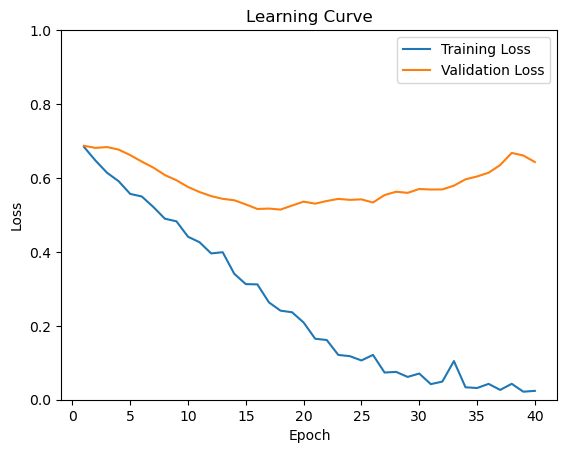

Fold 2
Accuracy Train: 0.9020192325115204. Accuracy valid: 0.7979166686534882
Recall Train: 0.8005377650260925. Recall valid: 0.6775000095367432
Precision Train: 0.9141828645020723. Precision valid: 0.6929508864879608


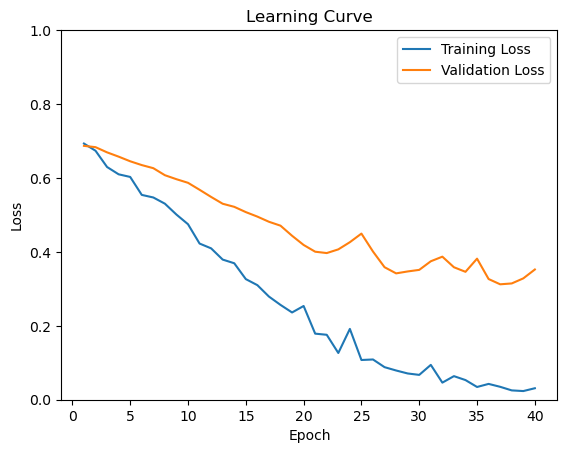

Fold 3
Accuracy Train: 0.9310216373205185. Accuracy valid: 0.7162760514765978
Recall Train: 0.8679654002189636. Recall valid: 0.7141667604446411
Precision Train: 0.9593816995620728. Precision valid: 0.6147435992956162


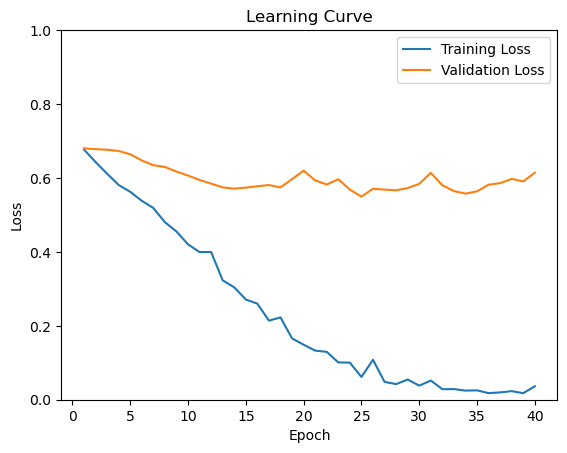

Fold 4
Accuracy Train: 0.8428125025331973. Accuracy valid: 0.7342447940260172
Recall Train: 0.9936251640319824. Recall valid: 0.9150000810623169
Precision Train: 0.8254755139350891. Precision valid: 0.7420201897621155


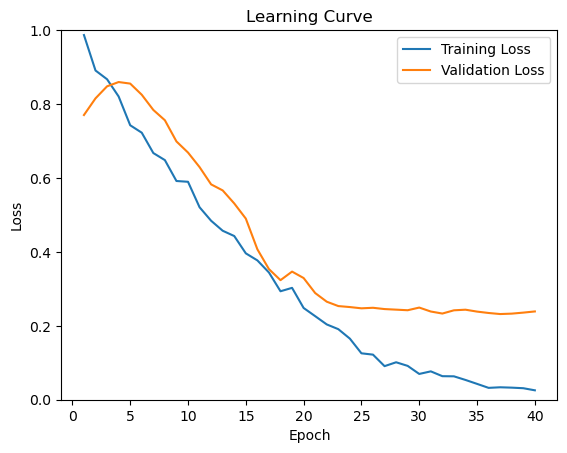

Fold 5
Accuracy Train: 0.933762022256851. Accuracy valid: 0.7145833350718022
Recall Train: 0.9267244338989258. Recall valid: 0.7591666579246521
Precision Train: 0.9401747584342957. Precision valid: 0.7025209665298462


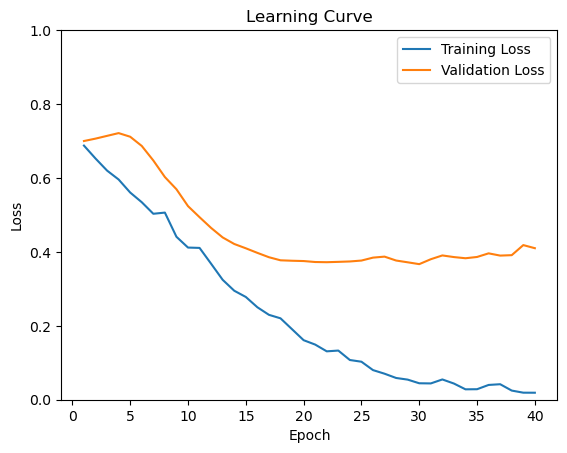

5
Fold 0: Training Loss: 0.2552138446364552, Validation Loss: 0.5846579175442457
Fold 1: Training Loss: 0.267564139701426, Validation Loss: 0.4685629142448306
Fold 2: Training Loss: 0.23220223220996558, Validation Loss: 0.5989546794444323
Fold 3: Training Loss: 0.33089634515345095, Validation Loss: 0.43361709646414964
Fold 4: Training Loss: 0.2379075712058693, Validation Loss: 0.4602261391934007
TRAIN LOSS MEDIA: 0.2647568265814334 VALID LOSS MEDIA: 0.5092037493782118
TRAIN ACC MEDIA: 0.9085897459983825 VALID ACC MEDIA: 0.722135419845581
TRAIN RECALL MEDIA: 0.898492693901062 VALID RECALL MEDIA: 0.7187024354934692
TRAIN PRECISION MEDIA: 0.9175120399147272 VALID PRECISION MEDIA: 0.6755462288856506


In [15]:
prueba_k_fold_resnet_no_pre_impr(df_mean_a, 5, 40, optim.Adam, 32, 1e-5, False, None)

Fold 1
Accuracy Train: 0.8059375029802321. Accuracy valid: 0.647265625
Recall Train: 0.7016512751579285. Recall valid: 0.5571428537368774
Precision Train: 0.8079433441162109. Precision valid: 0.4963911633938551


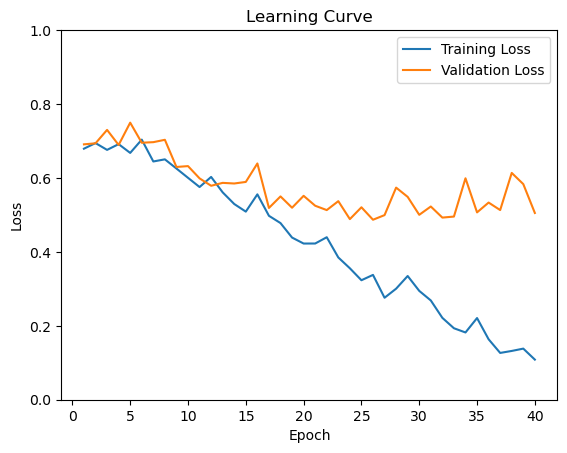

Fold 2
Accuracy Train: 0.8059976011514663. Accuracy valid: 0.7839843787252903
Recall Train: 0.6931385397911072. Recall valid: 0.67166668176651
Precision Train: 0.8543474078178406. Precision valid: 0.6852849915623664


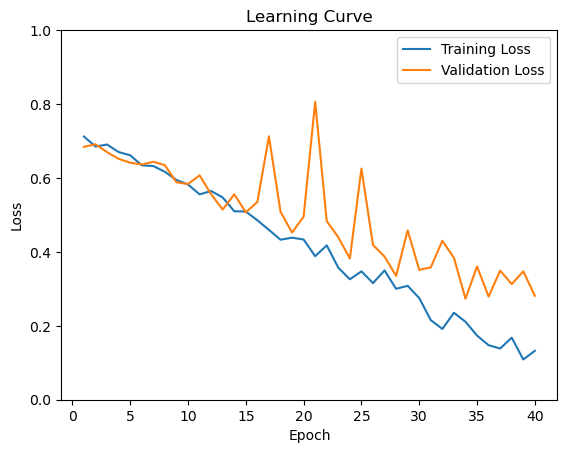

Fold 3
Accuracy Train: 0.8484495237469674. Accuracy valid: 0.7031250081956386
Recall Train: 0.7980457544326782. Recall valid: 0.7224999666213989
Precision Train: 0.8338262438774109. Precision valid: 0.6280217826366424


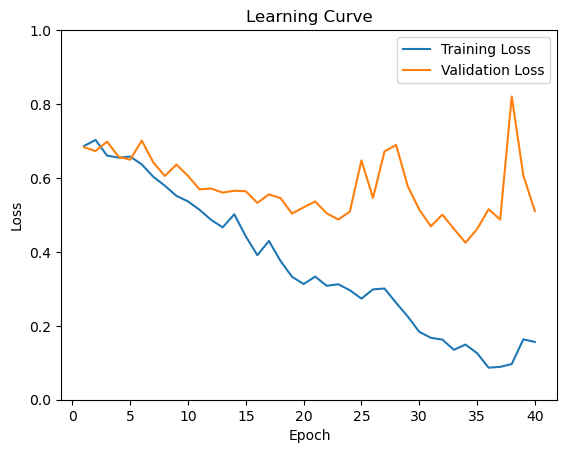

Fold 4
Accuracy Train: 0.8317427921295166. Accuracy valid: 0.7852864604443311
Recall Train: 0.7589384317398071. Recall valid: 0.7833333015441895
Precision Train: 0.8496831059455872. Precision valid: 0.7584918778389692


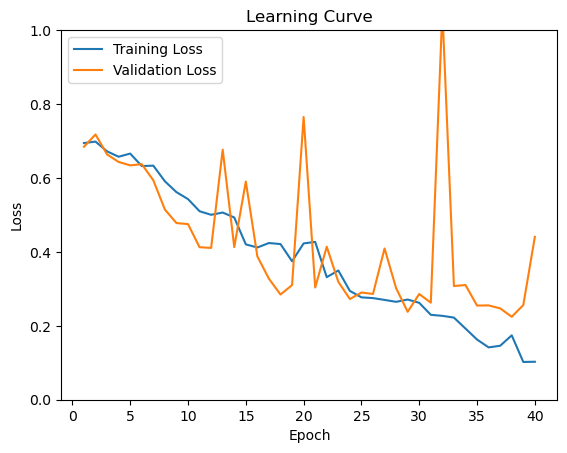

Fold 5
Accuracy Train: 0.8365144261717796. Accuracy valid: 0.7389322943985462
Recall Train: 0.751830518245697. Recall valid: 0.6791666746139526
Precision Train: 0.8602973818778992. Precision valid: 0.6656032595783472


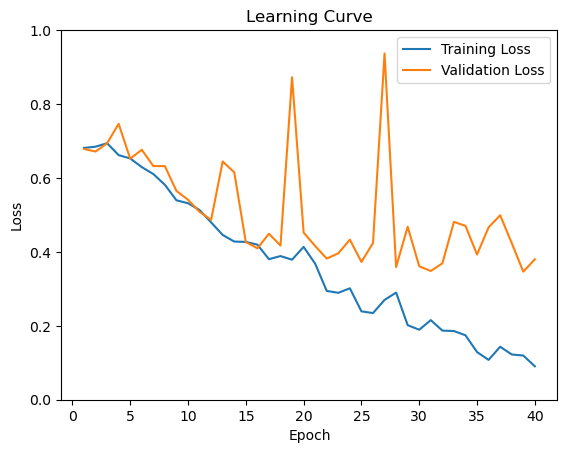

5
Fold 0: Training Loss: 0.42570962980389593, Validation Loss: 0.5797209803014993
Fold 1: Training Loss: 0.4130583366379142, Validation Loss: 0.49830438727512955
Fold 2: Training Loss: 0.36620224360376596, Validation Loss: 0.5746065676212311
Fold 3: Training Loss: 0.3889428872615099, Validation Loss: 0.4338107716641389
Fold 4: Training Loss: 0.3673679420724511, Validation Loss: 0.5124381356290542
TRAIN LOSS MEDIA: 0.3922562078759074 VALID LOSS MEDIA: 0.5197761684982106
TRAIN ACC MEDIA: 0.8257283692359925 VALID ACC MEDIA: 0.7317187533527612
TRAIN RECALL MEDIA: 0.7407209277153015 VALID RECALL MEDIA: 0.6827619671821594
TRAIN PRECISION MEDIA: 0.8412195444107056 VALID PRECISION MEDIA: 0.6467586150020361


In [16]:
prueba_k_fold_resnet_no_pre_impr(df_mean_a, 5, 40, optim.SGD, 32, 0.01, False, None)

Fold 1
Accuracy Train: 0.9447916666666666. Accuracy valid: 0.788125
Recall Train: 0.936352550983429. Recall valid: 0.7689167261123657
Precision Train: 0.9466667175292969. Precision valid: 0.7406190633773804


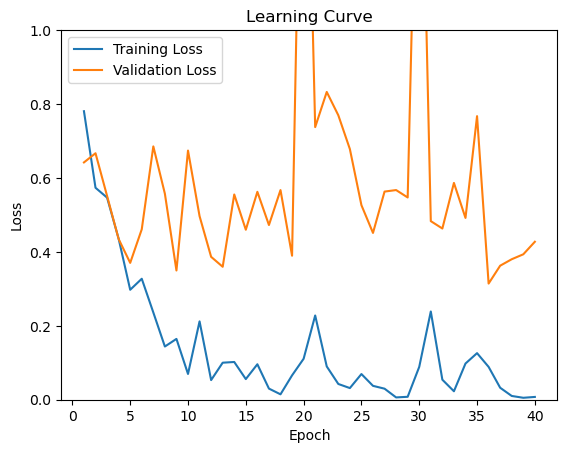

Fold 2
Accuracy Train: 0.936909722454018. Accuracy valid: 0.7829166673123836
Recall Train: 0.9338458776473999. Recall valid: 0.8287500143051147
Precision Train: 0.931597113609314. Precision valid: 0.7481666803359985


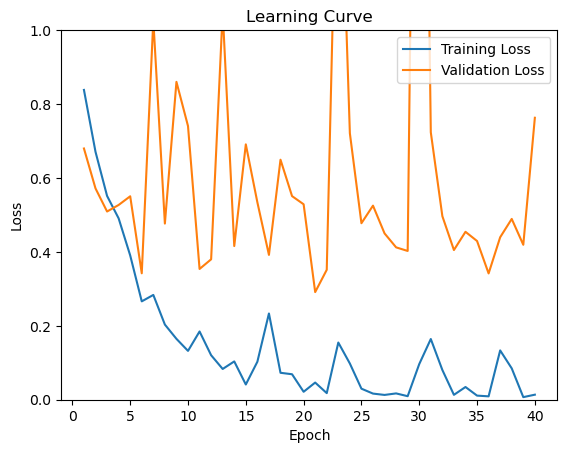

Fold 3
Accuracy Train: 0.9295138890958496. Accuracy valid: 0.7127083365619182
Recall Train: 0.9230158925056458. Recall valid: 0.5983333587646484
Precision Train: 0.9259639978408813. Precision valid: 0.5764940977096558


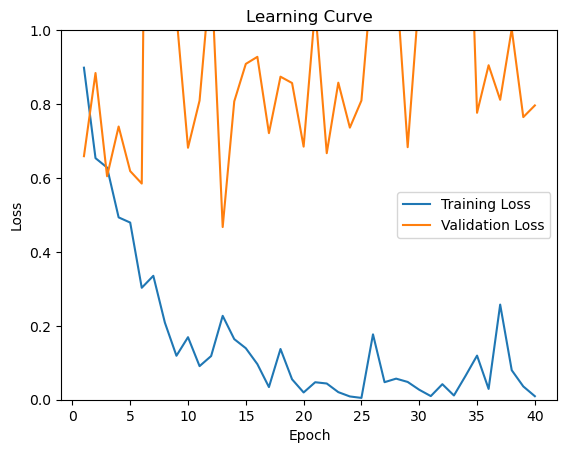

Fold 4
Accuracy Train: 0.9370486113139325. Accuracy valid: 0.786458333581686
Recall Train: 0.9263492822647095. Recall valid: 0.687749981880188
Precision Train: 0.9288657307624817. Precision valid: 0.8219702839851379


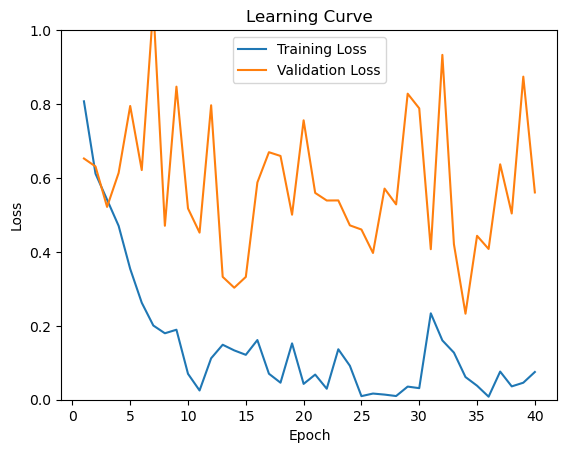

Fold 5
Accuracy Train: 0.937812500198682. Accuracy valid: 0.705208333581686
Recall Train: 0.9302793741226196. Recall valid: 0.68791663646698
Precision Train: 0.9311062097549438. Precision valid: 0.6895654797554016


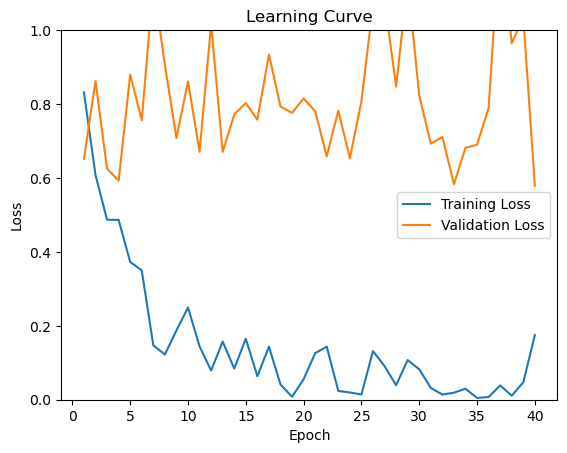

5
Fold 0: Training Loss: 0.14330971254967154, Validation Loss: 0.5967833857890218
Fold 1: Training Loss: 0.1518638888723217, Validation Loss: 0.6290819106018171
Fold 2: Training Loss: 0.1627648357534781, Validation Loss: 0.9733786987885832
Fold 3: Training Loss: 0.15016726518515497, Validation Loss: 0.5807433412941464
Fold 4: Training Loss: 0.1485044483328238, Validation Loss: 0.8153328762812816
TRAIN LOSS MEDIA: 0.15132203013869003 VALID LOSS MEDIA: 0.71906404255097
TRAIN ACC MEDIA: 0.9372152779458297 VALID ACC MEDIA: 0.7550833342075348
TRAIN RECALL MEDIA: 0.929968535900116 VALID RECALL MEDIA: 0.7143333554267883
TRAIN PRECISION MEDIA: 0.9328399896621704 VALID PRECISION MEDIA: 0.7153631448745728
Fold 1
Accuracy Train: 0.9125000032782555. Accuracy valid: 0.559375
Recall Train: 0.8966594934463501. Recall valid: 0.5526785850524902
Precision Train: 0.9248849153518677. Precision valid: 0.4810056686401367


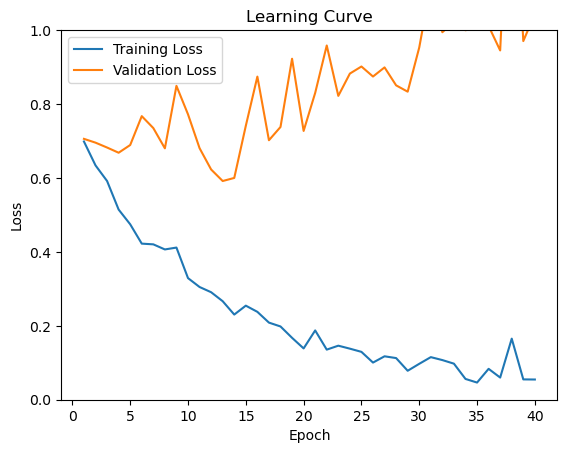

Fold 2
Accuracy Train: 0.9213341382145881. Accuracy valid: 0.8082031264901162
Recall Train: 0.9030964970588684. Recall valid: 0.7675000429153442
Precision Train: 0.9295825958251953. Precision valid: 0.7356546901166439


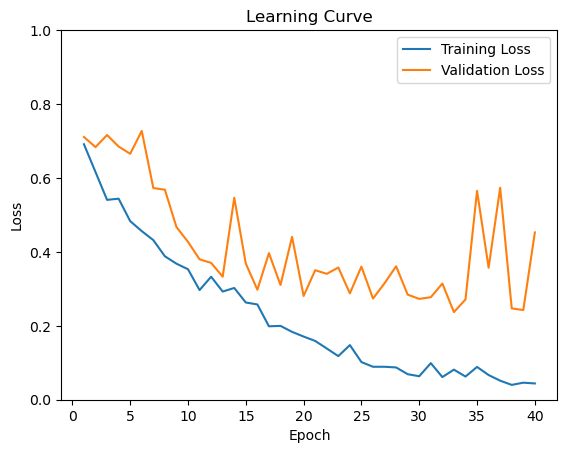

Fold 3
Accuracy Train: 0.9109014457464217. Accuracy valid: 0.7272135484963655
Recall Train: 0.8616825342178345. Recall valid: 0.6791666746139526
Precision Train: 0.9260339736938477. Precision valid: 0.6601811196655035


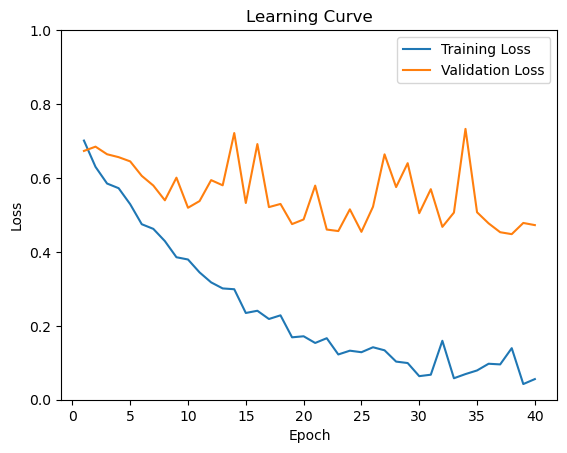

Fold 4
Accuracy Train: 0.9123798114061354. Accuracy valid: 0.8174479175359011
Recall Train: 0.8805983662605286. Recall valid: 0.8008333444595337
Precision Train: 0.9303344488143921. Precision valid: 0.86749666929245


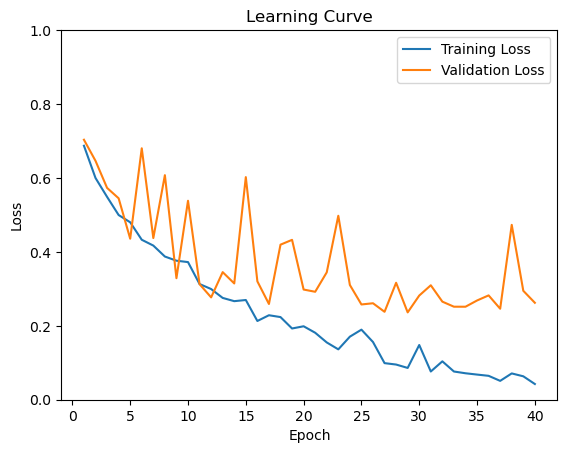

Fold 5
Accuracy Train: 0.9203245213627816. Accuracy valid: 0.7680989593267441
Recall Train: 0.9425374865531921. Recall valid: 0.8125
Precision Train: 0.9223833084106445. Precision valid: 0.7499550580978394


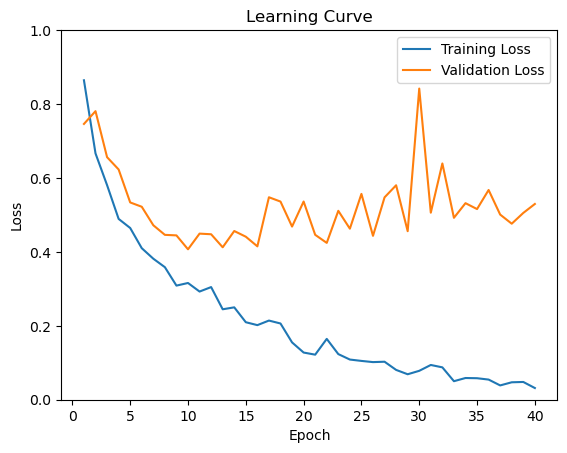

5
Fold 0: Training Loss: 0.23214552598074079, Validation Loss: 0.8489106204360723
Fold 1: Training Loss: 0.22689780853688718, Validation Loss: 0.4172258862759918
Fold 2: Training Loss: 0.24457984389737247, Validation Loss: 0.5580799620598554
Fold 3: Training Loss: 0.23470987183973194, Validation Loss: 0.3754587638977682
Fold 4: Training Loss: 0.2167787396349013, Validation Loss: 0.5219381530187093
TRAIN LOSS MEDIA: 0.23102235797792675 VALID LOSS MEDIA: 0.5443226771376795
TRAIN ACC MEDIA: 0.9154879840016366 VALID ACC MEDIA: 0.7360677103698253
TRAIN RECALL MEDIA: 0.8969148397445679 VALID RECALL MEDIA: 0.7225357294082642
TRAIN PRECISION MEDIA: 0.9266438484191895 VALID PRECISION MEDIA: 0.6988586411625147


In [17]:
prueba_k_fold_resnet_no_pre_impr(df_mean_a, 5, 40, optim.RMSprop, 8, 0.0001, False, None)
prueba_k_fold_resnet_no_pre_impr(df_mean_a, 5, 40, optim.RMSprop, 32, 1e-5, True, None)

#### CON OC SIN TL

Fold 1
Accuracy Train: 0.7321875032782554. Accuracy valid: 0.626171875
Recall Train: 0.8605419993400574. Recall valid: 0.8374999761581421
Precision Train: 0.7415496110916138. Precision valid: 0.565334141254425


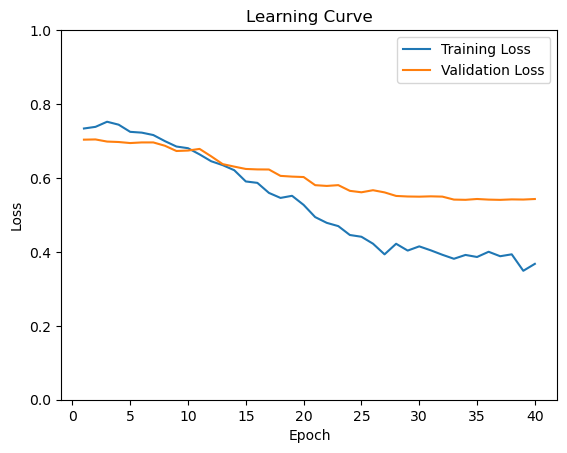

Fold 2
Accuracy Train: 0.7368509671092033. Accuracy valid: 0.7791666693985462
Recall Train: 0.5092331171035767. Recall valid: 0.5758333206176758
Precision Train: 0.7279317669570446. Precision valid: 0.6567001700401306


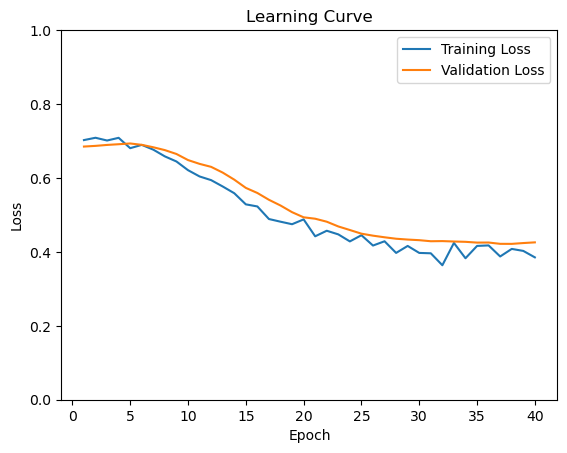

Fold 3
Accuracy Train: 0.7632692351937294. Accuracy valid: 0.6550781335681677
Recall Train: 0.8644487261772156. Recall valid: 0.8758333325386047
Precision Train: 0.7662513852119446. Precision valid: 0.6341869235038757


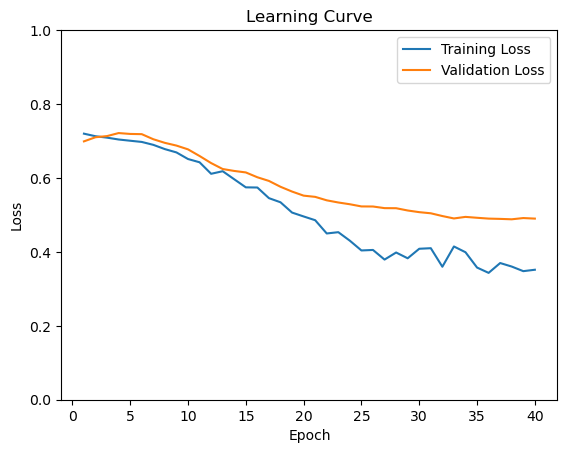

Fold 4
Accuracy Train: 0.7505769284069538. Accuracy valid: 0.8386718757450581
Recall Train: 0.7324696183204651. Recall valid: 0.8374999761581421
Precision Train: 0.7806178331375122. Precision valid: 0.8520815968513489


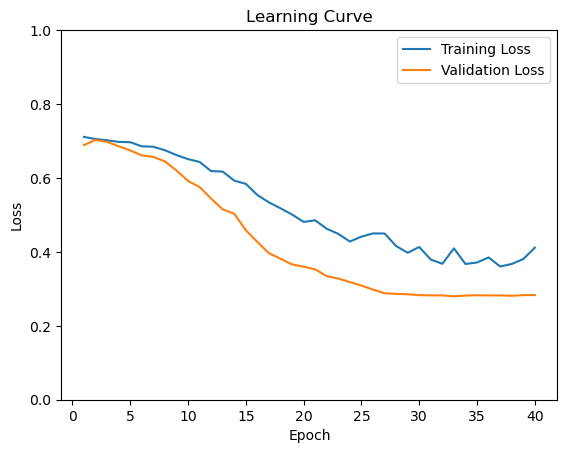

Fold 5
Accuracy Train: 0.7689783699810505. Accuracy valid: 0.6777343787252903
Recall Train: 0.7267006635665894. Recall valid: 0.5800000429153442
Precision Train: 0.7953726053237915. Precision valid: 0.5848998427391052


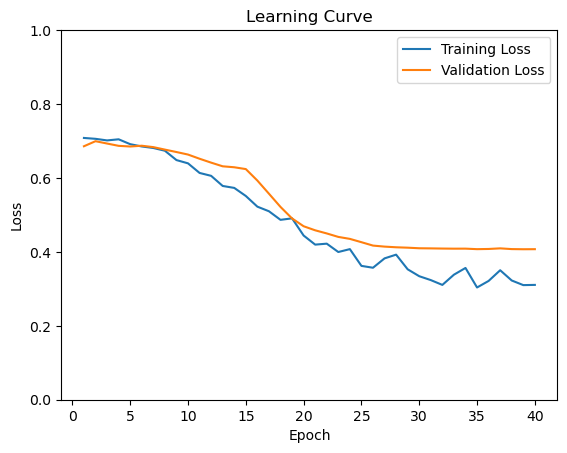

5
TRAIN LOSS MEDIA: 0.5113791257143021 VALID LOSS MEDIA: 0.5344491128996014
TRAIN ACC MEDIA: 0.7503726007938384 VALID ACC MEDIA: 0.7153645864874124
TRAIN RECALL MEDIA: 0.7386788129806519 VALID RECALL MEDIA: 0.7413333058357239
TRAIN PRECISION MEDIA: 0.7623446403443813 VALID PRECISION MEDIA: 0.6586405348777771
Fold 1
Accuracy Train: 0.9193750025331975. Accuracy valid: 0.601953125
Recall Train: 0.9241130948066711. Recall valid: 0.486607164144516
Precision Train: 0.9204074740409851. Precision valid: 0.4184398725628853


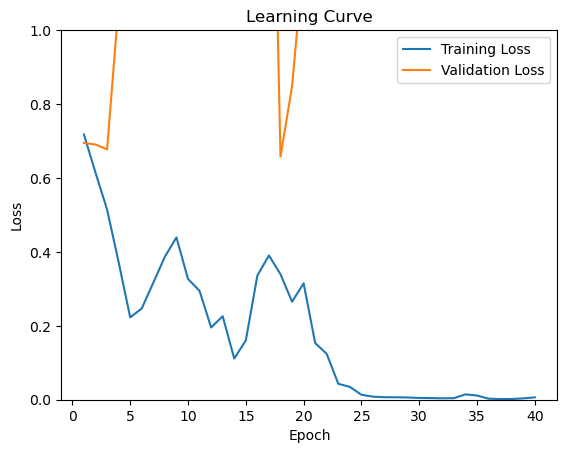

Fold 2
Accuracy Train: 0.922247600108385. Accuracy valid: 0.7617187533527613
Recall Train: 0.9197600483894348. Recall valid: 0.7991666793823242
Precision Train: 0.9229547381401062. Precision valid: 0.6808356530964375


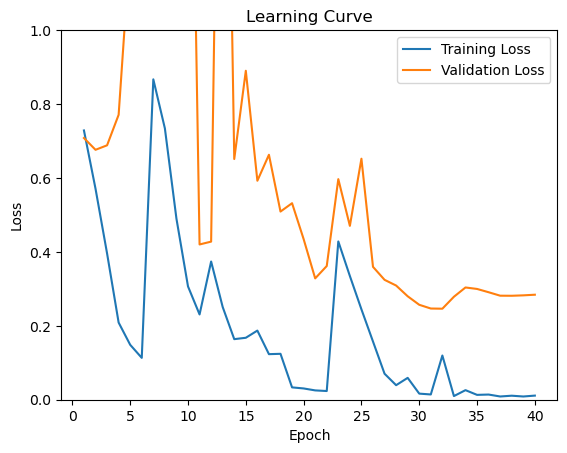

Fold 3
Accuracy Train: 0.9469831764698029. Accuracy valid: 0.6589843828231097
Recall Train: 0.929611325263977. Recall valid: 0.5466667413711548
Precision Train: 0.9532907605171204. Precision valid: 0.4531354770064354


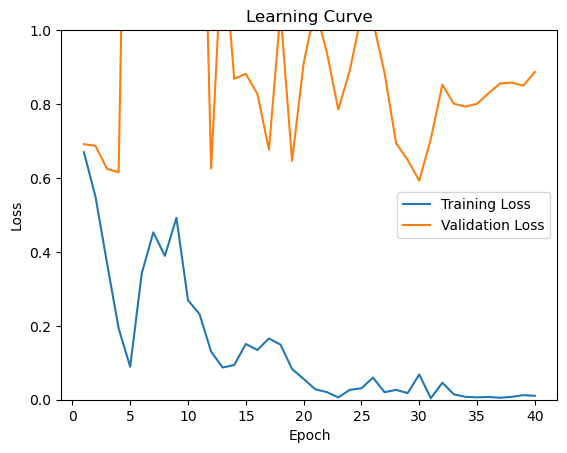

Fold 4
Accuracy Train: 0.9199278886616231. Accuracy valid: 0.8173177096992731
Recall Train: 0.8903006315231323. Recall valid: 0.7883333563804626
Precision Train: 0.9294626116752625. Precision valid: 0.7921291030943394


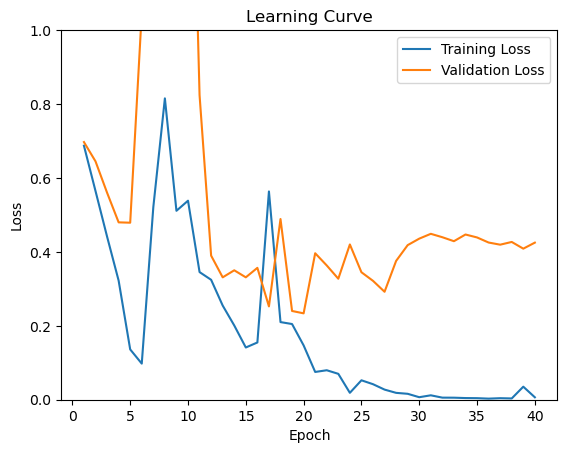

Fold 5
Accuracy Train: 0.9371875043213368. Accuracy valid: 0.7710937514901162
Recall Train: 0.927302360534668. Recall valid: 0.8591667413711548
Precision Train: 0.9466864466667175. Precision valid: 0.7532863616943359


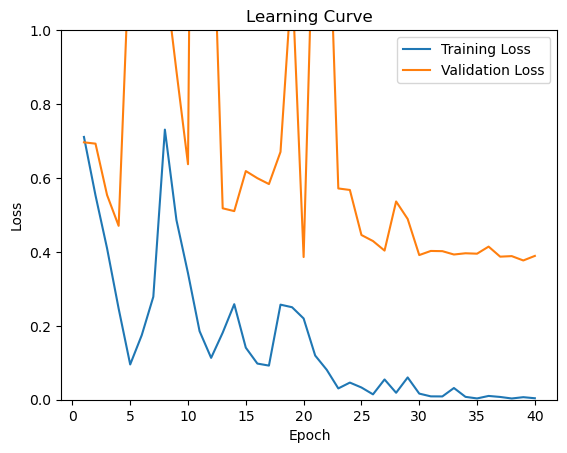

5
TRAIN LOSS MEDIA: 0.1736203380639199 VALID LOSS MEDIA: 1.3576742079239694
TRAIN ACC MEDIA: 0.929144234418869 VALID ACC MEDIA: 0.7222135444730521
TRAIN RECALL MEDIA: 0.9182174801826477 VALID RECALL MEDIA: 0.6959881782531738
TRAIN PRECISION MEDIA: 0.9345604181289673 VALID PRECISION MEDIA: 0.6195652934908866


In [18]:
prueba_k_fold_resnet_no_pre_oc_impr(df_mean_a, 5, 40, optim.Adam, 32, 1e-5, True, None)
prueba_k_fold_resnet_no_pre_oc_impr(df_mean_a, 5, 40, optim.Adam, 32, 0.001, False, None)

Fold 1
Accuracy Train: 0.900115741789341. Accuracy valid: 0.6953125
Recall Train: 0.8412912487983704. Recall valid: 0.5760416388511658
Precision Train: 0.8765365965664387. Precision valid: 0.5380839221179485


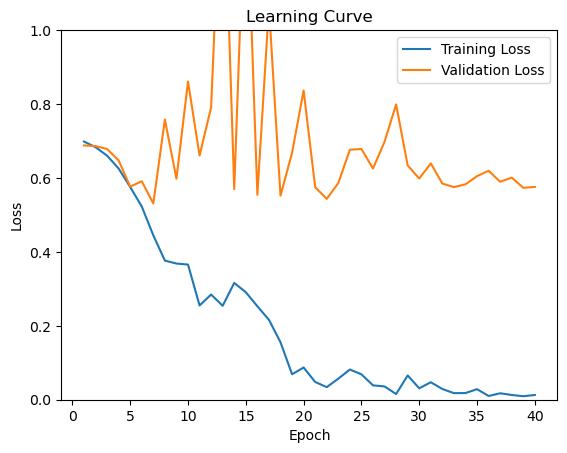

Fold 2
Accuracy Train: 0.8990251084168751. Accuracy valid: 0.7923611134290695
Recall Train: 0.8331211805343628. Recall valid: 0.8033332824707031
Precision Train: 0.8839781805872917. Precision valid: 0.71751067340374


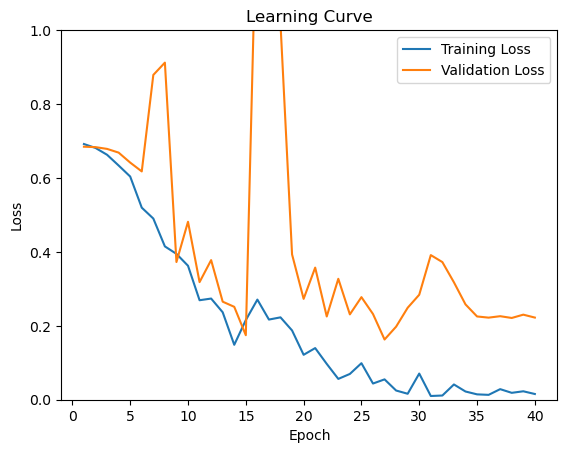

Fold 3
Accuracy Train: 0.9041533132394155. Accuracy valid: 0.751736114670833
Recall Train: 0.8377693295478821. Recall valid: 0.7013888955116272
Precision Train: 0.8713624404743314. Precision valid: 0.7026322808116674


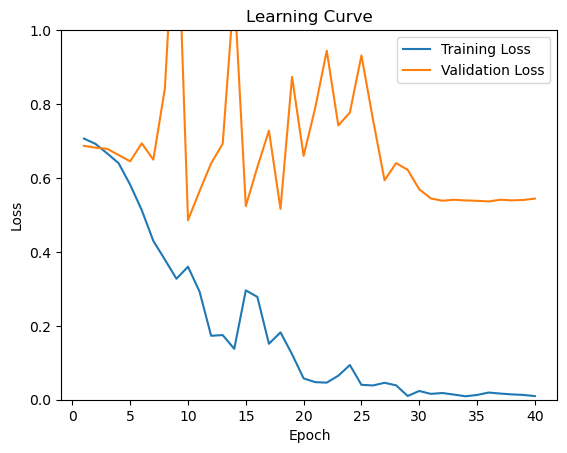

Fold 4
Accuracy Train: 0.895512821773688. Accuracy valid: 0.7956597231328487
Recall Train: 0.8284811973571777. Recall valid: 0.6462963223457336
Precision Train: 0.8587246492505074. Precision valid: 0.7969725586473941


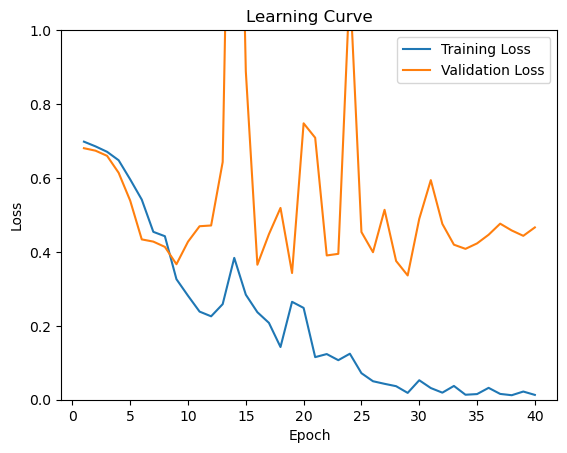

Fold 5
Accuracy Train: 0.923157052199046. Accuracy valid: 0.6857638900478682
Recall Train: 0.8843668103218079. Recall valid: 0.6748511791229248
Precision Train: 0.9352325201034546. Precision valid: 0.6793593764305115


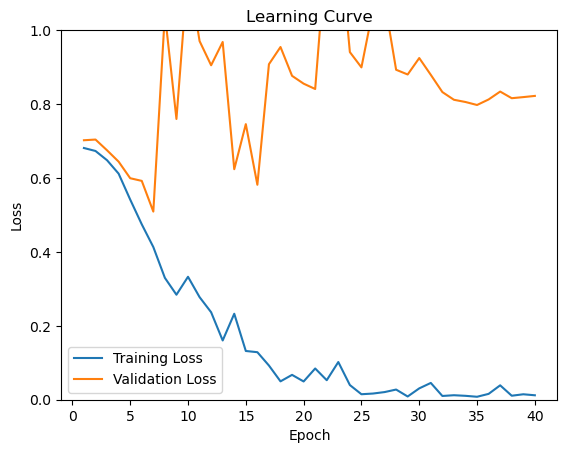

5
TRAIN LOSS MEDIA: 0.2010473431227729 VALID LOSS MEDIA: 0.6501940566964671
TRAIN ACC MEDIA: 0.9043928074836731 VALID ACC MEDIA: 0.7441666682561239
TRAIN RECALL MEDIA: 0.845005989074707 VALID RECALL MEDIA: 0.680382251739502
TRAIN PRECISION MEDIA: 0.8851668773964046 VALID PRECISION MEDIA: 0.6869117622822524


In [9]:
prueba_k_fold_resnet_no_pre_oc_impr(df_mean_a, 5, 40, optim.Adam, 16, 0.0001, True, None)

Fold 1
Accuracy Train: 0.9310763897167311. Accuracy valid: 0.7270833333333333
Recall Train: 0.8977903127670288. Recall valid: 0.6145833134651184
Precision Train: 0.9205776065587997. Precision valid: 0.6606893338263035


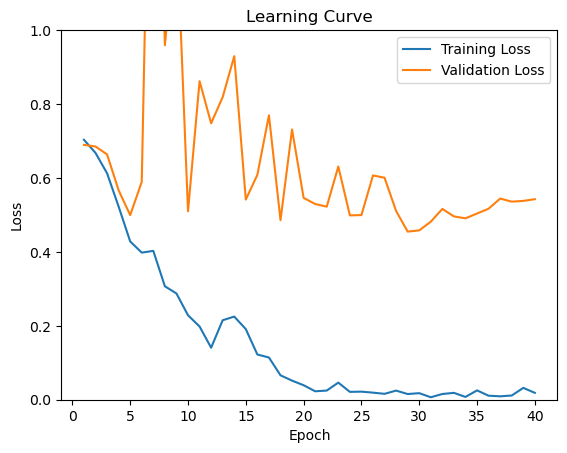

Fold 2
Accuracy Train: 0.9188969029734533. Accuracy valid: 0.7765625004967054
Recall Train: 0.9299324154853821. Recall valid: 0.8366667032241821
Precision Train: 0.9229367971420288. Precision valid: 0.747663676738739


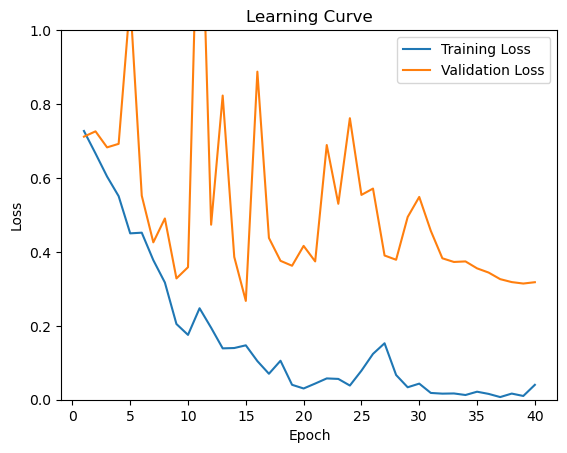

Fold 3
Accuracy Train: 0.9372462621993488. Accuracy valid: 0.7711805582046509
Recall Train: 0.9200441241264343. Recall valid: 0.6652777791023254
Precision Train: 0.9420635104179382. Precision valid: 0.7625726170837879


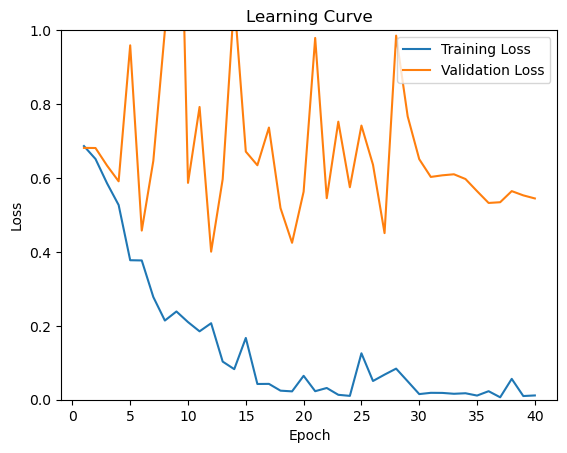

Fold 4
Accuracy Train: 0.92617521526085. Accuracy valid: 0.816666667163372
Recall Train: 0.8860565423965454. Recall valid: 0.7337962985038757
Precision Train: 0.9116435192525387. Precision valid: 0.8374275013804435


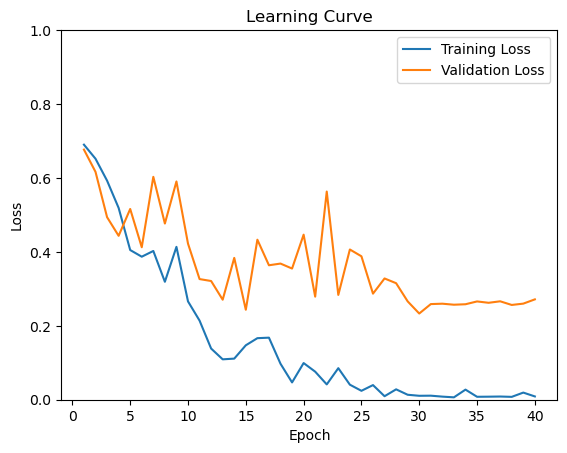

Fold 5
Accuracy Train: 0.9304487190312809. Accuracy valid: 0.7571180564661821
Recall Train: 0.8907283544540405. Recall valid: 0.7232142686843872
Precision Train: 0.916252214461565. Precision valid: 0.739977253973484


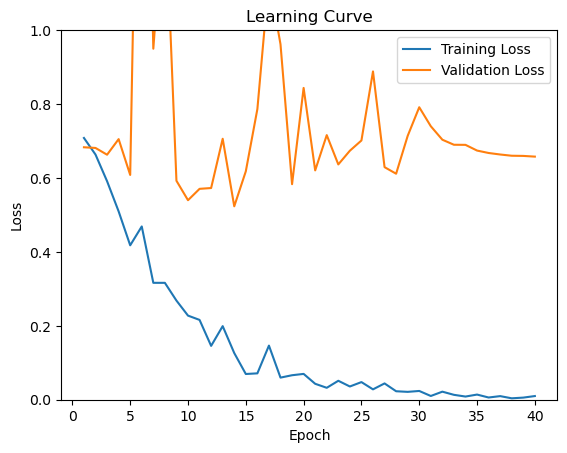

5
TRAIN LOSS MEDIA: 0.1560512412490789 VALID LOSS MEDIA: 0.5961947064209138
TRAIN ACC MEDIA: 0.9287686978363329 VALID ACC MEDIA: 0.7697222231328487
TRAIN RECALL MEDIA: 0.9049103856086731 VALID RECALL MEDIA: 0.7147076725959778
TRAIN PRECISION MEDIA: 0.9226947295665742 VALID PRECISION MEDIA: 0.7496660766005516
Fold 1
Accuracy Train: 0.9271875011920929. Accuracy valid: 0.67734375
Recall Train: 0.8821042776107788. Recall valid: 0.6848214268684387
Precision Train: 0.9275475740432739. Precision valid: 0.6374599933624268


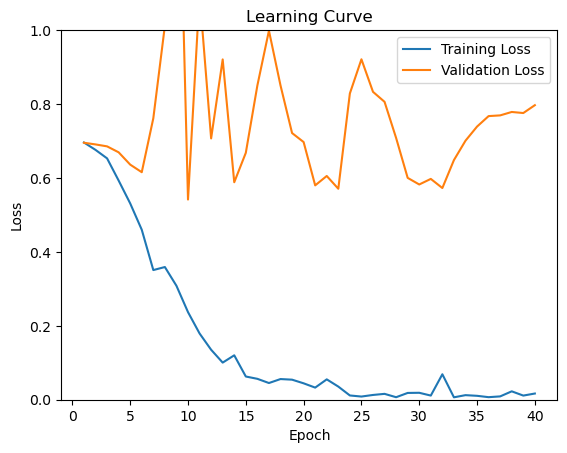

Fold 2
Accuracy Train: 0.9137500032782555. Accuracy valid: 0.7803385429084301
Recall Train: 0.9263510704040527. Recall valid: 0.9216667413711548
Precision Train: 0.9200948476791382. Precision valid: 0.7574546933174133


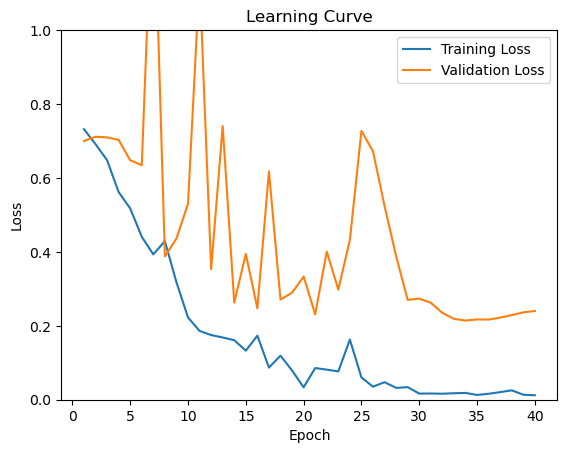

Fold 3
Accuracy Train: 0.924531252682209. Accuracy valid: 0.6542968813329935
Recall Train: 0.8723334074020386. Recall valid: 0.5391666293144226
Precision Train: 0.9133370671421289. Precision valid: 0.5616039171814918


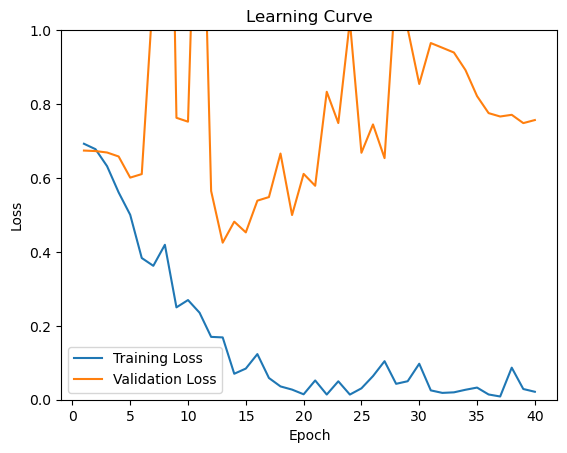

Fold 4
Accuracy Train: 0.9212259647250175. Accuracy valid: 0.8079427093267441
Recall Train: 0.9003188014030457. Recall valid: 0.8008333444595337
Precision Train: 0.9248666763305664. Precision valid: 0.8212347835302353


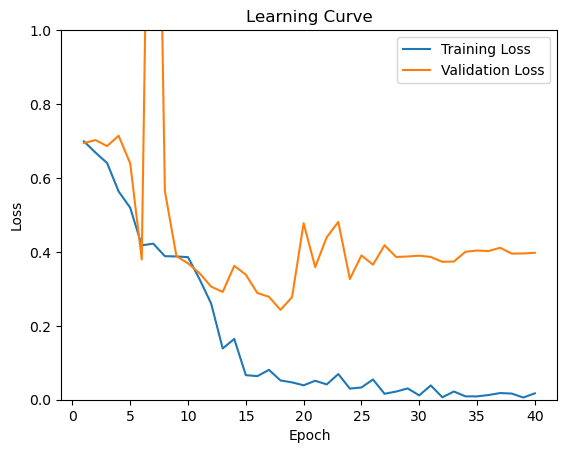

Fold 5
Accuracy Train: 0.9280168312788011. Accuracy valid: 0.7765625018626452
Recall Train: 0.8860807418823242. Recall valid: 0.7200000286102295
Precision Train: 0.9069032087922096. Precision valid: 0.7150081109255553


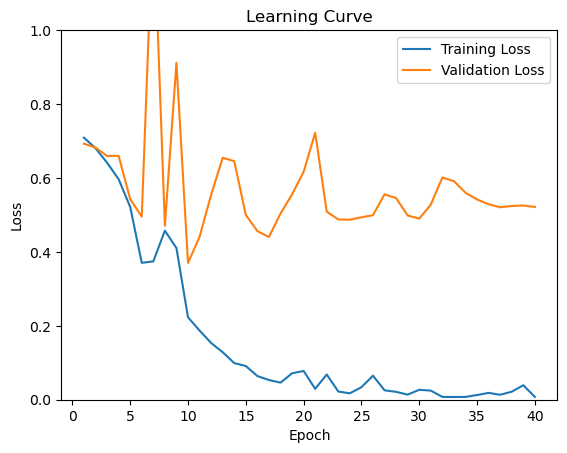

5
TRAIN LOSS MEDIA: 0.16506180556025357 VALID LOSS MEDIA: 0.6113526206989399
TRAIN ACC MEDIA: 0.9229423106312751 VALID ACC MEDIA: 0.7392968770861627
TRAIN RECALL MEDIA: 0.8934376835823059 VALID RECALL MEDIA: 0.7332977056503296
TRAIN PRECISION MEDIA: 0.9185498747974634 VALID PRECISION MEDIA: 0.6985522996634245


In [19]:
prueba_k_fold_resnet_no_pre_oc_impr(df_mean_a, 5, 40, optim.RMSprop, 16, 1e-5, True, None)
prueba_k_fold_resnet_no_pre_oc_impr(df_mean_a, 5, 40, optim.RMSprop, 32, 1e-5, True, None)

#### CON TL SIN OC

Fold 1
Accuracy Train: 0.9267708341777325. Accuracy valid: 0.628515625
Recall Train: 0.9097424745559692. Recall valid: 0.30267855525016785
Precision Train: 0.9166285395622253. Precision valid: 0.42416874654591086


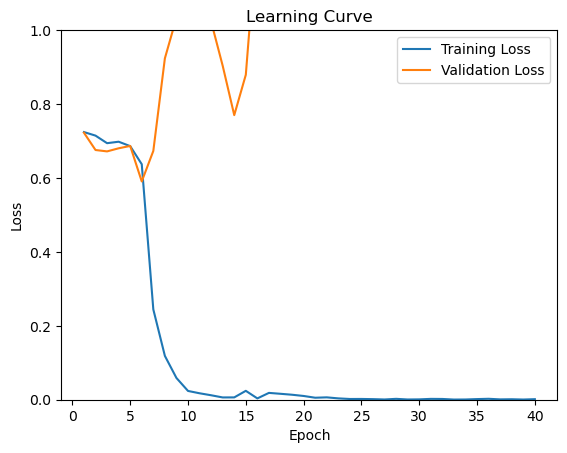

Fold 2
Accuracy Train: 0.9285216355323792. Accuracy valid: 0.8432291693985462
Recall Train: 0.9614179730415344. Recall valid: 0.9150000810623169
Precision Train: 0.9229362607002258. Precision valid: 0.8170113563537598


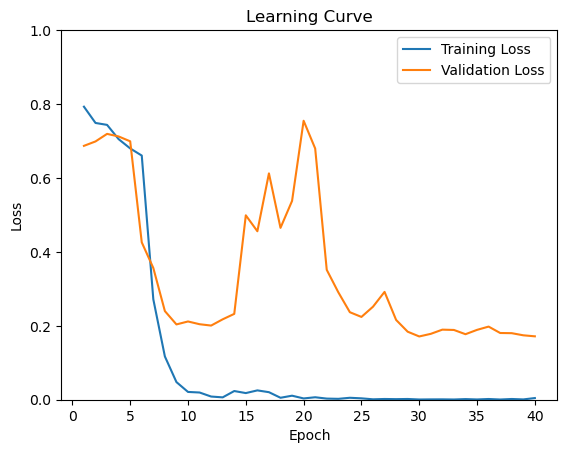

Fold 3
Accuracy Train: 0.9358052891492843. Accuracy valid: 0.7079427171498537
Recall Train: 0.9085871577262878. Recall valid: 0.7133333086967468
Precision Train: 0.9356156587600708. Precision valid: 0.6495344042778015


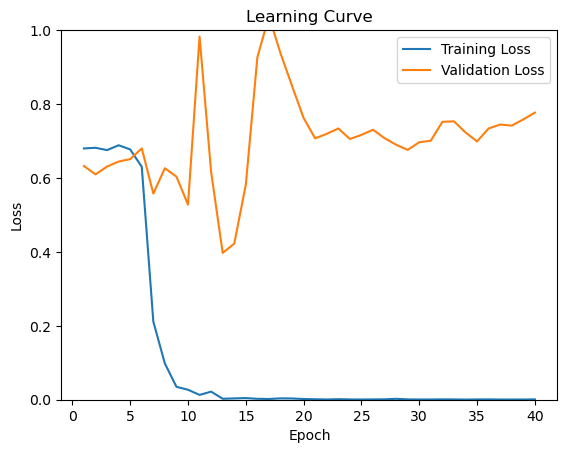

Fold 4
Accuracy Train: 0.9207451927661896. Accuracy valid: 0.792578126117587
Recall Train: 0.9122694134712219. Recall valid: 0.7166666984558105
Precision Train: 0.9150828123092651. Precision valid: 0.8238191604614258


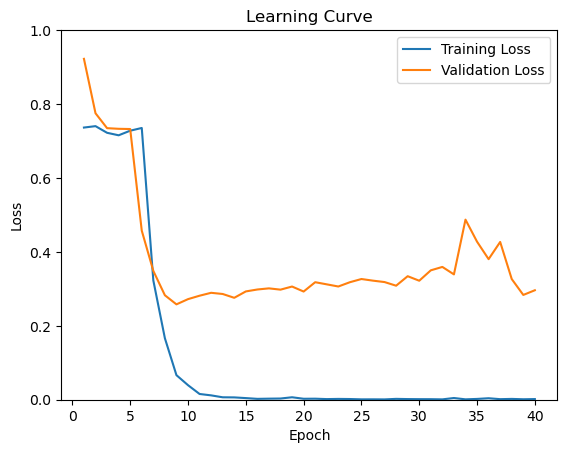

Fold 5
Accuracy Train: 0.9215865404903889. Accuracy valid: 0.7535156264901162
Recall Train: 0.8947498202323914. Recall valid: 0.7800000309944153
Precision Train: 0.9114032983779907. Precision valid: 0.7300885319709778


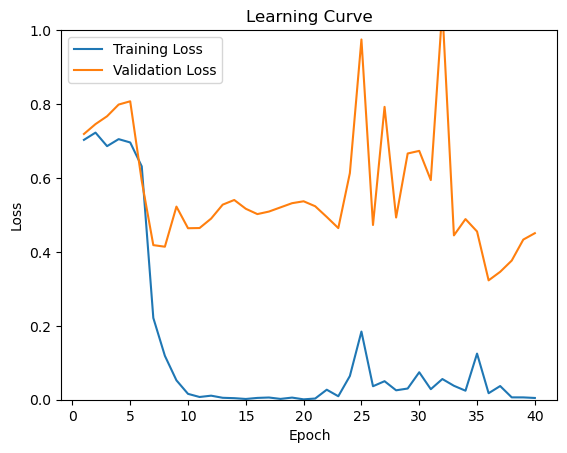

5
TRAIN LOSS MEDIA: 0.12372542228884413 VALID LOSS MEDIA: 0.6163739734038245
TRAIN ACC MEDIA: 0.9266858984231948 VALID ACC MEDIA: 0.7451562528312206
TRAIN RECALL MEDIA: 0.9173533320426941 VALID RECALL MEDIA: 0.685535728931427
TRAIN PRECISION MEDIA: 0.9203332662582397 VALID PRECISION MEDIA: 0.6889244399219752


In [22]:
prueba_k_fold_resnet_pre_impr(df_mean_a, 5, 5, 35, optim.Adam, 32, 0.0001, False, 'None')

Fold 1
Accuracy Train: 0.8572916666666668. Accuracy valid: 0.7318749999999999
Recall Train: 0.8460102081298828. Recall valid: 0.7005833387374878
Precision Train: 0.8439963459968567. Precision valid: 0.6549166440963745


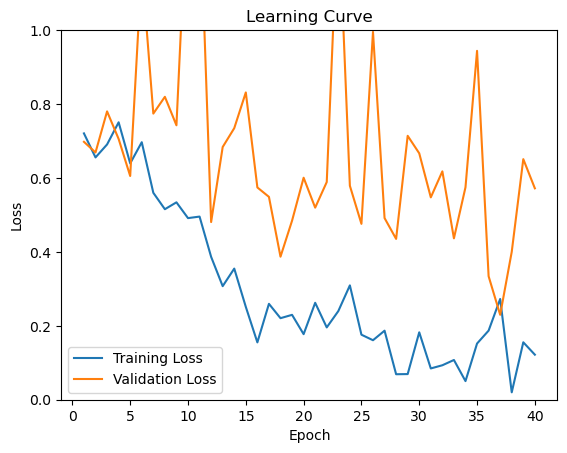

Fold 2
Accuracy Train: 0.8544097226320041. Accuracy valid: 0.8022916677594185
Recall Train: 0.8473314046859741. Recall valid: 0.824999988079071
Precision Train: 0.8383630514144897. Precision valid: 0.7839761972427368


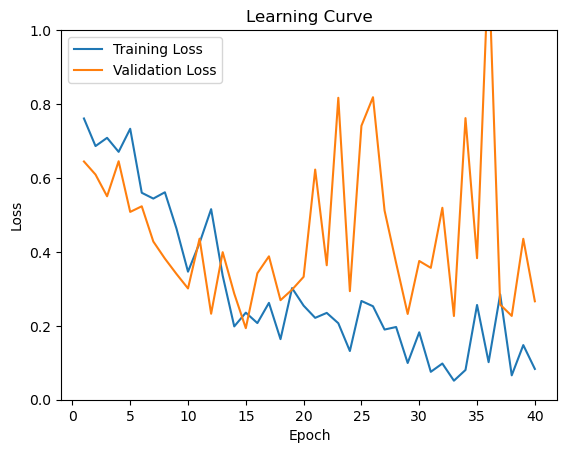

Fold 3
Accuracy Train: 0.8664236113842989. Accuracy valid: 0.6862500022351743
Recall Train: 0.8606218099594116. Recall valid: 0.659166693687439
Precision Train: 0.8346296548843384. Precision valid: 0.5727738060057164


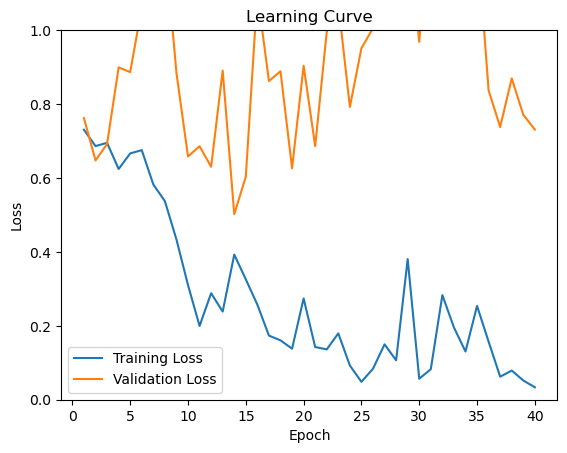

Fold 4
Accuracy Train: 0.8633680559694767. Accuracy valid: 0.7681250005960465
Recall Train: 0.8476719856262207. Recall valid: 0.7107499837875366
Precision Train: 0.8471196889877319. Precision valid: 0.7802678741514683


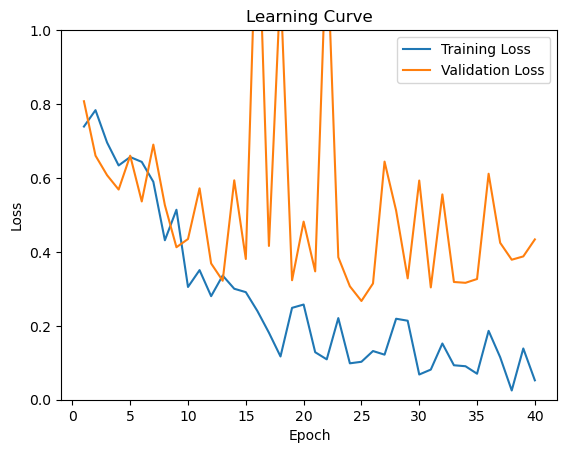

Fold 5
Accuracy Train: 0.8696875003476938. Accuracy valid: 0.7095833350718022
Recall Train: 0.8554496765136719. Recall valid: 0.7245833277702332
Precision Train: 0.8519411087036133. Precision valid: 0.6221666797995568


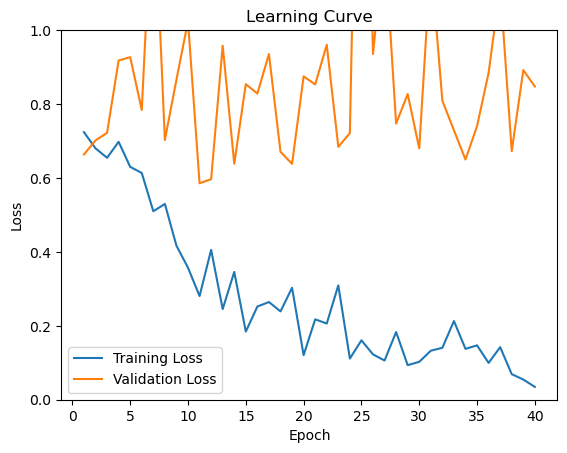

5
TRAIN LOSS MEDIA: 0.2884997920133173 VALID LOSS MEDIA: 0.6878802094118346
TRAIN ACC MEDIA: 0.8622361114000281 VALID ACC MEDIA: 0.7396250011324882
TRAIN RECALL MEDIA: 0.8514169454574585 VALID RECALL MEDIA: 0.7240167260169983
TRAIN PRECISION MEDIA: 0.8432100415229797 VALID PRECISION MEDIA: 0.6828202402591705
Fold 1
Accuracy Train: 0.8929976863165695. Accuracy valid: 0.6979166666666666
Recall Train: 0.8705183267593384. Recall valid: 0.5190972089767456
Precision Train: 0.8844234347343445. Precision valid: 0.5728541404008866


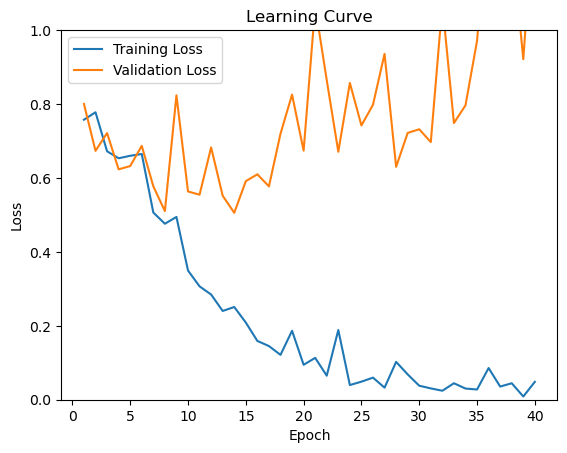

Fold 2
Accuracy Train: 0.8805021380384763. Accuracy valid: 0.8010416686534881
Recall Train: 0.8567439317703247. Recall valid: 0.8225000500679016
Precision Train: 0.8801017999649048. Precision valid: 0.7206104584038258


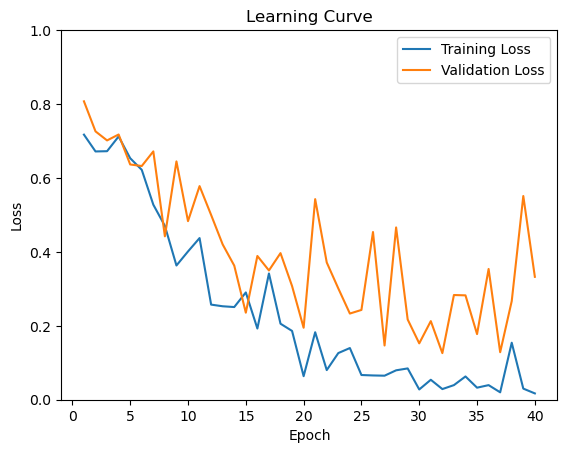

Fold 3
Accuracy Train: 0.8997462621165646. Accuracy valid: 0.6732638927797476
Recall Train: 0.8792997598648071. Recall valid: 0.7611111402511597
Precision Train: 0.8865600824356079. Precision valid: 0.6535312533378601


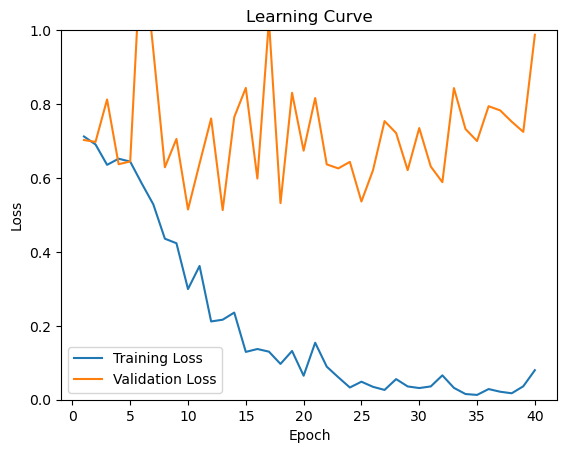

Fold 4
Accuracy Train: 0.8888621812065443. Accuracy valid: 0.8138888895511627
Recall Train: 0.8614795804023743. Recall valid: 0.7412037253379822
Precision Train: 0.8741276860237122. Precision valid: 0.8049110688269139


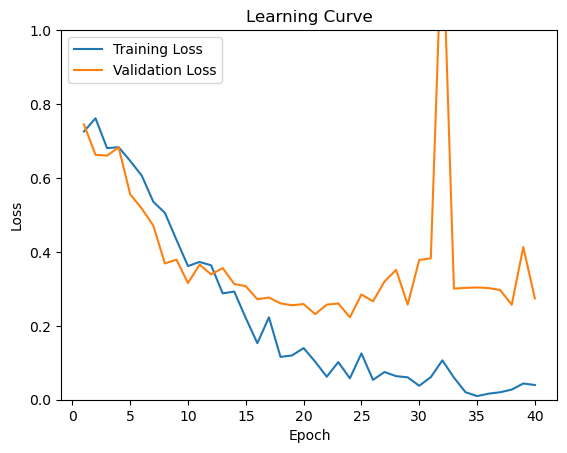

Fold 5
Accuracy Train: 0.8944177369276683. Accuracy valid: 0.7343750012417634
Recall Train: 0.8750910758972168. Recall valid: 0.7111607789993286
Precision Train: 0.8896670341491699. Precision valid: 0.7249756466597319


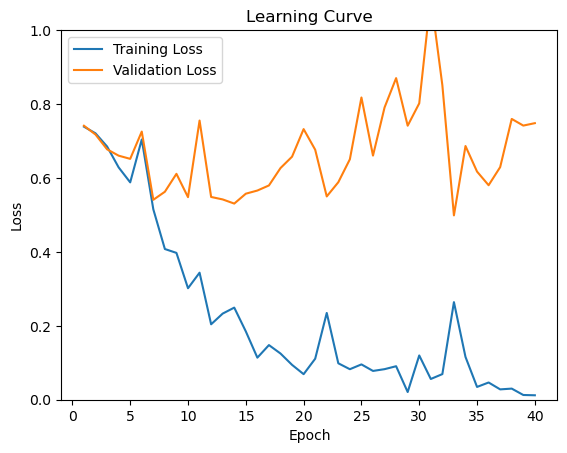

5
TRAIN LOSS MEDIA: 0.22792936363257468 VALID LOSS MEDIA: 0.5917860573382737
TRAIN ACC MEDIA: 0.8913052009211645 VALID ACC MEDIA: 0.7440972237785657
TRAIN RECALL MEDIA: 0.868626594543457 VALID RECALL MEDIA: 0.7110145688056946
TRAIN PRECISION MEDIA: 0.8829759359359741 VALID PRECISION MEDIA: 0.6953765135258436


In [23]:
prueba_k_fold_resnet_pre_impr(df_mean_a, 5, 5, 35, optim.SGD, 8, 0.01, True, 'None')
prueba_k_fold_resnet_pre_impr(df_mean_a, 5, 5, 35, optim.SGD, 16, 0.01, True, 'None')

Fold 1
Accuracy Train: 0.8990104186534881. Accuracy valid: 0.649609375
Recall Train: 0.8818250894546509. Recall valid: 0.3062500059604645
Precision Train: 0.896798312664032. Precision valid: 0.4043711841106415


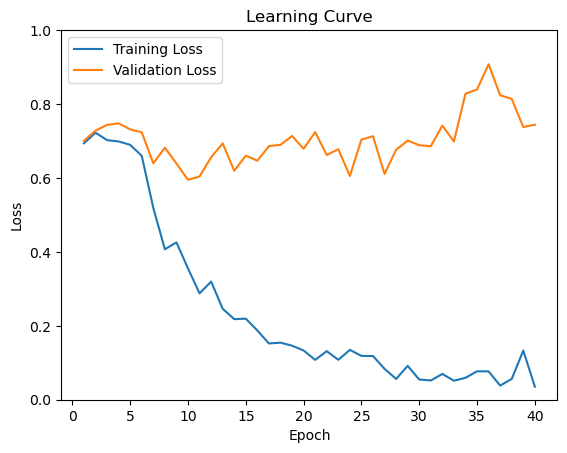

Fold 2
Accuracy Train: 0.8996274064481259. Accuracy valid: 0.880729167535901
Recall Train: 0.8466693758964539. Recall valid: 0.8925000429153442
Precision Train: 0.8878282308578491. Precision valid: 0.8517292141914368


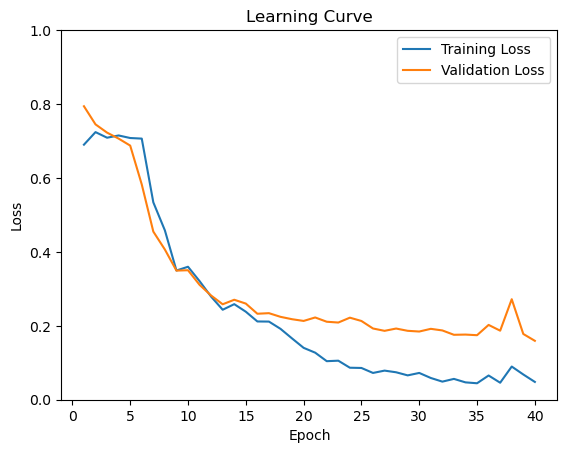

Fold 3
Accuracy Train: 0.9167067337036133. Accuracy valid: 0.7803385458886624
Recall Train: 0.9449059367179871. Recall valid: 0.7508333325386047
Precision Train: 0.9074041247367859. Precision valid: 0.7457159757614136


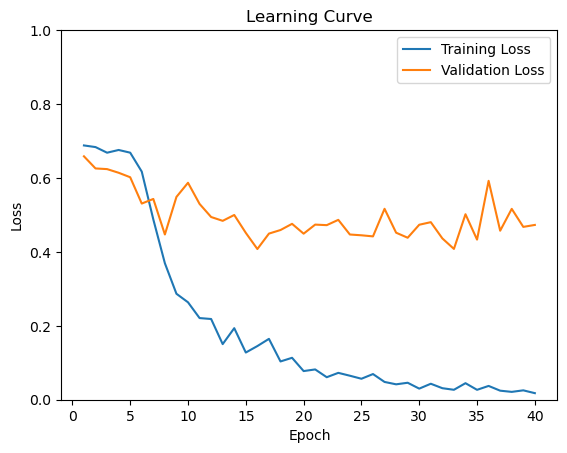

Fold 4
Accuracy Train: 0.909194714576006. Accuracy valid: 0.8307291679084301
Recall Train: 0.9184675216674805. Recall valid: 0.7783333659172058
Precision Train: 0.9014064073562622. Precision valid: 0.8331400752067566


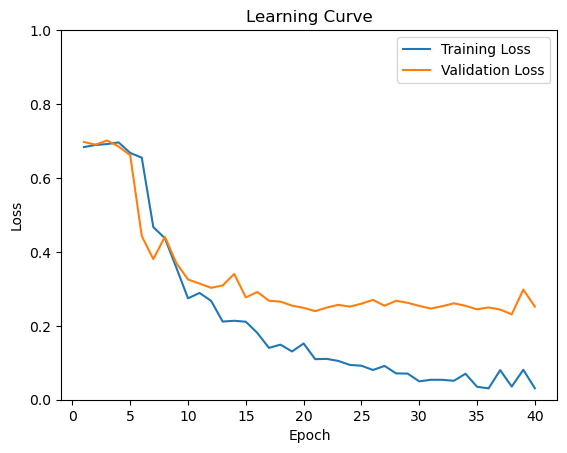

Fold 5
Accuracy Train: 0.9050841377675534. Accuracy valid: 0.7937500007450581
Recall Train: 0.9490777850151062. Recall valid: 0.8108333349227905
Precision Train: 0.9048219919204712. Precision valid: 0.7837135195732117


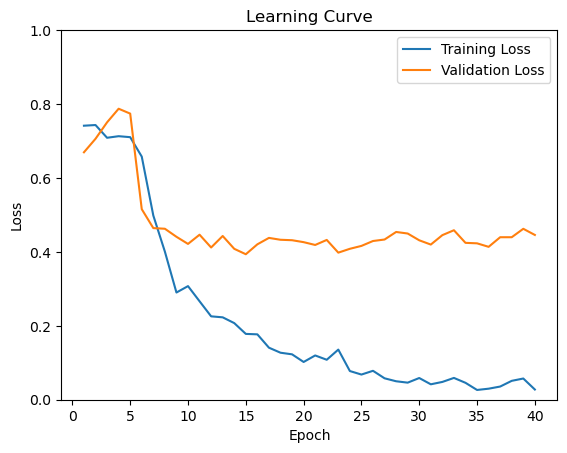

5
TRAIN LOSS MEDIA: 0.22386801246553661 VALID LOSS MEDIA: 0.462690891714301
TRAIN ACC MEDIA: 0.9059246822297574 VALID ACC MEDIA: 0.7870312514156103
TRAIN RECALL MEDIA: 0.9081891179084778 VALID RECALL MEDIA: 0.7077500224113464
TRAIN PRECISION MEDIA: 0.899651825428009 VALID PRECISION MEDIA: 0.7237339937686921
Fold 1
Accuracy Train: 0.9290104173123837. Accuracy valid: 0.661328125
Recall Train: 0.8890889883041382. Recall valid: 0.3348214626312256
Precision Train: 0.9182778596878052. Precision valid: 0.46995821595191956


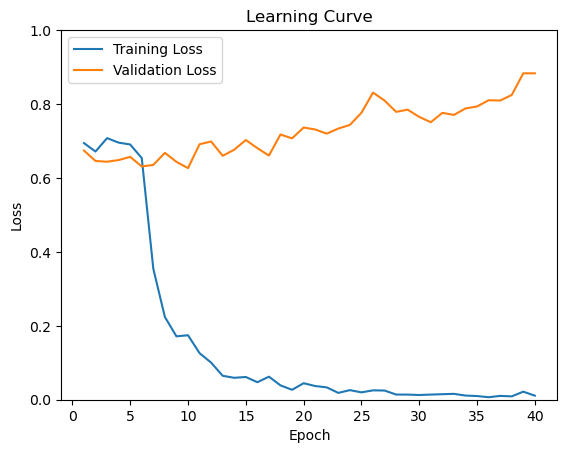

Fold 2
Accuracy Train: 0.9218870207667351. Accuracy valid: 0.8531250014901162
Recall Train: 0.9023364782333374. Recall valid: 0.7733333706855774
Precision Train: 0.9119859933853149. Precision valid: 0.8549754023551941


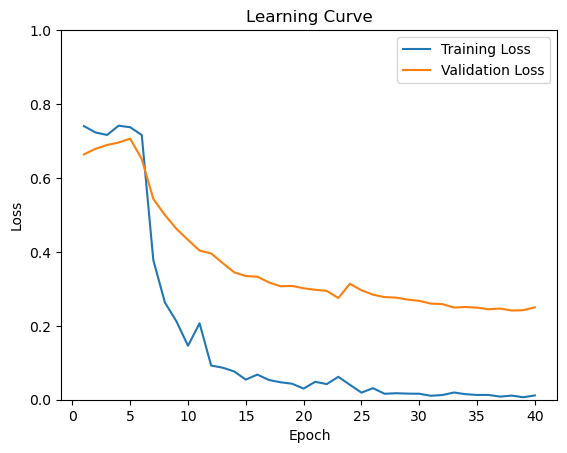

Fold 3
Accuracy Train: 0.9381370201706887. Accuracy valid: 0.7024739660322666
Recall Train: 0.9109221696853638. Recall valid: 0.7583333253860474
Precision Train: 0.9366071820259094. Precision valid: 0.6596318483352661


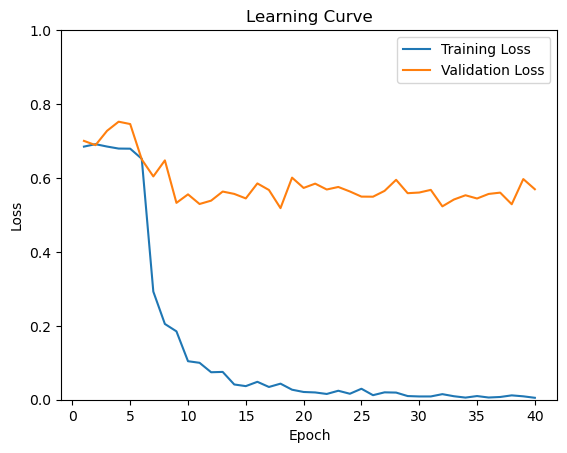

Fold 4
Accuracy Train: 0.9286057701706888. Accuracy valid: 0.8332031264901161
Recall Train: 0.8467220067977905. Recall valid: 0.6600000262260437
Precision Train: 0.8700000002980233. Precision valid: 0.8161797106266022


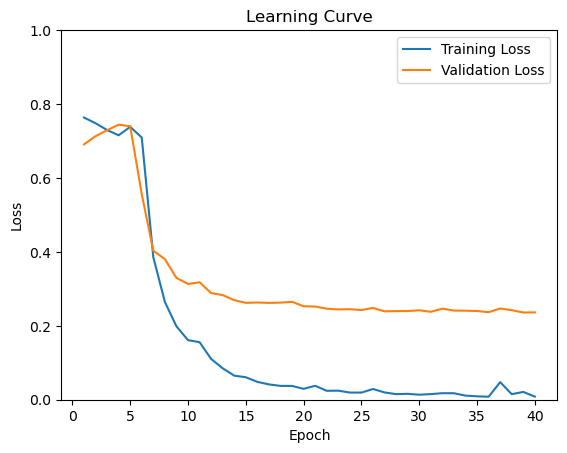

Fold 5
Accuracy Train: 0.9349278853833676. Accuracy valid: 0.80807291790843
Recall Train: 0.8804926872253418. Recall valid: 0.7016666531562805
Precision Train: 0.9340078234672546. Precision valid: 0.7641977071762085


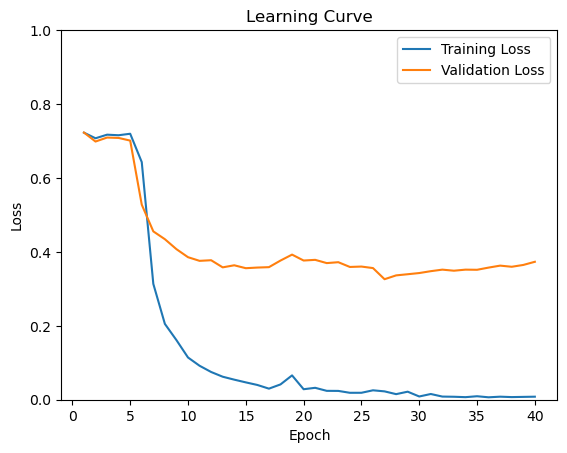

5
TRAIN LOSS MEDIA: 0.1526833902997896 VALID LOSS MEDIA: 0.48536741627380253
TRAIN ACC MEDIA: 0.9305136227607728 VALID ACC MEDIA: 0.7716406273841858
TRAIN RECALL MEDIA: 0.8859125375747681 VALID RECALL MEDIA: 0.645630955696106
TRAIN PRECISION MEDIA: 0.9141757717728615 VALID PRECISION MEDIA: 0.712988576889038


In [25]:
prueba_k_fold_resnet_pre_impr(df_mean_a, 5, 5, 35, optim.RMSprop, 32, 1e-5, True, 'None')
prueba_k_fold_resnet_pre_impr(df_mean_a, 5, 5, 35, optim.RMSprop, 32, 1e-5, False, 'None')

#### CON TL Y CON OC

Fold 1
Accuracy Train: 0.8361689827508396. Accuracy valid: 0.5614583333333334
Recall Train: 0.7136204838752747. Recall valid: 0.3597222566604614
Precision Train: 0.8530092239379883. Precision valid: 0.5218055844306946


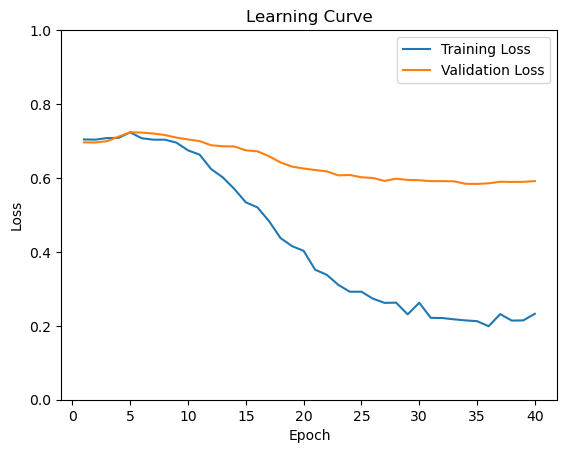

Fold 2
Accuracy Train: 0.549866455213891. Accuracy valid: 0.4272569477558136
Recall Train: 0.9934667348861694. Recall valid: 0.9941666722297668
Precision Train: 0.5182244181632996. Precision valid: 0.4267013967037201


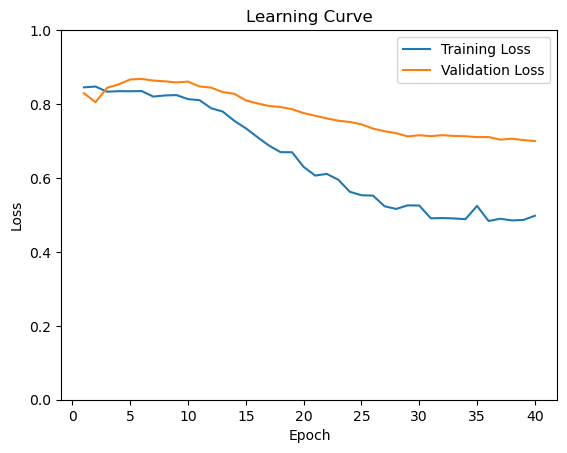

Fold 3
Accuracy Train: 0.6579460497531626. Accuracy valid: 0.39340277810891466
Recall Train: 0.5961565971374512. Recall valid: 0.25370368361473083
Precision Train: 0.6341953277587891. Precision valid: 0.3658333420753479


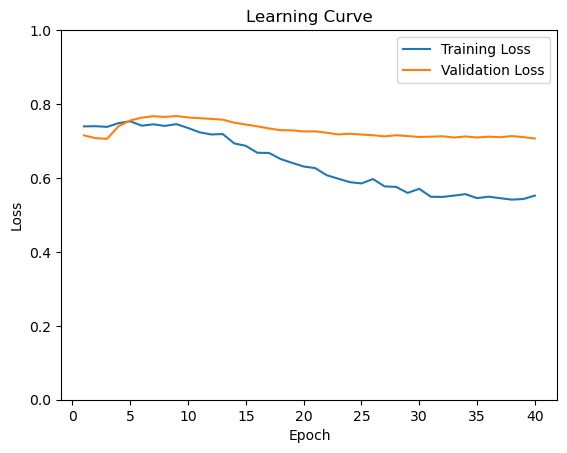

Fold 4
Accuracy Train: 0.5466212631927596. Accuracy valid: 0.5763888955116272
Recall Train: 0.0. Recall valid: 0.0
Precision Train: 0.0. Precision valid: 0.0


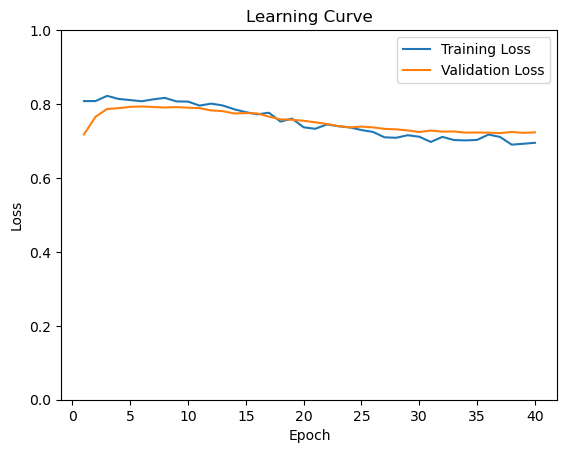

Fold 5
Accuracy Train: 0.5491185920106041. Accuracy valid: 0.4750000059604645
Recall Train: 0.4677111506462097. Recall valid: 0.4191964268684387
Precision Train: 0.5039318799972534. Precision valid: 0.3110582232475281


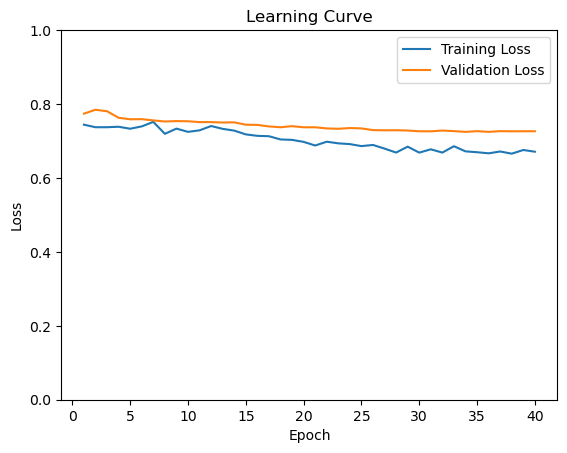

5
TRAIN LOSS MEDIA: 0.6362119387835266 VALID LOSS MEDIA: 0.7286786942183971
TRAIN ACC MEDIA: 0.6279442685842513 VALID ACC MEDIA: 0.48670139213403074
TRAIN RECALL MEDIA: 0.554190993309021 VALID RECALL MEDIA: 0.40535783767700195
TRAIN PRECISION MEDIA: 0.5018721699714661 VALID PRECISION MEDIA: 0.32507970929145813


In [26]:
prueba_k_fold_resnet_pre_oc_impr(df_mean_a, 5, 5, 35, optim.Adam, 16, 1e-5, False, 'None')

Fold 1
Accuracy Train: 0.9064236118561692. Accuracy valid: 0.6927083333333334
Recall Train: 0.8784710764884949. Recall valid: 0.44027775526046753
Precision Train: 0.9119798541069031. Precision valid: 0.601190447807312


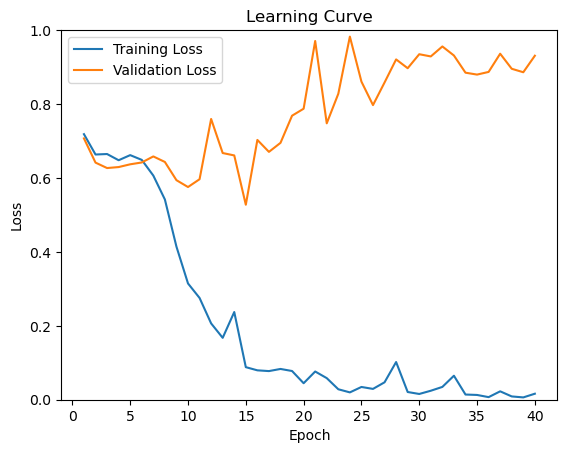

Fold 2
Accuracy Train: 0.8966613267030981. Accuracy valid: 0.85711805721124
Recall Train: 0.861279308795929. Recall valid: 0.762499988079071
Precision Train: 0.8949298858642578. Precision valid: 0.7875081300735474


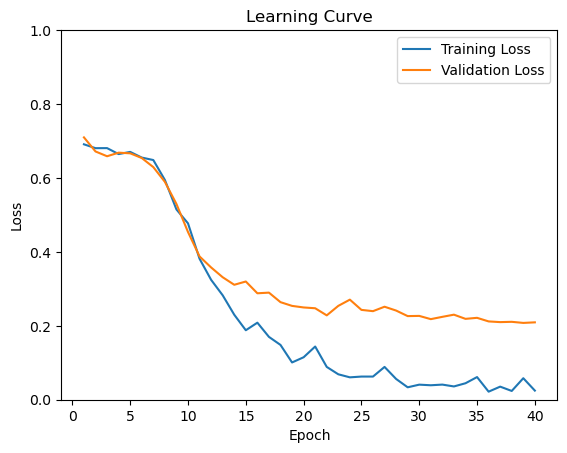

Fold 3
Accuracy Train: 0.8690705137534274. Accuracy valid: 0.6659722283482552
Recall Train: 0.8928155899047852. Recall valid: 0.7282407879829407
Precision Train: 0.8580314517021179. Precision valid: 0.6456996202468872


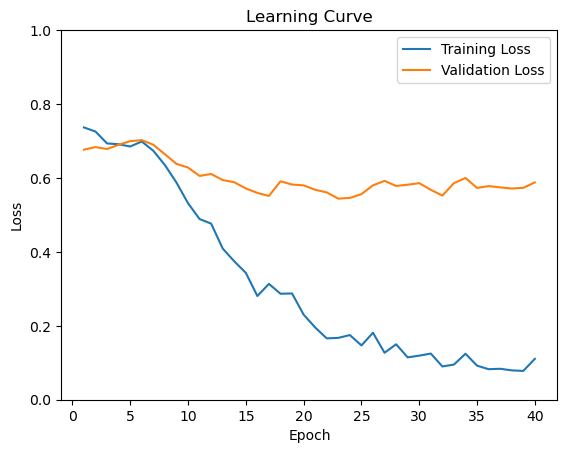

Fold 4
Accuracy Train: 0.8175347260302968. Accuracy valid: 0.790625000745058
Recall Train: 0.6837791800498962. Recall valid: 0.6148148775100708
Precision Train: 0.8580732345581055. Precision valid: 0.8567559123039246


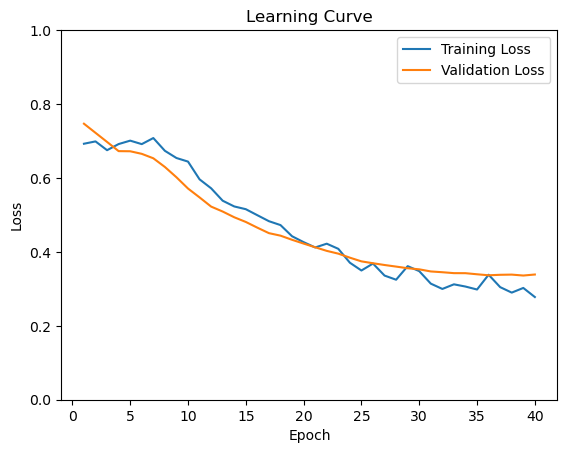

Fold 5
Accuracy Train: 0.686658656431569. Accuracy valid: 0.5585069489975771
Recall Train: 0.9211680293083191. Recall valid: 0.8392857313156128
Precision Train: 0.6270581483840942. Precision valid: 0.5186423063278198


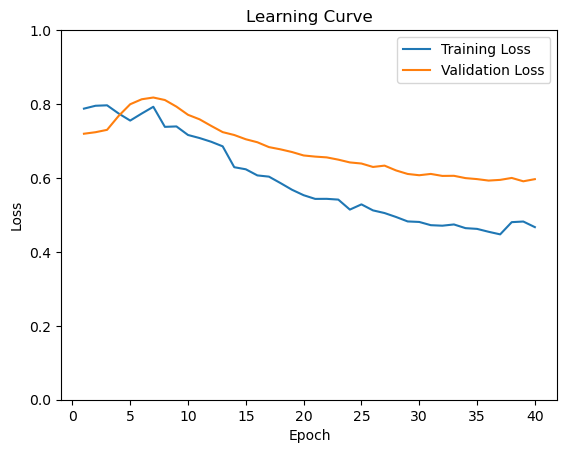

5
TRAIN LOSS MEDIA: 0.36216495503205803 VALID LOSS MEDIA: 0.5736042763851582
TRAIN ACC MEDIA: 0.8352697669549121 VALID ACC MEDIA: 0.7129861137270929
TRAIN RECALL MEDIA: 0.847502589225769 VALID RECALL MEDIA: 0.6770238876342773
TRAIN PRECISION MEDIA: 0.8300145268440247 VALID PRECISION MEDIA: 0.6819592714309692
Fold 1
Accuracy Train: 0.9138888893028101. Accuracy valid: 0.6901041666666666
Recall Train: 0.879345715045929. Recall valid: 0.42604169249534607
Precision Train: 0.9064649343490601. Precision valid: 0.6243696212768555


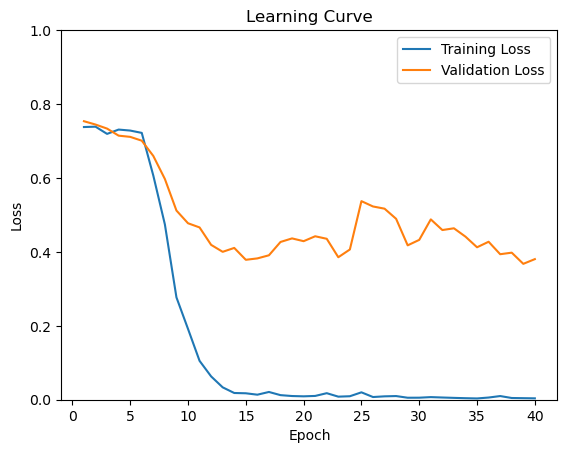

Fold 2
Accuracy Train: 0.9069711545275319. Accuracy valid: 0.8026041676600773
Recall Train: 0.879494309425354. Recall valid: 0.78083336353302
Precision Train: 0.8986629247665405. Precision valid: 0.7285202741622925


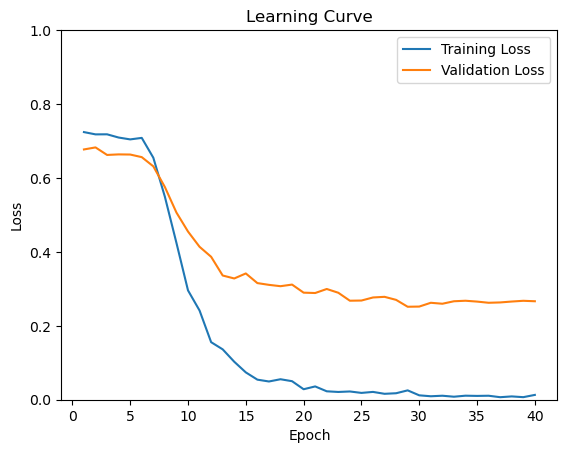

Fold 3
Accuracy Train: 0.9009615393148529. Accuracy valid: 0.6508680611848832
Recall Train: 0.8821133375167847. Recall valid: 0.6231482028961182
Precision Train: 0.8924757242202759. Precision valid: 0.6422486901283264


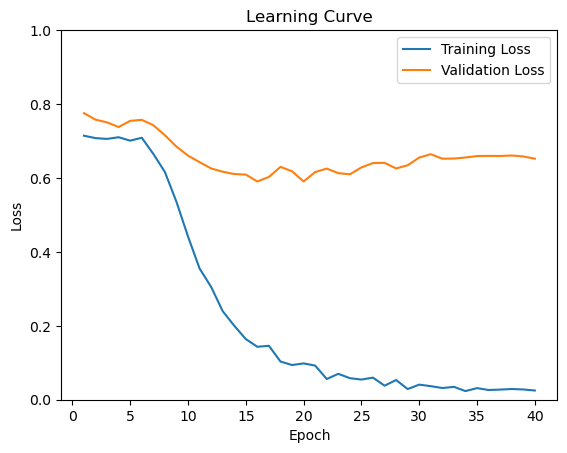

Fold 4
Accuracy Train: 0.8581997878849507. Accuracy valid: 0.7802083333333334
Recall Train: 0.7012749910354614. Recall valid: 0.5638889074325562
Precision Train: 0.8100925950333476. Precision valid: 0.822222113609314


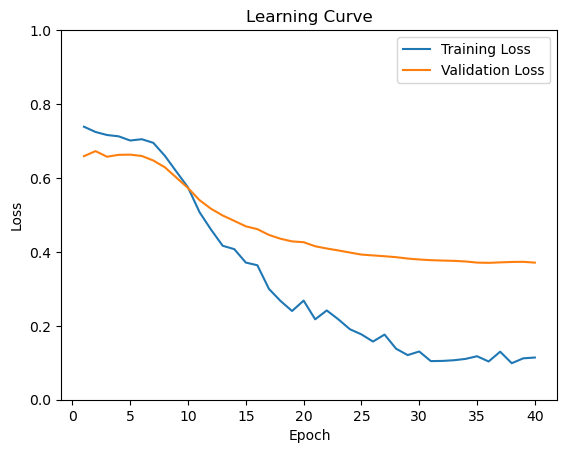

Fold 5
Accuracy Train: 0.8050080145398777. Accuracy valid: 0.5763888915379842
Recall Train: 0.9730327725410461. Recall valid: 0.820684552192688
Precision Train: 0.7567612528800964. Precision valid: 0.5405611395835876


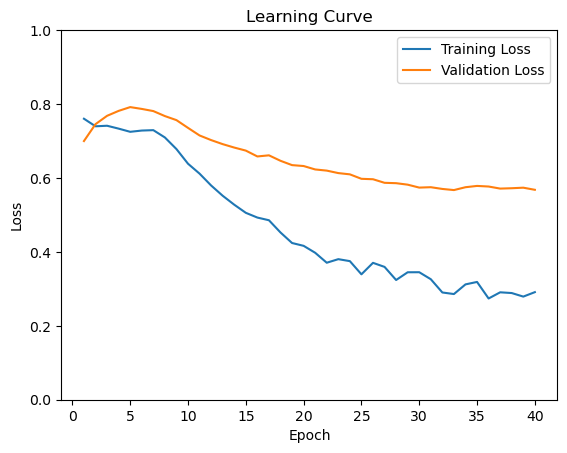

5
TRAIN LOSS MEDIA: 0.27579344252008015 VALID LOSS MEDIA: 0.5281984336922566
TRAIN ACC MEDIA: 0.8770058771140047 VALID ACC MEDIA: 0.7000347240765891
TRAIN RECALL MEDIA: 0.863052248954773 VALID RECALL MEDIA: 0.6429193615913391
TRAIN PRECISION MEDIA: 0.8528914862498642 VALID PRECISION MEDIA: 0.67158442735672


In [33]:
prueba_k_fold_resnet_pre_oc_impr(df_mean_a, 5, 5, 35, optim.RMSprop, 16, 1e-5, True, 'None')
prueba_k_fold_resnet_pre_oc_impr(df_mean_a, 5, 5, 35, optim.RMSprop, 16, 1e-5, False, 'None')